# Advanced Analytics for Decision-Making — End-Term Project
## Customer Segmentation, Profitability and Default-Risk Analysis for Indian Banking Customers
**Author:** Ojas Paradkar | PGDM E-Business (Business Analytics), WeSchool Mumbai

**How to run (Google Colab):** upload `bank_data.csv` to the Colab session (Files pane) or run the first cell and use the upload prompt. Then *Runtime → Run all*. All figures are saved to `figs/` and all result tables to `tables/`.

Workflow followed: **Data → Audit → Cleaning → EDA → Statistical testing → Modelling → Results → Interpretation → Recommendations.**

## 0. Setup
**Purpose:** install/import libraries, fix random seeds, load the data.
**Method:** `factor_analyzer` is not pre-installed in Colab, so it is installed first. A fixed `RANDOM_STATE` makes every split, cluster and model reproducible.

In [1]:
import sys, subprocess, os, warnings
try:
    import factor_analyzer  # noqa
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "factor_analyzer"])

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
import inspect
import factor_analyzer.factor_analyzer as _fa_mod
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
from sklearn.utils import check_array as _check_array
# Compatibility shim: factor_analyzer 0.5.x passes `force_all_finite`, which newer scikit-learn renamed
_NEW_SK = "ensure_all_finite" in inspect.signature(_check_array).parameters
def _check_array_compat(*a, **k):
    if _NEW_SK and "force_all_finite" in k:
        k["ensure_all_finite"] = k.pop("force_all_finite")
    return _check_array(*a, **k)
_fa_mod.check_array = _check_array_compat
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples, r2_score, mean_squared_error,
                             mean_absolute_error, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge, Lasso
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titlesize": 12,
                     "axes.labelsize": 10, "axes.titleweight": "bold"})
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("figs", exist_ok=True); os.makedirs("tables", exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(f"figs/{name}.png", bbox_inches="tight"); plt.show()

def save_table(t, name, index=True):
    t.to_csv(f"tables/{name}.csv", index=index); return t

DATA_PATH = "bank_data.csv"
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files  # only available in Colab
        up = files.upload(); DATA_PATH = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError("Place bank_data.csv in the working directory.")

df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head(3)

Shape: (3000, 62)


,Transaction_ID,Customer_ID,Transaction_Date,Bank_Name,State,City,Customer_Segment,Age,Gender,Occupation,Annual_Income_INR,Credit_Score,Customer_Tenure_Months,Primary_Account_Type,Loan_Product,Has_Credit_Card,Has_Investment_Product,Has_Insurance,Transaction_Type,Transaction_Channel,Transaction_Category,Transaction_Amount_INR,Debit_Credit,Account_Balance_Before_INR,Account_Balance_After_INR,Credit_Limit_INR,Credit_Utilization_Ratio,Outstanding_Loan_INR,Interest_Rate_Percent,EMI_Amount_INR,Debt_to_Income_Ratio,Transactions_Last_30_Days,Average_Monthly_Spend_INR,Days_Since_Last_Transaction,Mobile_App_Logins_Month,Internet_Banking_Usage,Digital_Engagement_Score,Customer_Satisfaction_Score,Complaint_Count,Device_Type,Trusted_Device,Location_Match,Transaction_Time_Risk,IP_Risk_Score,Transaction_Velocity_Score,Unusual_Amount_Score,Fraud_Risk_Score,Fraud_Flag,Investment_Value_INR,Portfolio_Return_Percent,Portfolio_Risk_Score,Customer_Lifetime_Value_INR,Revenue_Generated_INR,Cost_to_Serve_INR,Net_Profit_INR,Profitability_Score,Default_Probability,Credit_Risk_Category,Target_Default,Churn_Probability,Churn_Risk_Level,Target_Churn
0,IBT00000001,CUST00258,27-10-2025 06:47,Kotak Mahindra Bank,Karnataka,Chennai,Mass Affluent,66,Female,Student,682082,684,205,Current,Home Loan,No,Yes,Yes,NEFT,Net Banking,Food & Dining,"7,008.3300",Debit,"696,571.4800","689,563.1500",755860,0.1580,"2,087,454.5100",10.3100,"39,782.7300",0.8270,23,"107,795.0700",65,18,Medium,68.7000,2.8000,1,POS,Yes,Yes,Low,10.1000,35.5000,20.5000,17.0000,No,"448,826.7400",19.0900,10.7000,"1,478,484.5200","4,495.4000","6,646.0700","-2,150.6700",29.3000,0.3700,High,No,0.2220,Low,No
1,IBT00000002,CUST00391,14-04-2025 05:15,Canara Bank,Telangana,Jaipur,Retail,59,Female,Retired,1700434,633,63,Current,Home Loan,Yes,No,No,Bill Payment,Mobile Banking,Education,"11,546.3800",Debit,"1,034,041.9400","1,022,495.5600",412602,0.2920,"3,458,713.5700",16.8700,"61,692.8100",0.5280,26,"264,719.6000",99,17,Low,100.0000,3.4000,1,iOS,Yes,No,Low,100.0000,61.9000,55.5000,71.4000,Yes,0.0000,0.0000,0.0000,"3,079,996.4000","1,397.2400","7,946.5000","-6,549.2600",7.6000,0.3260,Medium,No,0.1520,Low,No
2,IBT00000003,CUST00795,17-09-2025 10:44,Canara Bank,Gujarat,Delhi,SME,41,Male,Student,263957,671,117,Savings,NaN,No,No,No,UPI Payment,UPI,Education,"3,255.1500",Debit,"510,521.3400","507,266.1900",624016,0.3210,"2,877.0500",0.0000,0.0000,0.1100,17,"33,365.1100",92,13,Medium,89.9000,5.0000,2,iOS,Yes,No,High,3.6000,64.8000,32.9000,47.5000,No,0.0000,0.0000,0.0000,"78,653.4500",181.5900,"3,315.0300","-3,133.4400",29.5000,0.1600,Medium,No,0.3290,Medium,No


## 1. Data Audit
### 1.1 Structure, data types and variable classification

In [2]:
ID_VARS   = ["Transaction_ID", "Customer_ID"]
DATE_VARS = ["Transaction_Date"]
num_vars  = df_raw.select_dtypes(include="number").columns.tolist()
cat_vars  = [c for c in df_raw.columns if c not in num_vars + ID_VARS + DATE_VARS]
TARGETS   = ["Net_Profit_INR", "Target_Default", "Target_Churn"]

summary = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Numerical variables", "Categorical variables", "Date variables",
               "ID variables", "Unique Transaction_IDs", "Unique Customer_IDs",
               "Exact duplicate rows", "Cells missing", "Date range"],
    "Value": [df_raw.shape[0], df_raw.shape[1], len(num_vars), len(cat_vars), len(DATE_VARS), len(ID_VARS),
              df_raw.Transaction_ID.nunique(), df_raw.Customer_ID.nunique(), int(df_raw.duplicated().sum()),
              int(df_raw.isna().sum().sum()),
              f"{pd.to_datetime(df_raw.Transaction_Date, format='%d-%m-%Y %H:%M').min():%d-%b-%Y} to "
              f"{pd.to_datetime(df_raw.Transaction_Date, format='%d-%m-%Y %H:%M').max():%d-%b-%Y}"]})
save_table(summary, "T01_dataset_summary", index=False)
print("Numerical:", num_vars); print("Categorical:", cat_vars)
summary

Numerical: ['Age', 'Annual_Income_INR', 'Credit_Score', 'Customer_Tenure_Months', 'Transaction_Amount_INR', 'Account_Balance_Before_INR', 'Account_Balance_After_INR', 'Credit_Limit_INR', 'Credit_Utilization_Ratio', 'Outstanding_Loan_INR', 'Interest_Rate_Percent', 'EMI_Amount_INR', 'Debt_to_Income_Ratio', 'Transactions_Last_30_Days', 'Average_Monthly_Spend_INR', 'Days_Since_Last_Transaction', 'Mobile_App_Logins_Month', 'Digital_Engagement_Score', 'Customer_Satisfaction_Score', 'Complaint_Count', 'IP_Risk_Score', 'Transaction_Velocity_Score', 'Unusual_Amount_Score', 'Fraud_Risk_Score', 'Investment_Value_INR', 'Portfolio_Return_Percent', 'Portfolio_Risk_Score', 'Customer_Lifetime_Value_INR', 'Revenue_Generated_INR', 'Cost_to_Serve_INR', 'Net_Profit_INR', 'Profitability_Score', 'Default_Probability', 'Churn_Probability']
Categorical: ['Bank_Name', 'State', 'City', 'Customer_Segment', 'Gender', 'Occupation', 'Primary_Account_Type', 'Loan_Product', 'Has_Credit_Card', 'Has_Investment_Product'

,Metric,Value
0,Rows,3000
1,Columns,62
2,Numerical variables,34
3,Categorical variables,25
4,Date variables,1
5,ID variables,2
6,Unique Transaction_IDs,3000
7,Unique Customer_IDs,958
8,Exact duplicate rows,0
9,Cells missing,1222


**Result.** 3,000 rows × 62 columns; 34 numeric, 25 categorical, 1 date and 2 ID variables. No exact duplicate rows and no duplicate Transaction_IDs. The only missing values are 1,222 blanks in `Loan_Product` (40.7%). Transactions run from Jan-2024 to Sep-2026.

**Business interpretation.** The file is structurally clean; the real risks are semantic (what a row represents, which fields are derived from the targets), which the next checks address.

### 1.2 Missing values

In [3]:
miss = pd.DataFrame({"Missing": df_raw.isna().sum(), "Missing_%": (df_raw.isna().mean()*100).round(2)})
miss = miss[miss.Missing > 0]
save_table(miss, "T03_missing_values")
# Investigate the business meaning of the missing Loan_Product values
lp_missing = df_raw.Loan_Product.isna()
loan_check = df_raw.groupby(lp_missing.map({True: "Loan_Product missing", False: "Loan_Product present"}))[
    ["EMI_Amount_INR", "Interest_Rate_Percent", "Outstanding_Loan_INR"]].agg(["min", "max", "mean"]).round(2)
save_table(loan_check, "T03b_loan_missing_check")
print(miss); loan_check

              Missing  Missing_%
Loan_Product     1222    40.7300


EMI_Amount_INR                          Interest_Rate_Percent                 Outstanding_Loan_INR                              
                                min          max        mean                   min     max    mean                  min            max           mean
Loan_Product                                                                                                                                         
Loan_Product missing         0.0000       0.0000      0.0000                0.0000  0.0000  0.0000              16.1200    99,955.0900    49,252.7700
Loan_Product present     1,036.9900 242,677.8900 81,939.6400                7.5000 18.0000 12.8400         100,278.9200 9,992,479.8100 4,931,325.4400

**Result.** Every record with a blank `Loan_Product` has EMI = 0 and interest rate = 0, while every record with a product has EMI ≥ ₹1,037 and a rate of 7.5–18%. The blank therefore means **"no loan"**, not unknown. It is recoded to `"No Loan"`; mode imputation (Home Loan) would have invented 1,222 fake loans.

Note: `Outstanding_Loan_INR` is small but non-zero (₹16–₹99,955) for no-loan records. What this balance represents (e.g., card or overdraft dues) cannot be established from the data and is flagged as uncertain.

### 1.3 Unit of observation — is Customer_ID a real, repeated customer?

In [4]:
tx_per_cust = df_raw.Customer_ID.value_counts()
print("Unique Customer_IDs:", tx_per_cust.size)
print(tx_per_cust.describe().round(2))
multi_ids = tx_per_cust[tx_per_cust > 1].index
g = df_raw[df_raw.Customer_ID.isin(multi_ids)].groupby("Customer_ID")
static_attrs = ["Age", "Gender", "Occupation", "Annual_Income_INR", "Credit_Score", "Customer_Tenure_Months",
                "State", "City", "Bank_Name", "Customer_Segment", "Primary_Account_Type"]
consistency = pd.DataFrame({
    "Attribute": static_attrs,
    "% of repeated Customer_IDs with >1 distinct value": [round((g[c].nunique() > 1).mean()*100, 1) for c in static_attrs]})
save_table(consistency, "T02b_customer_id_consistency", index=False)
consistency

Unique Customer_IDs: 958
count   958.0000
mean      3.1300
std       1.6600
min       1.0000
25%       2.0000
50%       3.0000
75%       4.0000
max      11.0000
Name: count, dtype: float64


,Attribute,% of repeated Customer_IDs with >1 distinct value
0,Age,99.7000
1,Gender,77.2000
2,Occupation,94.9000
3,Annual_Income_INR,100.0000
4,Credit_Score,99.9000
5,Customer_Tenure_Months,99.7000
6,State,96.5000
7,City,97.1000
8,Bank_Name,96.5000
9,Customer_Segment,84.0000


**Result.** 958 unique Customer_IDs, 1–11 rows each (mean 3.13). But for repeated IDs, age differs in 99.7% of cases, income in 100%, gender in 77.2% and state in 96.5%.

**Decision on unit of observation.** A real customer cannot change gender or age by 50 years between transactions, so `Customer_ID` is **not a reliable customer key**. Aggregating to customer level would average contradictory profiles (tested in 2.2). Each row is therefore analysed as a **customer-snapshot record** (customer attributes + one transaction). As a conservative safeguard, all train/test splits and CV folds are still **grouped by Customer_ID**, so no ID appears on both sides.

### 1.4 Class distributions of candidate targets and categorical variables

In [5]:
for c in ["Target_Default", "Target_Churn", "Fraud_Flag", "Credit_Risk_Category", "Churn_Risk_Level"]:
    print(c, df_raw[c].value_counts().to_dict())
card = pd.DataFrame({"Unique levels": df_raw[cat_vars].nunique(),
                     "Most frequent level share %": [round(df_raw[c].value_counts(normalize=True).iloc[0]*100, 1) for c in cat_vars]})
card

Target_Default {'No': 2407, 'Yes': 593}
Target_Churn {'No': 3000}
Fraud_Flag {'No': 2976, 'Yes': 24}
Credit_Risk_Category {'Medium': 1240, 'High': 1198, 'Low': 509, 'Very High': 53}
Churn_Risk_Level {'Low': 1804, 'Medium': 1193, 'High': 3}


,Unique levels,Most frequent level share %
Bank_Name,10,10.7000
State,10,10.9000
City,10,10.6000
Customer_Segment,5,54.7000
Gender,3,49.0000
Occupation,6,18.1000
Primary_Account_Type,5,49.9000
Loan_Product,5,33.2000
Has_Credit_Card,2,62.5000
Has_Investment_Product,2,56.2000


**Result.** `Target_Default`: 593 Yes (19.8%) — usable, moderately imbalanced. `Target_Churn`: 3,000 No — a **single class**, so churn cannot be modelled with logistic regression (there is nothing to discriminate). `Fraud_Flag`: 24 Yes (0.8%) — outside this project's scope and too few events for reliable modelling.

### 1.5 Constant / near-zero-variance variables and deterministic relationships

In [6]:
nzv = []
for c in df_raw.columns:
    vc = df_raw[c].value_counts(normalize=True, dropna=False)
    if vc.iloc[0] >= 0.95:
        nzv.append((c, df_raw[c].nunique(dropna=False), round(vc.iloc[0]*100, 2)))
print("Constant / near-zero variance (top level >=95%):", nzv)

# Identity checks
np_err  = (df_raw.Net_Profit_INR - (df_raw.Revenue_Generated_INR - df_raw.Cost_to_Serve_INR)).abs().max()
sign    = np.where(df_raw.Debit_Credit == "Debit", -1, 1)
bal_err = (df_raw.Account_Balance_Before_INR + sign*df_raw.Transaction_Amount_INR - df_raw.Account_Balance_After_INR).abs().max()
print(f"Net_Profit = Revenue - Cost  -> max abs error = {np_err:.2e}")
print(f"Balance_After = Balance_Before -/+ Amount -> max abs error = {bal_err:.2e}")
print("\nTransaction_Type vs Transaction_Channel (each type maps to exactly one channel):")
print((pd.crosstab(df_raw.Transaction_Type, df_raw.Transaction_Channel) > 0).sum(axis=1).to_dict())
print("\nStructural zeros for non-investors:")
print(df_raw.groupby("Has_Investment_Product")[["Investment_Value_INR", "Portfolio_Return_Percent", "Portfolio_Risk_Score"]].max())
print("\nDebt_to_Income_Ratio at its maximum value 0.95:", (df_raw.Debt_to_Income_Ratio == 0.95).sum(), "rows")

Constant / near-zero variance (top level >=95%): [('Fraud_Flag', 2, np.float64(99.2)), ('Target_Churn', 1, np.float64(100.0))]
Net_Profit = Revenue - Cost  -> max abs error = 1.82e-12
Balance_After = Balance_Before -/+ Amount -> max abs error = 4.66e-10

Transaction_Type vs Transaction_Channel (each type maps to exactly one channel):


{'Bill Payment': 1, 'Cash Withdrawal': 1, 'Credit Card': 1, 'Debit Card': 1, 'IMPS': 1, 'Investment': 1, 'Loan EMI': 1, 'NEFT': 1, 'RTGS': 1, 'UPI Payment': 1}

Structural zeros for non-investors:
                        Investment_Value_INR  Portfolio_Return_Percent  Portfolio_Risk_Score
Has_Investment_Product                                                                      
No                                    0.0000                    0.0000                0.0000
Yes                           4,991,958.2600                   58.0800              100.0000

Debt_to_Income_Ratio at its maximum value 0.95: 995 rows


**Result.**
* `Target_Churn` is constant; `Fraud_Flag` is near-zero-variance.
* `Net_Profit_INR = Revenue_Generated_INR − Cost_to_Serve_INR` exactly (max error ≈ 10⁻¹²).
* `Account_Balance_After_INR = Before ∓ Amount` exactly → redundant, dropped.
* `Transaction_Channel` is fully determined by `Transaction_Type` → redundant for modelling.
* Investment value, return and risk are structural zeros for non-investors.
* `Debt_to_Income_Ratio` is capped at 0.95 for 995 rows (33%) — a censored variable.

### 1.6 Target-leakage investigation

In [7]:
y_def = (df_raw.Target_Default == "Yes").astype(int)
leak = pd.DataFrame({
    "Check": ["ROC-AUC of Default_Probability alone for Target_Default",
              "Max Default_Probability among non-defaulters", "Min Default_Probability among defaulters",
              "Corr(Profitability_Score, Net_Profit_INR)", "Corr(Revenue_Generated_INR, Net_Profit_INR)",
              "Corr(Cost_to_Serve_INR, Net_Profit_INR)", "Target_Churn distinct classes"],
    "Result": [round(roc_auc_score(y_def, df_raw.Default_Probability), 4),
               df_raw.loc[y_def == 0, "Default_Probability"].max(), df_raw.loc[y_def == 1, "Default_Probability"].min(),
               round(df_raw.Profitability_Score.corr(df_raw.Net_Profit_INR), 3),
               round(df_raw.Revenue_Generated_INR.corr(df_raw.Net_Profit_INR), 3),
               round(df_raw.Cost_to_Serve_INR.corr(df_raw.Net_Profit_INR), 3),
               df_raw.Target_Churn.nunique()]})
save_table(leak, "T02c_leakage_checks", index=False)
crc = pd.crosstab(df_raw.Credit_Risk_Category, df_raw.Target_Default, normalize="index").mul(100).round(1)
crc["Default_Probability range"] = df_raw.groupby("Credit_Risk_Category").Default_Probability.agg(lambda s: f"{s.min():.3f}-{s.max():.3f}")
crc = crc.loc[["Low", "Medium", "High", "Very High"]]
save_table(crc, "T02d_credit_risk_category_vs_default")
display(leak); crc

,Check,Result
0,ROC-AUC of Default_Probability alone for Targe...,1.0000
1,Max Default_Probability among non-defaulters,0.4500
2,Min Default_Probability among defaulters,0.4500
3,"Corr(Profitability_Score, Net_Profit_INR)",0.8110
4,"Corr(Revenue_Generated_INR, Net_Profit_INR)",0.8820
5,"Corr(Cost_to_Serve_INR, Net_Profit_INR)",-0.4850
6,Target_Churn distinct classes,1.0000


Target_Default,No,Yes,Default_Probability range
Credit_Risk_Category,,,
Low,100.0000,0.0000,0.010-0.150
Medium,100.0000,0.0000,0.150-0.350
High,54.9000,45.1000,0.350-0.600
Very High,0.0000,100.0000,0.601-0.726


**Result — leakage confirmed.**
* **Default_Probability:** every defaulter has a value ≥ 0.45 and every non-defaulter ≤ 0.45 (ROC-AUC = 1.000). The target is simply this score above 0.45. **Excluded.**
* **Credit_Risk_Category:** a band of Default_Probability; "Low/Medium" = 0% default and "Very High" = 100%. **Excluded.**
* **Revenue / Cost_to_Serve:** arithmetic components of net profit. **Excluded** from the profit model.
* **Profitability_Score:** r = 0.81 with net profit and built from revenue/cost (r = 0.715 / −0.395). **Excluded.**
* **Target_Churn:** one class. **Not modelled.**

**Business interpretation.** Using any of these would produce near-perfect but meaningless models. That would only show how the bank's existing scores were calculated, not what drives risk or profit.

### 1.7 Variable dictionary

In [8]:
D = {  # variable: (business meaning, role, modelling treatment)
 "Transaction_ID": ("Unique transaction reference", "ID", "Excluded from analysis"),
 "Customer_ID": ("Customer reference; NOT consistent across rows (see 1.3)", "ID / grouping", "Used only as grouping key for train/test split"),
 "Transaction_Date": ("Date-time of transaction", "Date", "Converted to datetime; year/month derived for EDA only"),
 "Bank_Name": ("Bank on which record is based", "Categorical", "EDA only"),
 "State": ("Customer state", "Categorical", "EDA only (State-City pairs are internally inconsistent)"),
 "City": ("Customer city", "Categorical", "EDA only"),
 "Customer_Segment": ("Bank's own segment label (Retail/Mass Affluent/SME/HNI/Corporate)", "Categorical predictor", "One-hot (drop first)"),
 "Age": ("Customer age, years", "Numeric predictor", "Used as is"),
 "Gender": ("Customer gender", "Categorical", "EDA; excluded from credit models (fair-lending)"),
 "Occupation": ("Occupation group", "Categorical predictor", "One-hot (drop first)"),
 "Annual_Income_INR": ("Annual income, INR", "Numeric predictor", "log1p transform (skew 2.3)"),
 "Credit_Score": ("Bureau-type credit score", "Numeric predictor", "Used as is"),
 "Customer_Tenure_Months": ("Months with the bank", "Numeric predictor", "Used as is"),
 "Primary_Account_Type": ("Main account type", "Categorical predictor", "One-hot (drop first)"),
 "Loan_Product": ("Loan held; missing = no loan (EMI and rate are 0)", "Categorical predictor", "Missing recoded to 'No Loan'; one-hot"),
 "Has_Credit_Card": ("Holds a credit card", "Binary predictor", "Yes=1/No=0"),
 "Has_Investment_Product": ("Holds an investment product", "Binary predictor", "Yes=1/No=0"),
 "Has_Insurance": ("Holds insurance", "Binary predictor", "Yes=1/No=0"),
 "Transaction_Type": ("Type of this transaction", "Categorical (transaction)", "EDA only"),
 "Transaction_Channel": ("Channel of this transaction", "Categorical (transaction)", "Redundant: fully determined by Transaction_Type; EDA only"),
 "Transaction_Category": ("Merchant/spend category", "Categorical (transaction)", "EDA only"),
 "Transaction_Amount_INR": ("Amount of this transaction, INR", "Numeric", "log1p for FA; EDA"),
 "Debit_Credit": ("Direction of transaction", "Categorical (transaction)", "EDA only"),
 "Account_Balance_Before_INR": ("Balance before this transaction", "Numeric predictor", "Used as is"),
 "Account_Balance_After_INR": ("Balance after this transaction", "Derived", "Dropped: = Before -/+ Amount (exact identity)"),
 "Credit_Limit_INR": ("Credit limit; populated even without a credit card, exact meaning uncertain", "Numeric predictor", "Used as is; meaning flagged"),
 "Credit_Utilization_Ratio": ("Share of credit limit used", "Numeric predictor", "Used as is"),
 "Outstanding_Loan_INR": ("Outstanding loan/borrowing; small non-zero values for no-loan customers (meaning uncertain)", "Numeric predictor", "Used as is"),
 "Interest_Rate_Percent": ("Loan interest rate; 0 if no loan", "Numeric predictor", "Used as is"),
 "EMI_Amount_INR": ("Monthly EMI; 0 if no loan", "Numeric predictor", "Used in tree models; dropped in LR (VIF)"),
 "Debt_to_Income_Ratio": ("Debt burden relative to income; capped at 0.95", "Numeric predictor", "Used as is; cap noted"),
 "Transactions_Last_30_Days": ("Transaction count in last 30 days", "Numeric predictor", "Used as is"),
 "Average_Monthly_Spend_INR": ("Average monthly spend, INR", "Numeric predictor", "log1p transform"),
 "Days_Since_Last_Transaction": ("Recency, days", "Numeric predictor", "Used as is"),
 "Mobile_App_Logins_Month": ("Mobile app logins per month", "Numeric predictor", "Used as is"),
 "Internet_Banking_Usage": ("Net-banking usage level", "Ordinal predictor", "Low=1, Medium=2, High=3"),
 "Digital_Engagement_Score": ("Composite digital score (0-100)", "Numeric predictor", "Used as is"),
 "Customer_Satisfaction_Score": ("Satisfaction rating (1-5)", "Numeric predictor", "Used as is"),
 "Complaint_Count": ("Number of complaints", "Numeric predictor", "Used as is"),
 "Device_Type": ("Device used for this transaction", "Categorical (transaction)", "EDA only"),
 "Trusted_Device": ("Transaction from trusted device", "Binary (transaction)", "EDA only"),
 "Location_Match": ("Transaction location matches profile", "Binary (fraud feature)", "Out of scope (fraud)"),
 "Transaction_Time_Risk": ("Risk level of transaction time", "Categorical (fraud feature)", "Out of scope (fraud)"),
 "IP_Risk_Score": ("IP risk score", "Numeric (fraud feature)", "Out of scope (fraud)"),
 "Transaction_Velocity_Score": ("Velocity score", "Numeric (fraud feature)", "Out of scope (fraud)"),
 "Unusual_Amount_Score": ("Unusual amount score", "Numeric (fraud feature)", "Out of scope (fraud)"),
 "Fraud_Risk_Score": ("Composite fraud score", "Numeric (fraud feature)", "Out of scope (fraud)"),
 "Fraud_Flag": ("Fraud label (24 Yes)", "Target (not studied)", "Out of scope: 0.8% positives"),
 "Investment_Value_INR": ("Value of investments; 0 if no product", "Numeric predictor", "log1p transform"),
 "Portfolio_Return_Percent": ("Portfolio return %; 0 if no product", "Numeric predictor", "Used as is"),
 "Portfolio_Risk_Score": ("Portfolio risk; 0 if no product", "Numeric predictor", "Used as is"),
 "Customer_Lifetime_Value_INR": ("Bank-computed lifetime value, INR", "Derived metric", "Supplementary target; log1p"),
 "Revenue_Generated_INR": ("Revenue from customer, INR", "Component of target", "Excluded as predictor (identity)"),
 "Cost_to_Serve_INR": ("Cost of serving customer, INR", "Component of target", "Excluded as predictor (identity)"),
 "Net_Profit_INR": ("Revenue minus cost, INR", "TARGET (regression)", "Target of Problem B"),
 "Profitability_Score": ("Score built from revenue/cost (r=0.81 with profit)", "Derived from target", "Excluded (leakage)"),
 "Default_Probability": ("Pre-computed default probability", "Derived from target", "Excluded (leakage: Default=Yes iff >0.45)"),
 "Credit_Risk_Category": ("Band of Default_Probability", "Derived from target", "Excluded (leakage)"),
 "Target_Default": ("Default status", "TARGET (classification)", "Yes=1/No=0; target of Problem C"),
 "Churn_Probability": ("Pre-computed churn probability", "Derived score", "Not used as predictor"),
 "Churn_Risk_Level": ("Band of churn probability", "Derived score", "Not used as predictor"),
 "Target_Churn": ("Churn status - all 'No'", "Invalid target", "Excluded: only one class"),
}
dict_df = pd.DataFrame([{"Variable": v, "Data Type": str(df_raw[v].dtype).replace("str", "object"),
                         "Business Meaning": D[v][0], "Missing Values": int(df_raw[v].isna().sum()),
                         "Role": D[v][1], "Modelling Treatment": D[v][2]} for v in df_raw.columns])
save_table(dict_df, "T02_variable_dictionary", index=False)
dict_df

,Variable,Data Type,Business Meaning,Missing Values,Role,Modelling Treatment
0,Transaction_ID,object,Unique transaction reference,0,ID,Excluded from analysis
1,Customer_ID,object,Customer reference; NOT consistent across rows...,0,ID / grouping,Used only as grouping key for train/test split
2,Transaction_Date,object,Date-time of transaction,0,Date,Converted to datetime; year/month derived for ...
3,Bank_Name,object,Bank on which record is based,0,Categorical,EDA only
4,State,object,Customer state,0,Categorical,EDA only (State-City pairs are internally inco...
...,...,...,...,...,...,...
57,Credit_Risk_Category,object,Band of Default_Probability,0,Derived from target,Excluded (leakage)
58,Target_Default,object,Default status,0,TARGET (classification),Yes=1/No=0; target of Problem C
59,Churn_Probability,float64,Pre-computed churn probability,0,Derived score,Not used as predictor
60,Churn_Risk_Level,object,Band of churn probability,0,Derived score,Not used as predictor


**Purpose.** A documented role and treatment for every one of the 62 variables. Meanings that the data cannot confirm (Credit_Limit for non-card holders, Outstanding_Loan for non-borrowers) are explicitly marked uncertain.

## 2. Data Preparation
### 2.1 Type correction, missing-value treatment, encoding (df_clean)

In [9]:
df_clean = df_raw.copy()
df_clean["Transaction_Date"] = pd.to_datetime(df_clean.Transaction_Date, format="%d-%m-%Y %H:%M")
df_clean["Txn_Year"] = df_clean.Transaction_Date.dt.year
df_clean["Loan_Product"] = df_clean.Loan_Product.fillna("No Loan")        # business-meaning imputation
df_clean["Has_Loan"] = (df_clean.Loan_Product != "No Loan").astype(int)
for c in ["Has_Credit_Card", "Has_Investment_Product", "Has_Insurance", "Trusted_Device", "Location_Match"]:
    df_clean[c + "_bin"] = (df_clean[c] == "Yes").astype(int)
df_clean["Default"] = (df_clean.Target_Default == "Yes").astype(int)
df_clean["IB_Usage_Ord"] = df_clean.Internet_Banking_Usage.map({"Low": 1, "Medium": 2, "High": 3})
for c in ["Annual_Income_INR", "Average_Monthly_Spend_INR", "Transaction_Amount_INR",
          "Investment_Value_INR", "Customer_Lifetime_Value_INR"]:
    df_clean["log_" + c] = np.log1p(df_clean[c])
df_clean = df_clean.drop(columns=["Account_Balance_After_INR"])  # exact identity, redundant
for c in cat_vars:
    if c in df_clean: df_clean[c] = df_clean[c].astype("category")
print("df_clean shape:", df_clean.shape, "| missing cells:", int(df_clean.isna().sum().sum()))

df_clean shape: (3000, 75) | missing cells: 0


**Method.** Date parsed to datetime; `Loan_Product` blanks → "No Loan"; Yes/No flags → 0/1; `Internet_Banking_Usage` → ordinal 1–3 (it has a natural order, so one column instead of dummies); five right-skewed money variables (skew 1.1–5.0) get a `log1p` version for linear models, FA and clustering; the redundant balance-after column is dropped. Categorical predictors are later one-hot encoded with an explicit reference level (k−1 dummies) only where used, to avoid dummy explosion. Result: `df_clean` has 0 missing cells.

### 2.2 Customer-level aggregation test (df_customer)

In [10]:
df_customer = (df_clean.groupby("Customer_ID")
               .agg(n_txn=("Transaction_ID", "count"), total_amount=("Transaction_Amount_INR", "sum"),
                    mean_net_profit=("Net_Profit_INR", "mean"), any_default=("Default", "max"),
                    age_min=("Age", "min"), age_max=("Age", "max"), n_genders=("Gender", "nunique"),
                    income_min=("Annual_Income_INR", "min"), income_max=("Annual_Income_INR", "max")))
multi = df_customer[df_customer.n_txn > 1]
print("Customer-level rows:", len(df_customer))
print(f"Repeated IDs whose age range > 5 yrs: {((multi.age_max-multi.age_min)>5).mean()*100:.1f}%")
print(f"Repeated IDs with >1 gender: {(multi.n_genders>1).mean()*100:.1f}%")
print(f"Repeated IDs where max income > 2x min income: {((multi.income_max/multi.income_min)>2).mean()*100:.1f}%")
default_consistency = df_clean[df_clean.Customer_ID.isin(multi_ids)].groupby("Customer_ID").Default.nunique().gt(1).mean()
print(f"Repeated IDs with conflicting default status: {default_consistency*100:.1f}%")
df_customer.head()

Customer-level rows: 958
Repeated IDs whose age range > 5 yrs: 93.5%
Repeated IDs with >1 gender: 77.2%
Repeated IDs where max income > 2x min income: 77.6%
Repeated IDs with conflicting default status: 50.3%


,n_txn,total_amount,mean_net_profit,any_default,age_min,age_max,n_genders,income_min,income_max
Customer_ID,,,,,,,,,
CUST00001,5,"23,677.5500","3,309.5880",1,22,74,2,450141,1639724
CUST00002,2,"5,927.7000","10,029.4900",1,41,46,2,365294,1060161
CUST00003,2,"5,624.9400","5,689.5900",0,21,25,1,1116337,2167535
CUST00004,5,"40,930.4200","2,593.6320",0,26,66,2,597951,1078546
CUST00005,2,"5,605.1900","-1,475.0750",0,48,56,2,729424,768936


**Result.** At customer level, 93.5% of repeated IDs have ages more than 5 years apart, 77.2% have more than one gender, 77.6% have income varying by >2×, and 50.3% have *both* default and non-default rows.

**Decision.** `df_customer` is built but **not used for modelling**. Its "customers" would be blends of unrelated profiles, and the default target would be undefined for half of them. Modelling stays at record level with customer-grouped splitting (Section 6.1).

### 2.3 Outlier investigation

Portfolio_Return IQR outliers among investors only: 7


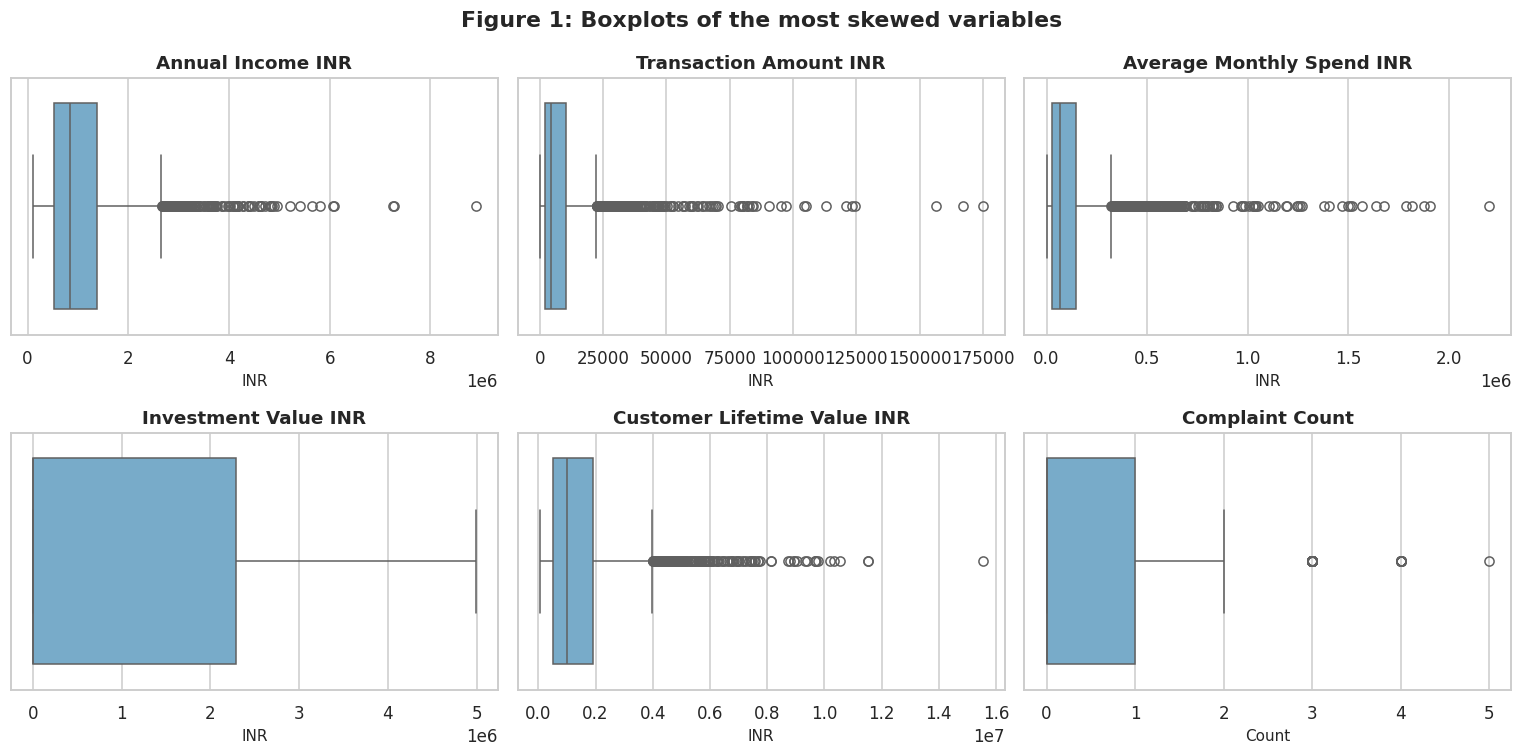

,Variable,Skewness,Min,P99,Max,IQR outliers,|z|>3
0,Annual_Income_INR,2.2700,"108,607.0000","4,183,783.8300","8,901,344.0000",155,62
1,Credit_Score,-0.1400,415.0000,900.0000,900.0000,13,8
2,Transaction_Amount_INR,4.9800,27.8500,"65,535.0400","174,791.5400",229,55
3,Average_Monthly_Spend_INR,4.2600,430.5600,"1,007,799.3100","2,201,253.4500",249,57
4,Credit_Utilization_Ratio,0.5400,0.0000,0.6900,0.8600,15,9
5,EMI_Amount_INR,1.1100,0.0000,"215,575.9500","242,677.8900",33,16
6,Complaint_Count,1.3000,0.0000,3.0000,5.0000,71,71
7,Investment_Value_INR,1.0900,0.0000,"4,904,585.2000","4,991,958.2600",0,0
8,Portfolio_Return_Percent,1.3100,-38.1100,40.6500,58.0800,435,52
9,Customer_Lifetime_Value_INR,2.6100,"51,825.6200","7,125,788.4300","15,527,721.7400",168,62


In [11]:
out_vars = ["Annual_Income_INR", "Credit_Score", "Transaction_Amount_INR", "Average_Monthly_Spend_INR",
            "Credit_Utilization_Ratio", "EMI_Amount_INR", "Complaint_Count", "Investment_Value_INR",
            "Portfolio_Return_Percent", "Customer_Lifetime_Value_INR", "Net_Profit_INR", "Debt_to_Income_Ratio"]
rows = []
for c in out_vars:
    s = df_raw[c]; q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    n_iqr = int(((s < q1-1.5*iqr) | (s > q3+1.5*iqr)).sum())
    n_z = int((np.abs(stats.zscore(s)) > 3).sum())
    rows.append([c, round(s.skew(), 2), round(s.min(), 2), round(s.quantile(.99), 2), round(s.max(), 2), n_iqr, n_z])
outl = pd.DataFrame(rows, columns=["Variable", "Skewness", "Min", "P99", "Max", "IQR outliers", "|z|>3"])
inv = df_raw[df_raw.Has_Investment_Product == "Yes"]
q1, q3 = inv.Portfolio_Return_Percent.quantile([.25, .75])
print("Portfolio_Return IQR outliers among investors only:",
      int(((inv.Portfolio_Return_Percent < q1-1.5*(q3-q1)) | (inv.Portfolio_Return_Percent > q3+1.5*(q3-q1))).sum()))
save_table(outl, "T04b_outliers", index=False)

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(ax.ravel(), ["Annual_Income_INR", "Transaction_Amount_INR", "Average_Monthly_Spend_INR",
                             "Investment_Value_INR", "Customer_Lifetime_Value_INR", "Complaint_Count"]):
    sns.boxplot(x=df_raw[c], ax=a, color="#6baed6"); a.set_title(c.replace("_", " ")); a.set_xlabel("INR" if "INR" in c else "Count")
fig.suptitle("Figure 1: Boxplots of the most skewed variables", fontweight="bold")
savefig("F01_outlier_boxplots")
outl

**Result.** Income (skew 2.27), transaction amount (4.98), monthly spend (4.26) and CLV (2.61) are strongly right-skewed with many IQR outliers (155–249). These are consistent with genuine high-value customers. There are no impossible values: all amounts are positive, credit scores are 415–900 and ratios are 0–0.95. The 435 "outliers" in portfolio return are an artefact of the 1,686 structural zeros; among investors only 7 are IQR outliers.

**Treatment.** No records deleted. Skewed money variables are **log-transformed** for linear models, FA and clustering. Tree models use raw values because splits are insensitive to skew. `Complaint_Count` values of 3–5 are kept as genuine.

## 3. Exploratory Data Analysis
### 3.0 Descriptive statistics

In [12]:
desc_vars = ["Age", "Annual_Income_INR", "Credit_Score", "Customer_Tenure_Months", "Transaction_Amount_INR",
             "Account_Balance_Before_INR", "Credit_Limit_INR", "Credit_Utilization_Ratio", "Outstanding_Loan_INR",
             "Interest_Rate_Percent", "EMI_Amount_INR", "Debt_to_Income_Ratio", "Transactions_Last_30_Days",
             "Average_Monthly_Spend_INR", "Days_Since_Last_Transaction", "Mobile_App_Logins_Month",
             "Digital_Engagement_Score", "Customer_Satisfaction_Score", "Complaint_Count", "Investment_Value_INR",
             "Portfolio_Return_Percent", "Portfolio_Risk_Score", "Customer_Lifetime_Value_INR",
             "Revenue_Generated_INR", "Cost_to_Serve_INR", "Net_Profit_INR", "Profitability_Score"]
desc = df_clean[desc_vars].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc["skew"] = df_clean[desc_vars].skew()
desc = desc.round(2)
save_table(desc, "T04_descriptive_stats")
desc

,mean,std,min,25%,50%,75%,max,skew
Age,47.7800,15.9200,21.0000,34.0000,48.0000,62.0000,75.0000,0.0100
Annual_Income_INR,"1,083,442.8000","832,592.6900","108,607.0000","523,634.2500","839,620.5000","1,377,562.0000","8,901,344.0000",2.2700
Credit_Score,721.2400,84.3100,415.0000,664.0000,722.0000,781.0000,900.0000,-0.1400
Customer_Tenure_Months,121.1100,69.6800,1.0000,60.0000,121.0000,181.2500,240.0000,-0.0000
Transaction_Amount_INR,"8,678.0100","12,908.4400",27.8500,"2,132.4800","4,611.1200","10,237.2300","174,791.5400",4.9800
Account_Balance_Before_INR,"1,245,500.7200","721,050.9600","5,849.3500","644,965.8800","1,221,372.9000","1,858,008.0000","2,499,357.9700",0.0300
Credit_Limit_INR,"1,277,270.4500","701,163.7500","51,016.0000","678,847.0000","1,265,692.5000","1,891,674.7500","2,496,681.0000",0.0300
Credit_Utilization_Ratio,0.2900,0.1600,0.0000,0.1600,0.2700,0.3900,0.8600,0.5400
Outstanding_Loan_INR,"2,942,694.5000","3,268,143.4300",16.1200,"59,905.3300","1,511,645.6700","5,709,654.2800","9,992,479.8100",0.7100
Interest_Rate_Percent,7.6100,6.7300,0.0000,0.0000,9.2000,13.8100,18.0000,-0.0300


**Result.** Median customer: 48 years, ₹8.4 lakh income, credit score 722, 121 months' tenure. Revenue per record is spread almost uniformly between ₹109 and ₹14,995 (skew ≈ 0). Net profit averages ₹3,182 but ranges from −₹8,867 to +₹14,706.

### 3.1 Customer demographics

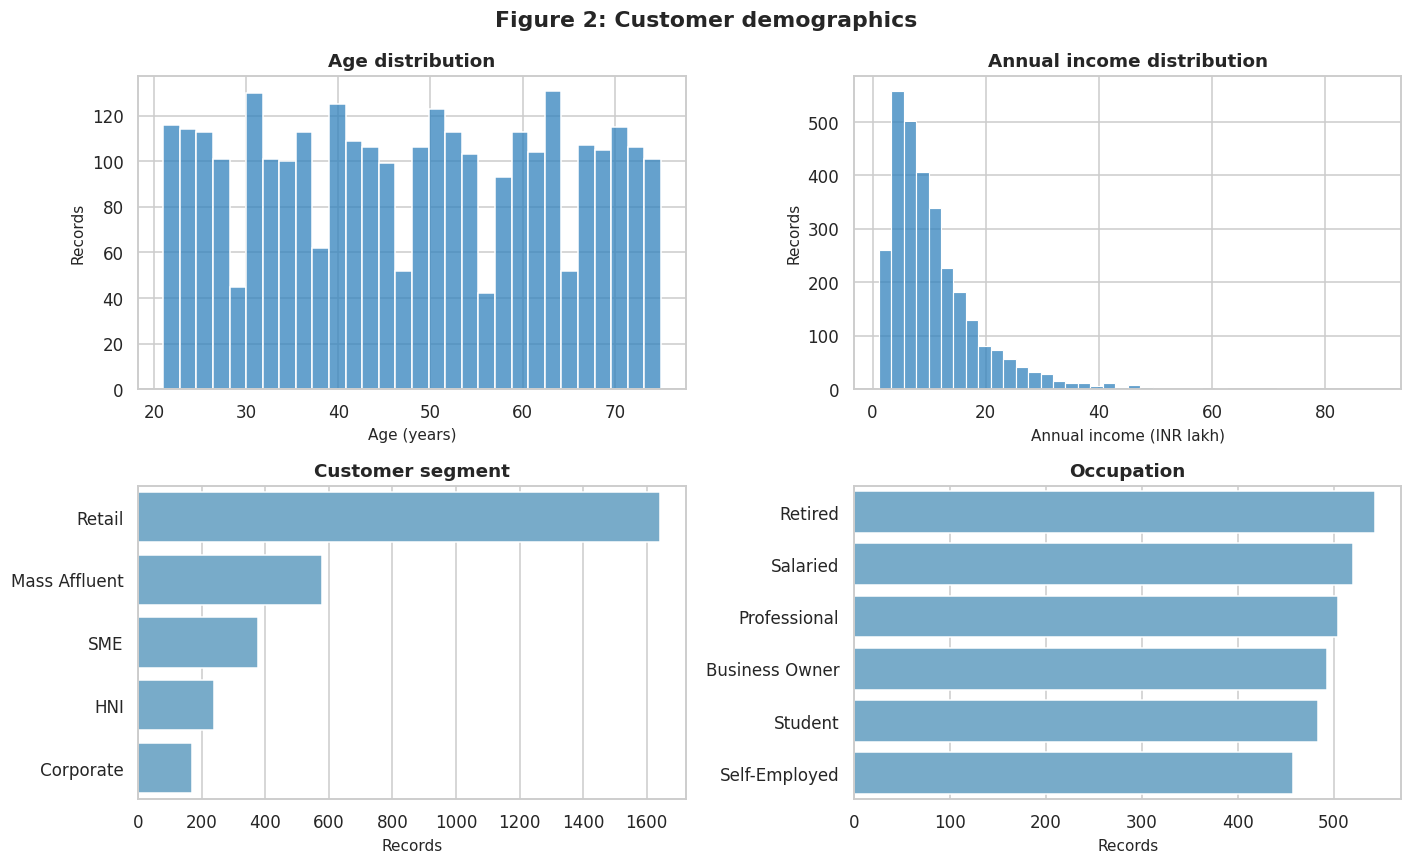

Kruskal-Wallis income across segments: H=0.62, p=0.9612
Gender split %: {'Male': 49.0, 'Female': 48.9, 'Other': 2.1}
State-City consistency check (records per pair; every state contains every city): True
City       Ahmedabad  Bengaluru  Chennai  Delhi
State                                          
Delhi             31         40       29     27
Gujarat           28         35       27     34
Karnataka         34         38       29     27


,Records,Median_Income_INR,Mean_Age,Mean_Credit_Score,Mean_Net_Profit,Default_Rate_pct
Customer_Segment,,,,,,
Retail,1641,"830,274.0000",47.6000,719.7000,"3,210.0000",19.7000
Mass Affluent,578,"874,547.5000",48.7000,727.3000,"3,256.3000",19.6000
SME,376,"853,293.5000",48.0000,720.0000,"3,099.9000",22.3000
HNI,237,"811,028.0000",47.2000,718.6000,"3,280.0000",17.3000
Corporate,168,"901,964.5000",46.6000,721.9000,"2,705.9000",19.0000


In [13]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(df_clean.Age, bins=30, ax=ax[0, 0], color="#3182bd"); ax[0, 0].set(title="Age distribution", xlabel="Age (years)", ylabel="Records")
sns.histplot(df_clean.Annual_Income_INR/1e5, bins=40, ax=ax[0, 1], color="#3182bd"); ax[0, 1].set(title="Annual income distribution", xlabel="Annual income (INR lakh)", ylabel="Records")
seg_order = df_clean.Customer_Segment.value_counts().index
sns.countplot(y=df_clean.Customer_Segment, order=seg_order, ax=ax[1, 0], color="#6baed6"); ax[1, 0].set(title="Customer segment", xlabel="Records", ylabel="")
sns.countplot(y=df_clean.Occupation, order=df_clean.Occupation.value_counts().index, ax=ax[1, 1], color="#6baed6"); ax[1, 1].set(title="Occupation", xlabel="Records", ylabel="")
fig.suptitle("Figure 2: Customer demographics", fontweight="bold"); savefig("F02_demographics")
demo = df_clean.groupby("Customer_Segment", observed=True).agg(Records=("Age", "size"), Median_Income_INR=("Annual_Income_INR", "median"),
        Mean_Age=("Age", "mean"), Mean_Credit_Score=("Credit_Score", "mean"), Mean_Net_Profit=("Net_Profit_INR", "mean"),
        Default_Rate_pct=("Default", lambda s: s.mean()*100)).round(1).sort_values("Records", ascending=False)
kw_inc = stats.kruskal(*[g.Annual_Income_INR for _, g in df_clean.groupby("Customer_Segment", observed=True)])
print(f"Kruskal-Wallis income across segments: H={kw_inc.statistic:.2f}, p={kw_inc.pvalue:.4f}")
print("Gender split %:", df_clean.Gender.value_counts(normalize=True).mul(100).round(1).to_dict())
sc = pd.crosstab(df_clean.State, df_clean.City)
print("State-City consistency check (records per pair; every state contains every city):", (sc > 0).all().all())
print(sc.iloc[:3, :4])
save_table(demo, "T05a_segment_profile"); demo

**Finding.** Retail dominates (54.7% of records), followed by Mass Affluent (19.3%), SME, HNI and Corporate. Age is spread evenly from 21 to 75; income is right-skewed (median ₹8.4 lakh).

**Statistical observation.** Median income does **not** differ across the bank's segment labels (Kruskal-Wallis p = 0.96). HNI records have a median income of ₹8.1 lakh, below Retail's ₹8.3 lakh. Occupation is also inconsistent with age (e.g., students aged 60+ exist), and every state contains every city.

**Business interpretation.** The existing `Customer_Segment` label does not separate customers by wealth, profit or risk. Segmentation must be rebuilt from behaviour (Section 5). Location fields are unreliable and are used only descriptively.

### 3.2 Banking relationship

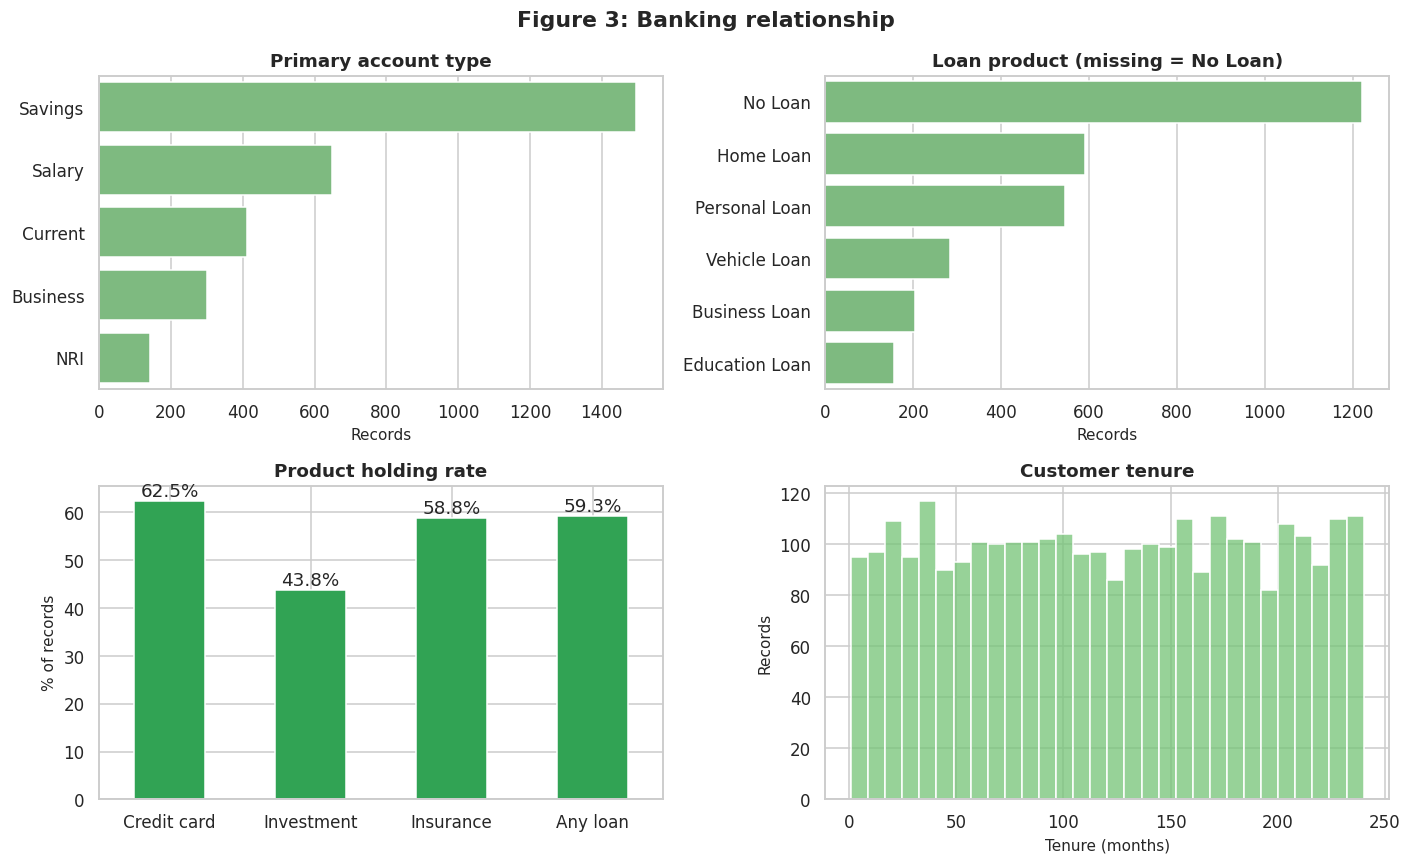

Spearman(products held, net profit) = -0.037, p = 0.043
Holding rates %: {'Credit card': 62.5, 'Investment': 43.8, 'Insurance': 58.8, 'Any loan': 59.3}


,Records,Mean_Net_Profit,Mean_Satisfaction,Default_Rate_pct
Products_Held,,,,
0,95,"3,404.8700",4.1500,2.1100
1,570,"3,393.1800",4.0400,8.9500
2,1133,"3,257.0900",4.0800,17.5600
3,915,"3,076.1200",4.0300,27.2100
4,287,"2,734.2000",4.0600,32.0600


In [14]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.countplot(y=df_clean.Primary_Account_Type, order=df_clean.Primary_Account_Type.value_counts().index, ax=ax[0, 0], color="#74c476"); ax[0, 0].set(title="Primary account type", xlabel="Records", ylabel="")
sns.countplot(y=df_clean.Loan_Product, order=df_clean.Loan_Product.value_counts().index, ax=ax[0, 1], color="#74c476"); ax[0, 1].set(title="Loan product (missing = No Loan)", xlabel="Records", ylabel="")
hold = pd.Series({"Credit card": df_clean.Has_Credit_Card_bin.mean(), "Investment": df_clean.Has_Investment_Product_bin.mean(),
                  "Insurance": df_clean.Has_Insurance_bin.mean(), "Any loan": df_clean.Has_Loan.mean()})*100
hold.plot.bar(ax=ax[1, 0], color="#31a354"); ax[1, 0].set(title="Product holding rate", ylabel="% of records", xlabel=""); ax[1, 0].tick_params(axis="x", rotation=0)
for i, v in enumerate(hold): ax[1, 0].text(i, v+1, f"{v:.1f}%", ha="center")
sns.histplot(df_clean.Customer_Tenure_Months, bins=30, ax=ax[1, 1], color="#74c476"); ax[1, 1].set(title="Customer tenure", xlabel="Tenure (months)", ylabel="Records")
fig.suptitle("Figure 3: Banking relationship", fontweight="bold"); savefig("F03_relationship")
df_clean["Products_Held"] = df_clean[["Has_Credit_Card_bin", "Has_Investment_Product_bin", "Has_Insurance_bin", "Has_Loan"]].sum(axis=1)
prod = df_clean.groupby("Products_Held").agg(Records=("Age", "size"), Mean_Net_Profit=("Net_Profit_INR", "mean"),
        Mean_Satisfaction=("Customer_Satisfaction_Score", "mean"), Default_Rate_pct=("Default", lambda s: s.mean()*100)).round(2)
rho_p = stats.spearmanr(df_clean.Products_Held, df_clean.Net_Profit_INR)
print(f"Spearman(products held, net profit) = {rho_p.statistic:.3f}, p = {rho_p.pvalue:.3f}")
print("Holding rates %:", hold.round(1).to_dict())
save_table(prod, "T05b_products_held"); prod

**Finding.** 62.5% hold a credit card, 58.8% insurance, 59.3% a loan and 43.8% an investment product. Tenure is uniform from 1 to 240 months.

**Statistical observation.** The number of products held is weakly *negatively* related to net profit (Spearman ρ = −0.037, p = 0.043). Default rate rises from 2.1% (0 products) to 32.1% (4 products), but only because product count includes loans.

**Business interpretation.** Cross-selling more products is not, by itself, associated with higher profit in this data. Adding a loan is what changes the risk profile.

### 3.3 Transaction behaviour

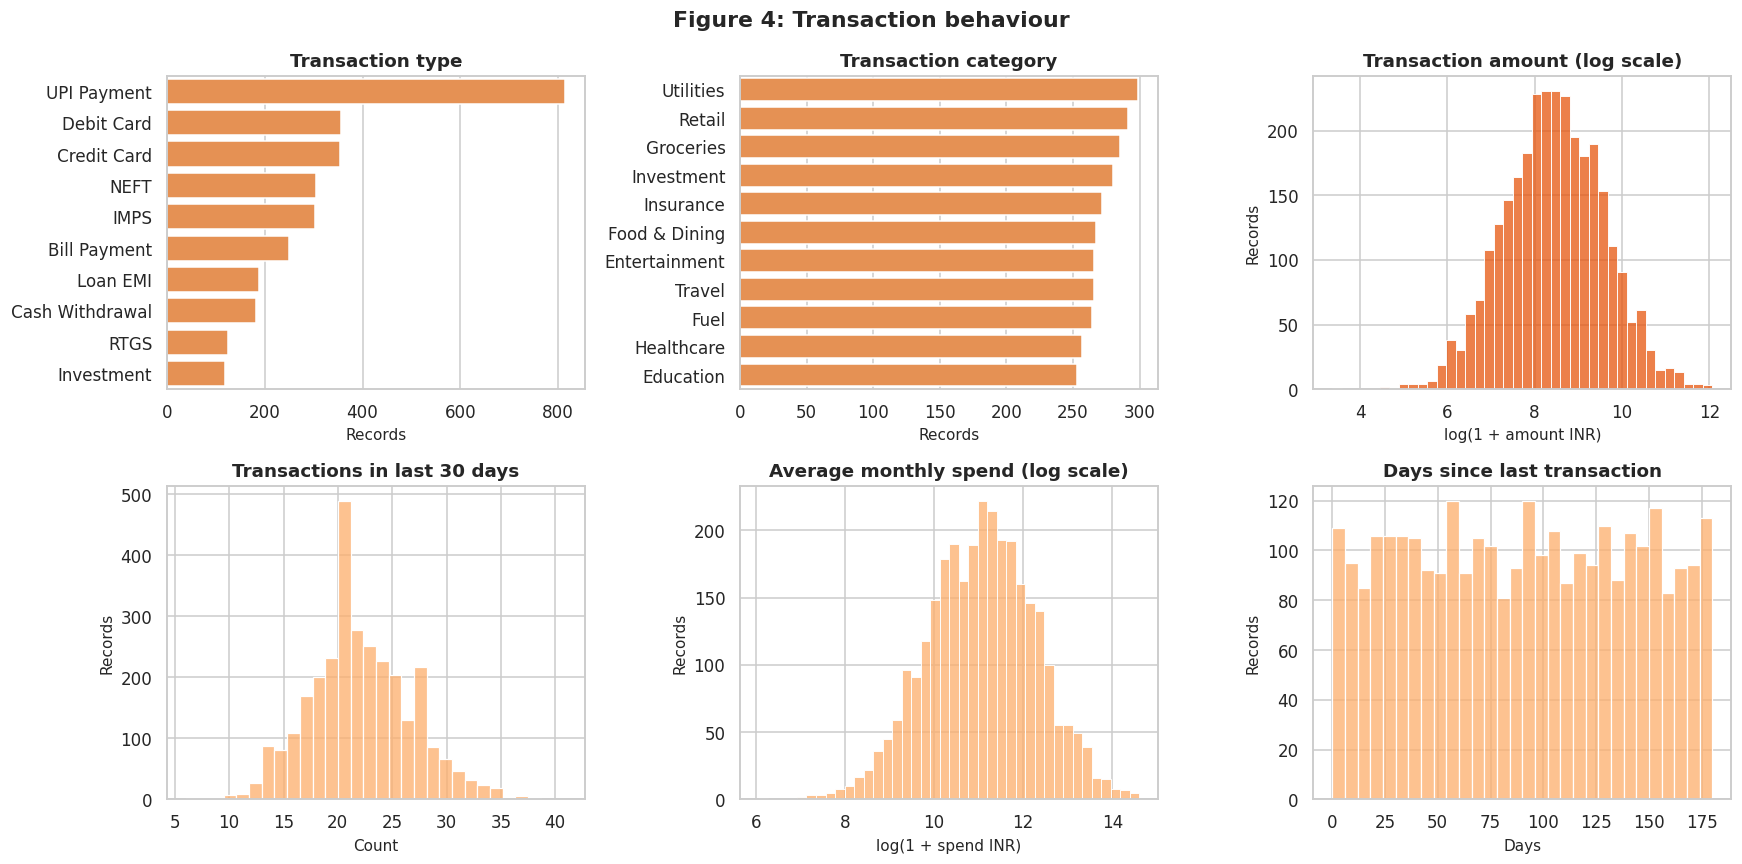

Digital channels (UPI + Mobile + Net banking) share of transactions: 63.9%
Debit/Credit %: {'Debit': 73.6, 'Credit': 26.4}
Median transaction amount: INR 4,611; mean: INR 8,678
Corr(Transaction_Amount, Avg_Monthly_Spend) = 0.883
Kruskal-Wallis net profit across transaction types: p = 0.706


,Records,Median_Amount,Mean_Net_Profit,Share_%
Transaction_Type,,,,
UPI Payment,814,"4,823.0000","3,124.0000",27.1000
Debit Card,357,"4,194.0000","3,290.0000",11.9000
Credit Card,355,"4,780.0000","3,082.0000",11.8000
NEFT,304,"4,342.0000","3,010.0000",10.1000
IMPS,303,"5,045.0000","3,144.0000",10.1000
Bill Payment,250,"4,602.0000","3,078.0000",8.3000
Loan EMI,188,"4,277.0000","3,012.0000",6.3000
Cash Withdrawal,183,"4,421.0000","3,399.0000",6.1000
RTGS,126,"4,480.0000","4,193.0000",4.2000


In [15]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.countplot(y=df_clean.Transaction_Type, order=df_clean.Transaction_Type.value_counts().index, ax=ax[0, 0], color="#fd8d3c"); ax[0, 0].set(title="Transaction type", xlabel="Records", ylabel="")
sns.countplot(y=df_clean.Transaction_Category, order=df_clean.Transaction_Category.value_counts().index, ax=ax[0, 1], color="#fd8d3c"); ax[0, 1].set(title="Transaction category", xlabel="Records", ylabel="")
sns.histplot(df_clean.log_Transaction_Amount_INR, bins=40, ax=ax[0, 2], color="#e6550d"); ax[0, 2].set(title="Transaction amount (log scale)", xlabel="log(1 + amount INR)", ylabel="Records")
sns.histplot(df_clean.Transactions_Last_30_Days, bins=30, ax=ax[1, 0], color="#fdae6b"); ax[1, 0].set(title="Transactions in last 30 days", xlabel="Count", ylabel="Records")
sns.histplot(df_clean.log_Average_Monthly_Spend_INR, bins=40, ax=ax[1, 1], color="#fdae6b"); ax[1, 1].set(title="Average monthly spend (log scale)", xlabel="log(1 + spend INR)", ylabel="Records")
sns.histplot(df_clean.Days_Since_Last_Transaction, bins=30, ax=ax[1, 2], color="#fdae6b"); ax[1, 2].set(title="Days since last transaction", xlabel="Days", ylabel="Records")
fig.suptitle("Figure 4: Transaction behaviour", fontweight="bold"); savefig("F04_transactions")
txn = df_clean.groupby("Transaction_Type", observed=True).agg(Records=("Age", "size"), Median_Amount=("Transaction_Amount_INR", "median"),
        Mean_Net_Profit=("Net_Profit_INR", "mean")).round(0).sort_values("Records", ascending=False)
txn["Share_%"] = (txn.Records/len(df_clean)*100).round(1)
digital_share = df_clean.Transaction_Channel.isin(["UPI", "Mobile Banking", "Net Banking"]).mean()*100
print(f"Digital channels (UPI + Mobile + Net banking) share of transactions: {digital_share:.1f}%")
print("Debit/Credit %:", df_clean.Debit_Credit.value_counts(normalize=True).mul(100).round(1).to_dict())
print(f"Median transaction amount: INR {df_clean.Transaction_Amount_INR.median():,.0f}; mean: INR {df_clean.Transaction_Amount_INR.mean():,.0f}")
print(f"Corr(Transaction_Amount, Avg_Monthly_Spend) = {df_clean.Transaction_Amount_INR.corr(df_clean.Average_Monthly_Spend_INR):.3f}")
kw_tt = stats.kruskal(*[g.Net_Profit_INR for _, g in df_clean.groupby("Transaction_Type", observed=True)])
print(f"Kruskal-Wallis net profit across transaction types: p = {kw_tt.pvalue:.3f}")
save_table(txn, "T05c_transaction_type"); txn

**Finding.** UPI is the single largest transaction type (27.1%). Digital channels (UPI + mobile + net banking) carry 63.9% of transactions and 73.6% are debits. The median transaction is ₹4,611 against a mean of ₹8,678 (heavy right tail).

**Statistical observation.** Transaction amount and average monthly spend are highly correlated (r = 0.883), so only one is used as a predictor. Net profit does not differ by transaction type (p = 0.71).

**Business interpretation.** The bank is already digital-first on volume, but *which* channel a customer transacts on carries no profit signal.

### 3.4 Digital engagement

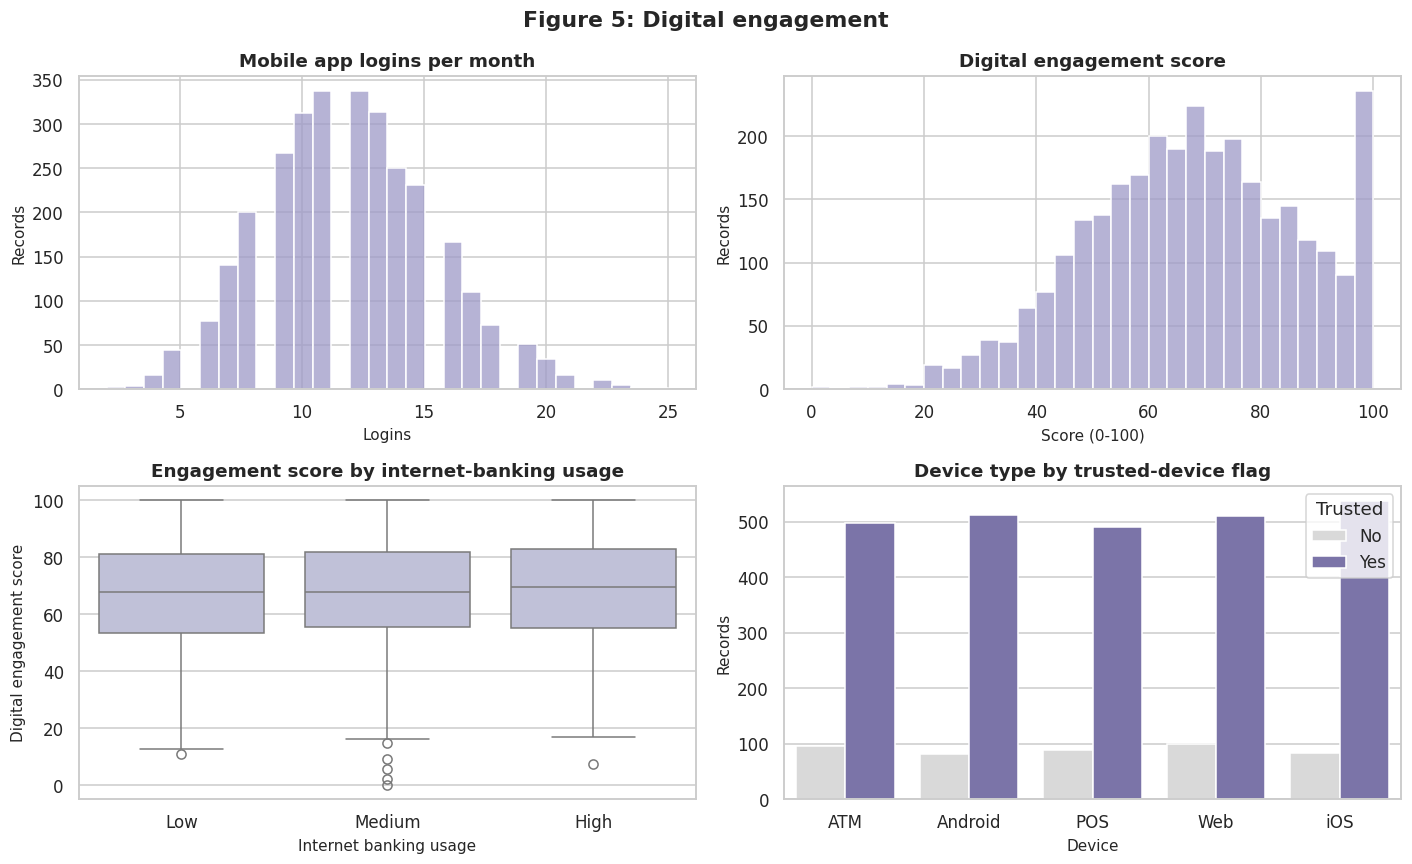

Kruskal-Wallis engagement score by IB usage: p = 0.498
Trusted device share: 85.0%


,Mobile_App_Logins_Month,IB_Usage_Ord,Digital_Engagement_Score,Customer_Satisfaction_Score,Net_Profit_INR,Churn_Probability
Mobile_App_Logins_Month,1.0000,0.0190,0.0110,0.0160,-0.0090,0.0010
IB_Usage_Ord,0.0190,1.0000,0.0210,-0.0030,-0.0080,-0.0140
Digital_Engagement_Score,0.0110,0.0210,1.0000,0.0090,0.0400,-0.3900
Customer_Satisfaction_Score,0.0160,-0.0030,0.0090,1.0000,-0.0020,-0.0000
Net_Profit_INR,-0.0090,-0.0080,0.0400,-0.0020,1.0000,-0.0700
Churn_Probability,0.0010,-0.0140,-0.3900,-0.0000,-0.0700,1.0000


In [16]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(df_clean.Mobile_App_Logins_Month, bins=30, ax=ax[0, 0], color="#9e9ac8"); ax[0, 0].set(title="Mobile app logins per month", xlabel="Logins", ylabel="Records")
sns.histplot(df_clean.Digital_Engagement_Score, bins=30, ax=ax[0, 1], color="#9e9ac8"); ax[0, 1].set(title="Digital engagement score", xlabel="Score (0-100)", ylabel="Records")
sns.boxplot(x=df_clean.Internet_Banking_Usage, y=df_clean.Digital_Engagement_Score, order=["Low", "Medium", "High"], ax=ax[1, 0], color="#bcbddc")
ax[1, 0].set(title="Engagement score by internet-banking usage", xlabel="Internet banking usage", ylabel="Digital engagement score")
sns.countplot(x=df_clean.Device_Type, hue=df_clean.Trusted_Device, ax=ax[1, 1], palette=["#d9d9d9", "#756bb1"]); ax[1, 1].set(title="Device type by trusted-device flag", xlabel="Device", ylabel="Records"); ax[1, 1].legend(title="Trusted")
fig.suptitle("Figure 5: Digital engagement", fontweight="bold"); savefig("F05_digital")
dig_corr = df_clean[["Mobile_App_Logins_Month", "IB_Usage_Ord", "Digital_Engagement_Score", "Customer_Satisfaction_Score",
                     "Net_Profit_INR", "Churn_Probability"]].corr(method="spearman").round(3)
kw_ib = stats.kruskal(*[g.Digital_Engagement_Score for _, g in df_clean.groupby("Internet_Banking_Usage", observed=True)])
print(f"Kruskal-Wallis engagement score by IB usage: p = {kw_ib.pvalue:.3f}")
print(f"Trusted device share: {df_clean.Trusted_Device_bin.mean()*100:.1f}%")
save_table(dig_corr, "T05d_digital_corr"); dig_corr

**Finding.** Mean digital engagement score is 68/100, with ~12 app logins a month. 85% of transactions come from trusted devices.

**Statistical observation.** App logins, internet-banking usage and the engagement score are essentially **uncorrelated with each other** (|ρ| ≤ 0.02), and the score does not differ by net-banking usage level (p = 0.50). The score's only notable association is with the bank's churn probability (ρ = −0.39).

**Business interpretation.** The composite "digital engagement score" does not reflect actual app or net-banking activity in this data. Management should not use it as a proxy for engagement or value without first validating how it is calculated.

### 3.5 Credit risk

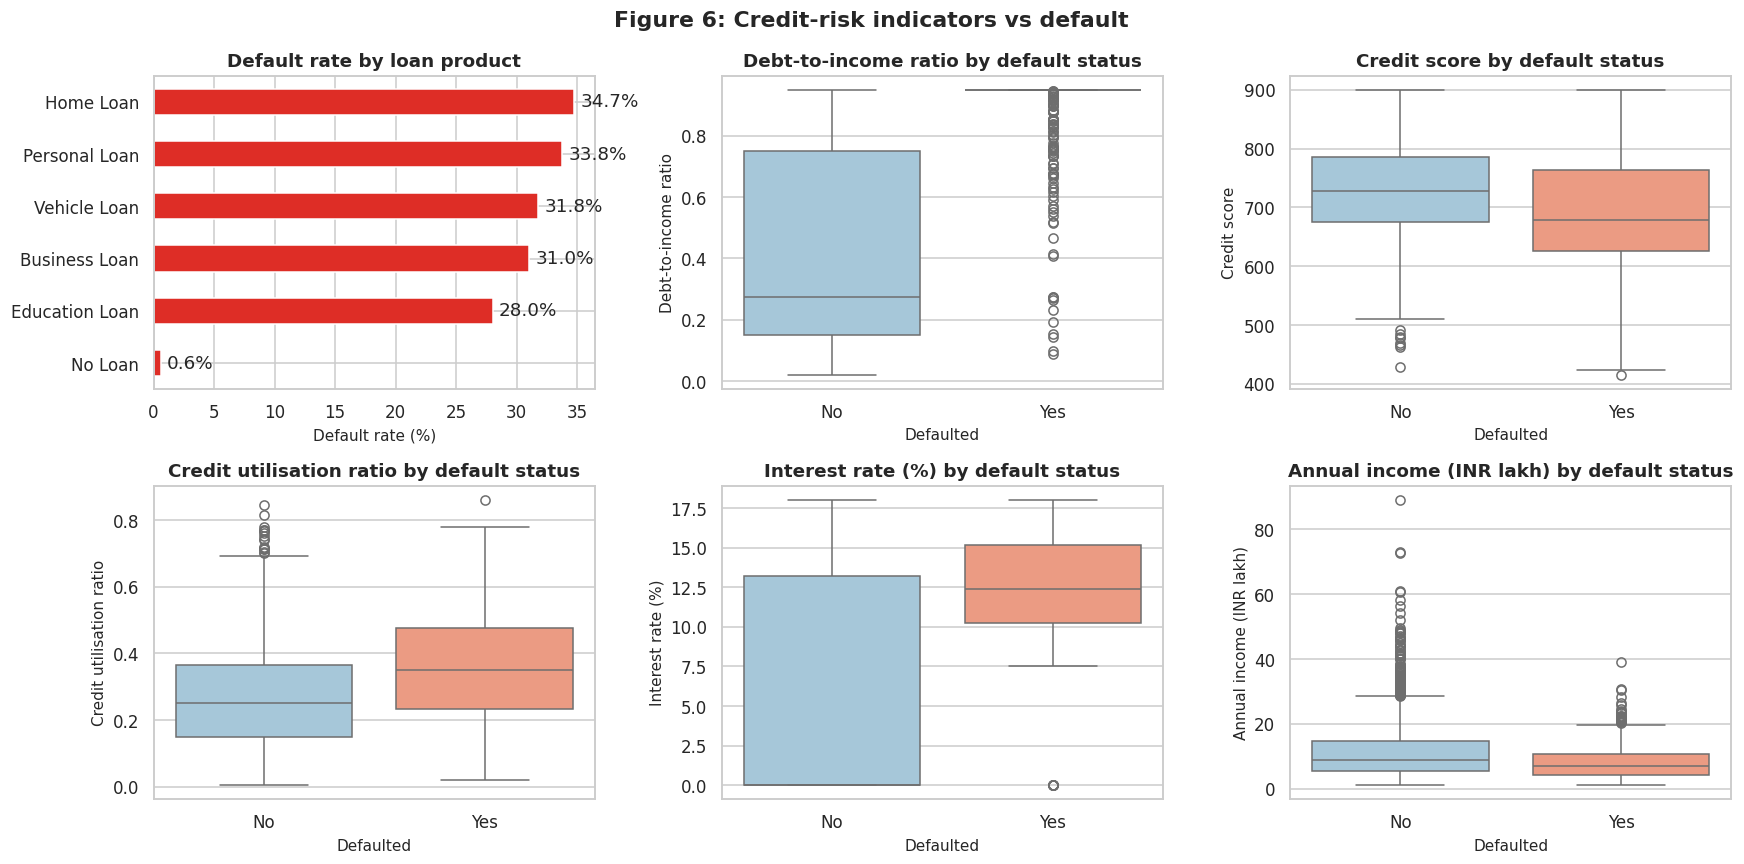

Overall default rate: 19.77%  | loan holders: 32.96%  | no loan: 0.57%


,Variable,Median_NonDefault,Median_Default,MannWhitney_p,Significant_5%
0,Credit_Score,728.0000,679.0000,0.0000,Yes
1,Credit_Utilization_Ratio,0.2500,0.3500,0.0000,Yes
2,Credit_Limit_INR,"1,257,915.0000","1,296,858.0000",0.7868,No
3,Outstanding_Loan_INR,"98,907.1600","6,156,175.3500",0.0000,Yes
4,Interest_Rate_Percent,0.0000,12.3700,0.0000,Yes
5,EMI_Amount_INR,0.0000,"94,789.0000",0.0000,Yes
6,Debt_to_Income_Ratio,0.2750,0.9500,0.0000,Yes
7,Annual_Income_INR,"891,293.0000","696,139.0000",0.0000,Yes
8,Account_Balance_Before_INR,"1,222,964.7000","1,218,417.6200",0.7091,No
9,Customer_Tenure_Months,121.0000,119.0000,0.4595,No


,Variable,Chi2,p_value,Default rate range across levels,Significant_5%
0,Loan_Product,483.4900,0.0000,0.6% - 34.7%,Yes
1,Primary_Account_Type,10.4300,0.0338,11.3% - 21.9%,Yes
2,Customer_Segment,2.5600,0.6341,17.3% - 22.3%,No
3,Occupation,8.7900,0.1179,17.1% - 22.9%,No
4,Gender,1.9200,0.3823,15.6% - 20.7%,No
5,Has_Credit_Card,1.0700,0.3009,19.2% - 20.8%,No
6,Has_Investment_Product,0.0100,0.9092,19.6% - 19.9%,No
7,Has_Insurance,1.2500,0.2632,18.8% - 20.5%,No
8,Internet_Banking_Usage,0.2000,0.9032,19.4% - 20.4%,No


In [17]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
dr = df_clean.groupby("Loan_Product", observed=True).Default.mean().mul(100).sort_values()
dr.plot.barh(ax=ax[0, 0], color="#de2d26"); ax[0, 0].set(title="Default rate by loan product", xlabel="Default rate (%)", ylabel="")
for i, v in enumerate(dr): ax[0, 0].text(v+0.5, i, f"{v:.1f}%", va="center")
for a, c, lab in zip([ax[0, 1], ax[0, 2], ax[1, 0], ax[1, 1], ax[1, 2]],
                     ["Debt_to_Income_Ratio", "Credit_Score", "Credit_Utilization_Ratio", "Interest_Rate_Percent", "Annual_Income_INR"],
                     ["Debt-to-income ratio", "Credit score", "Credit utilisation ratio", "Interest rate (%)", "Annual income (INR lakh)"]):
    yy = df_clean[c]/1e5 if c == "Annual_Income_INR" else df_clean[c]
    sns.boxplot(x=df_clean.Target_Default, y=yy, ax=a, order=["No", "Yes"], palette=["#9ecae1", "#fc9272"])
    a.set(title=f"{lab} by default status", xlabel="Defaulted", ylabel=lab)
fig.suptitle("Figure 6: Credit-risk indicators vs default", fontweight="bold"); savefig("F06_credit_risk")

risk_num = ["Credit_Score", "Credit_Utilization_Ratio", "Credit_Limit_INR", "Outstanding_Loan_INR", "Interest_Rate_Percent",
            "EMI_Amount_INR", "Debt_to_Income_Ratio", "Annual_Income_INR", "Account_Balance_Before_INR", "Customer_Tenure_Months",
            "Transactions_Last_30_Days", "Average_Monthly_Spend_INR", "Days_Since_Last_Transaction", "Age",
            "Digital_Engagement_Score", "Customer_Satisfaction_Score"]
rows = []
for c in risk_num:
    a0, a1 = df_clean.loc[df_clean.Default == 0, c], df_clean.loc[df_clean.Default == 1, c]
    rows.append([c, a0.median(), a1.median(), stats.mannwhitneyu(a0, a1).pvalue])
mw = pd.DataFrame(rows, columns=["Variable", "Median_NonDefault", "Median_Default", "MannWhitney_p"])
mw["Significant_5%"] = np.where(mw.MannWhitney_p < 0.05, "Yes", "No")
mw = mw.round(4)
rows = []
for c in ["Loan_Product", "Primary_Account_Type", "Customer_Segment", "Occupation", "Gender", "Has_Credit_Card",
          "Has_Investment_Product", "Has_Insurance", "Internet_Banking_Usage"]:
    ct = pd.crosstab(df_clean[c], df_clean.Default); chi = stats.chi2_contingency(ct)
    rng = df_clean.groupby(c, observed=True).Default.mean()*100
    rows.append([c, round(chi[0], 2), chi[1], f"{rng.min():.1f}% - {rng.max():.1f}%"])
chi_t = pd.DataFrame(rows, columns=["Variable", "Chi2", "p_value", "Default rate range across levels"])
chi_t["Significant_5%"] = np.where(chi_t.p_value < 0.05, "Yes", "No")
print(f"Overall default rate: {df_clean.Default.mean()*100:.2f}%  | loan holders: {df_clean[df_clean.Has_Loan==1].Default.mean()*100:.2f}%"
      f"  | no loan: {df_clean[df_clean.Has_Loan==0].Default.mean()*100:.2f}%")
save_table(mw, "T05e_default_mannwhitney", index=False); save_table(chi_t, "T05f_default_chisq", index=False)
display(mw); chi_t

**Finding.** The overall default rate is 19.8%. It is **32.96% among loan holders versus 0.57% among non-borrowers**. By product, default ranges from 28.0% (education) to 34.7% (home loan).

**Statistical observation.** Defaulters have a much higher median DTI (0.95 vs 0.275), higher utilisation (0.35 vs 0.25), lower credit score (679 vs 728) and lower income (₹6.96 vs ₹8.91 lakh), all with Mann-Whitney p < 0.001. Behavioural and digital variables (tenure, transactions, spend, recency, age, engagement, satisfaction) show **no significant difference** (all p > 0.09). Among categorical variables, only loan product (χ² = 483.5) and account type (p = 0.034) are significant; segment, occupation, gender and product holdings are not.

**Business interpretation.** Default risk is a **leverage story**: debt burden relative to income, revolving-credit utilisation and bureau score. It is not a demographic or engagement story.

### 3.6 Investment behaviour

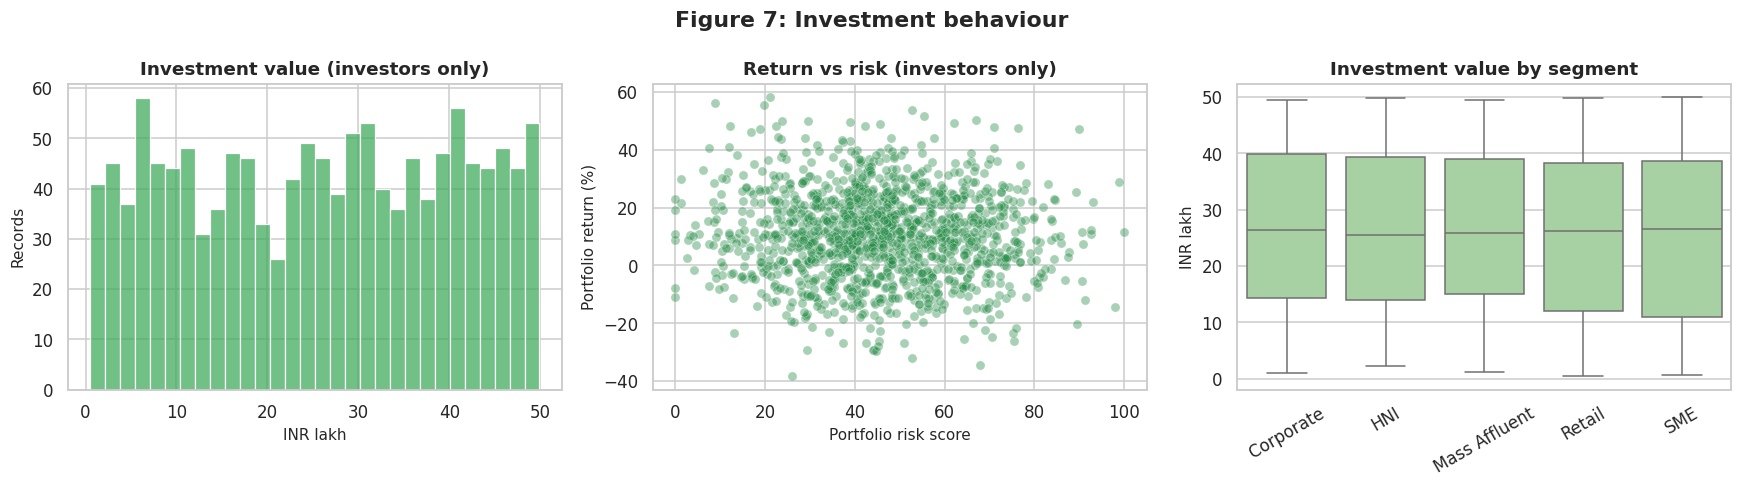

Investors: 1314 (43.8%) | median value INR 2,626,689 | median return 10.38% | share with negative return 24.8%
Net profit investors vs non-investors: 3,027 vs 3,303; Mann-Whitney p = 0.071


,Investment_Value_INR,Portfolio_Return_Percent,Portfolio_Risk_Score,Annual_Income_INR,Net_Profit_INR
Investment_Value_INR,1.0000,0.0130,0.0380,0.0110,-0.0520
Portfolio_Return_Percent,0.0130,1.0000,-0.0440,0.0110,-0.0170
Portfolio_Risk_Score,0.0380,-0.0440,1.0000,-0.0110,0.0080
Annual_Income_INR,0.0110,0.0110,-0.0110,1.0000,-0.0180
Net_Profit_INR,-0.0520,-0.0170,0.0080,-0.0180,1.0000


In [18]:
inv = df_clean[df_clean.Has_Investment_Product_bin == 1]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(inv.Investment_Value_INR/1e5, bins=30, ax=ax[0], color="#41ab5d"); ax[0].set(title="Investment value (investors only)", xlabel="INR lakh", ylabel="Records")
sns.scatterplot(x=inv.Portfolio_Risk_Score, y=inv.Portfolio_Return_Percent, alpha=.4, ax=ax[1], color="#238b45"); ax[1].set(title="Return vs risk (investors only)", xlabel="Portfolio risk score", ylabel="Portfolio return (%)")
sns.boxplot(x=inv.Customer_Segment, y=inv.Investment_Value_INR/1e5, ax=ax[2], color="#a1d99b"); ax[2].set(title="Investment value by segment", xlabel="", ylabel="INR lakh"); ax[2].tick_params(axis="x", rotation=30)
fig.suptitle("Figure 7: Investment behaviour", fontweight="bold"); savefig("F07_investment")
inv_corr = inv[["Investment_Value_INR", "Portfolio_Return_Percent", "Portfolio_Risk_Score", "Annual_Income_INR", "Net_Profit_INR"]].corr().round(3)
mw_inv = stats.mannwhitneyu(df_clean.loc[df_clean.Has_Investment_Product_bin == 1, "Net_Profit_INR"], df_clean.loc[df_clean.Has_Investment_Product_bin == 0, "Net_Profit_INR"])
print(f"Investors: {len(inv)} ({len(inv)/len(df_clean)*100:.1f}%) | median value INR {inv.Investment_Value_INR.median():,.0f} | "
      f"median return {inv.Portfolio_Return_Percent.median():.2f}% | share with negative return {(inv.Portfolio_Return_Percent<0).mean()*100:.1f}%")
print(f"Net profit investors vs non-investors: {df_clean.loc[df_clean.Has_Investment_Product_bin==1,'Net_Profit_INR'].mean():,.0f} vs "
      f"{df_clean.loc[df_clean.Has_Investment_Product_bin==0,'Net_Profit_INR'].mean():,.0f}; Mann-Whitney p = {mw_inv.pvalue:.3f}")
save_table(inv_corr, "T05g_investment_corr"); inv_corr

**Finding.** 1,314 records (43.8%) hold investments. Median portfolio is ₹26.3 lakh, median return 10.4%, and 24.8% have a negative return.

**Statistical observation.** Among investors, value, return and risk are almost uncorrelated (|r| ≤ 0.04). Their strong full-sample correlations (0.37–0.72) come from the non-investor zeros. Investors are not more profitable (₹3,027 vs ₹3,303, p = 0.071).

**Business interpretation.** Investment holding is a real behavioural dimension (whether a customer invests or not), but within investors there is no return–risk trade-off to exploit. One in four investors is losing money, which is a relationship-risk flag for wealth advisory.

### 3.7 Profitability

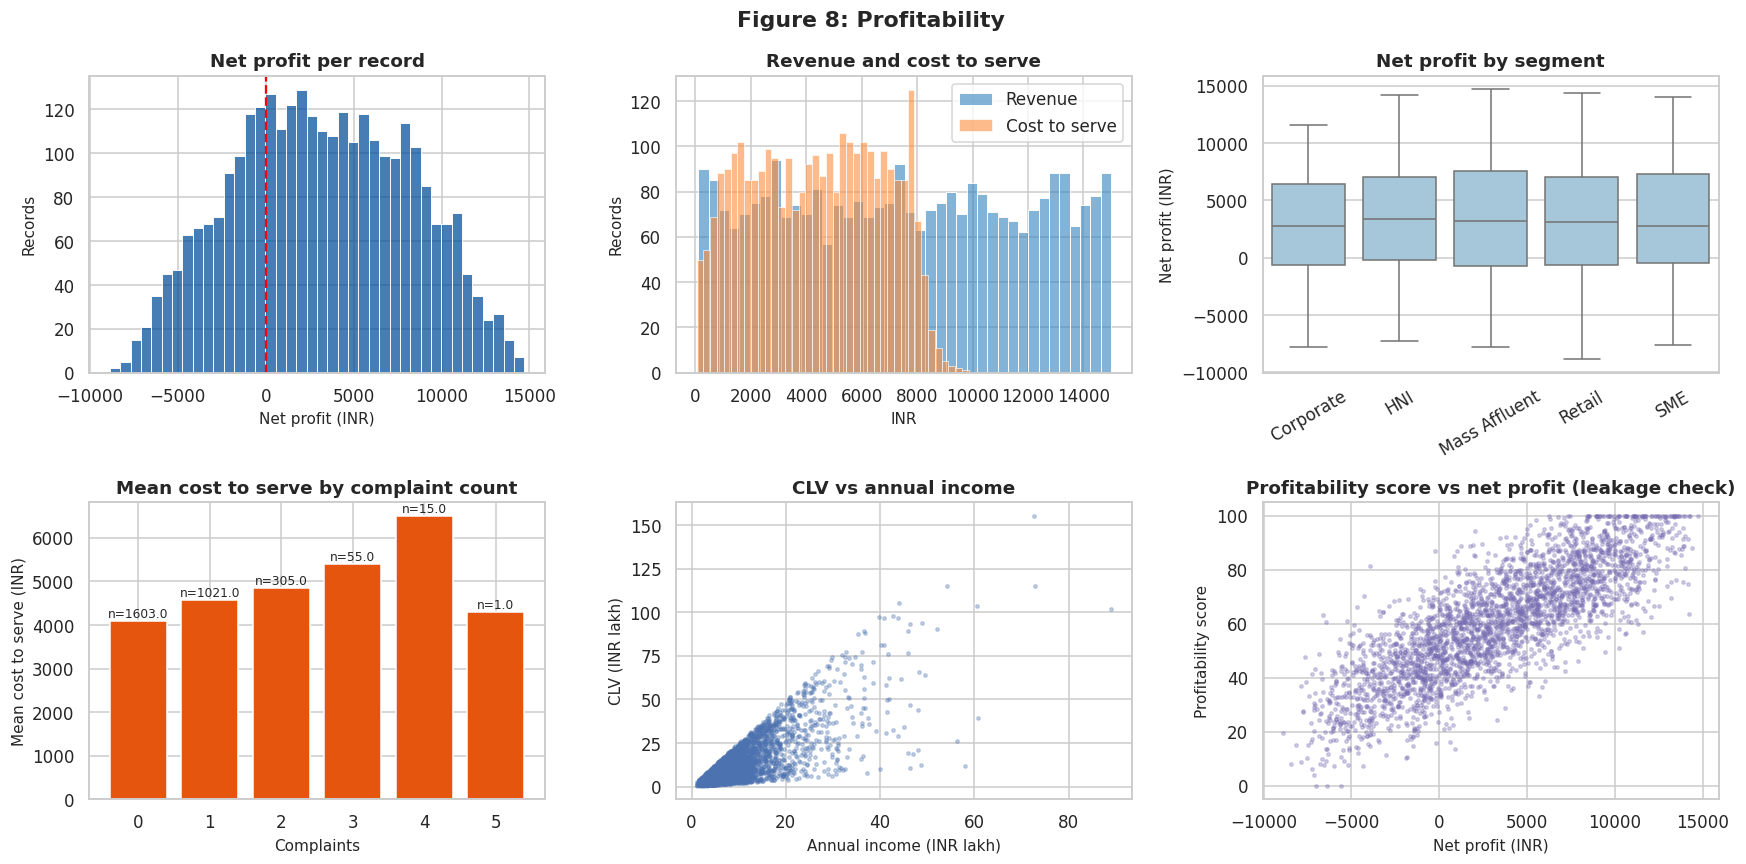

Loss-making records: 29.1% | mean profit INR 3,182 | median INR 3,037
Spearman(complaints, cost to serve) = 0.134, p = 1.65e-13
Pearson(income, CLV) = 0.772


,Variable,Kruskal_H,p_value,Lowest mean profit,Highest mean profit
0,Customer_Segment,1.5900,0.8102,"Corporate (2,706)","HNI (3,280)"
1,Occupation,6.2900,0.2792,"Self-Employed (2,928)","Business Owner (3,546)"
2,Primary_Account_Type,5.1000,0.2776,"Salary (3,054)","Business (3,572)"
3,Loan_Product,1.6000,0.9015,"Business Loan (2,920)","No Loan (3,298)"
4,Transaction_Type,6.3300,0.7063,"NEFT (3,010)","RTGS (4,193)"
5,State,24.4500,0.0036,"Telangana (2,545)","West Bengal (3,888)"
6,Bank_Name,15.9400,0.0682,"Kotak Mahindra Bank (2,657)","State Bank of India (3,734)"
7,Gender,5.6800,0.0584,"Female (2,983)","Male (3,387)"


In [19]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(df_clean.Net_Profit_INR, bins=40, ax=ax[0, 0], color="#08519c"); ax[0, 0].axvline(0, color="red", ls="--"); ax[0, 0].set(title="Net profit per record", xlabel="Net profit (INR)", ylabel="Records")
sns.histplot(df_clean.Revenue_Generated_INR, bins=40, ax=ax[0, 1], color="#3182bd", label="Revenue", alpha=.6)
sns.histplot(df_clean.Cost_to_Serve_INR, bins=40, ax=ax[0, 1], color="#fd8d3c", label="Cost to serve", alpha=.6); ax[0, 1].legend(); ax[0, 1].set(title="Revenue and cost to serve", xlabel="INR", ylabel="Records")
sns.boxplot(x=df_clean.Customer_Segment, y=df_clean.Net_Profit_INR, ax=ax[0, 2], color="#9ecae1"); ax[0, 2].set(title="Net profit by segment", xlabel="", ylabel="Net profit (INR)"); ax[0, 2].tick_params(axis="x", rotation=30)
cc = df_clean.groupby("Complaint_Count").agg(cost=("Cost_to_Serve_INR", "mean"), n=("Age", "size"))
ax[1, 0].bar(cc.index, cc.cost, color="#e6550d"); ax[1, 0].set(title="Mean cost to serve by complaint count", xlabel="Complaints", ylabel="Mean cost to serve (INR)")
for x, (v, n) in cc.iterrows(): ax[1, 0].text(x, v+80, f"n={n}", ha="center", fontsize=8)
ax[1, 1].scatter(df_clean.Annual_Income_INR/1e5, df_clean.Customer_Lifetime_Value_INR/1e5, s=5, alpha=.3); ax[1, 1].set(title="CLV vs annual income", xlabel="Annual income (INR lakh)", ylabel="CLV (INR lakh)")
ax[1, 2].scatter(df_clean.Net_Profit_INR, df_clean.Profitability_Score, s=5, alpha=.3, color="#756bb1"); ax[1, 2].set(title="Profitability score vs net profit (leakage check)", xlabel="Net profit (INR)", ylabel="Profitability score")
fig.suptitle("Figure 8: Profitability", fontweight="bold"); savefig("F08_profitability")
print(f"Loss-making records: {(df_clean.Net_Profit_INR<0).mean()*100:.1f}% | mean profit INR {df_clean.Net_Profit_INR.mean():,.0f} | median INR {df_clean.Net_Profit_INR.median():,.0f}")
rho_cc = stats.spearmanr(df_clean.Complaint_Count, df_clean.Cost_to_Serve_INR)
print(f"Spearman(complaints, cost to serve) = {rho_cc.statistic:.3f}, p = {rho_cc.pvalue:.2e}")
print(f"Pearson(income, CLV) = {df_clean.Annual_Income_INR.corr(df_clean.Customer_Lifetime_Value_INR):.3f}")
rows = []
for c in ["Customer_Segment", "Occupation", "Primary_Account_Type", "Loan_Product", "Transaction_Type", "State", "Bank_Name", "Gender"]:
    kw = stats.kruskal(*[g.Net_Profit_INR for _, g in df_clean.groupby(c, observed=True)])
    m = df_clean.groupby(c, observed=True).Net_Profit_INR.mean()
    rows.append([c, round(kw.statistic, 2), round(kw.pvalue, 4), f"{m.idxmin()} ({m.min():,.0f})", f"{m.idxmax()} ({m.max():,.0f})"])
kw_np = pd.DataFrame(rows, columns=["Variable", "Kruskal_H", "p_value", "Lowest mean profit", "Highest mean profit"])
save_table(kw_np, "T05h_profit_kruskal", index=False); kw_np

**Finding.** 29.1% of records are loss-making. Mean profit is ₹3,182 (median ₹3,037).

**Statistical observation.** Cost-to-serve rises with complaints: ₹4,091 with no complaints → ₹4,991 with 2+ (Spearman ρ = 0.134, p < 10⁻¹²). Net profit does **not** differ by segment (p = 0.81), occupation, account type, loan product or transaction type. State is the only significant factor (p = 0.004), but state fields are unreliable (3.1). CLV is strongly tied to income (r = 0.772). Profitability_Score tracks net profit (r = 0.81), confirming it as a derived field.

**Business interpretation.** Per-record profit is not explained by *who* the customer is. The one controllable lever visible in the data is **service failure (complaints) raising cost-to-serve**.

### 3.8 Correlation analysis

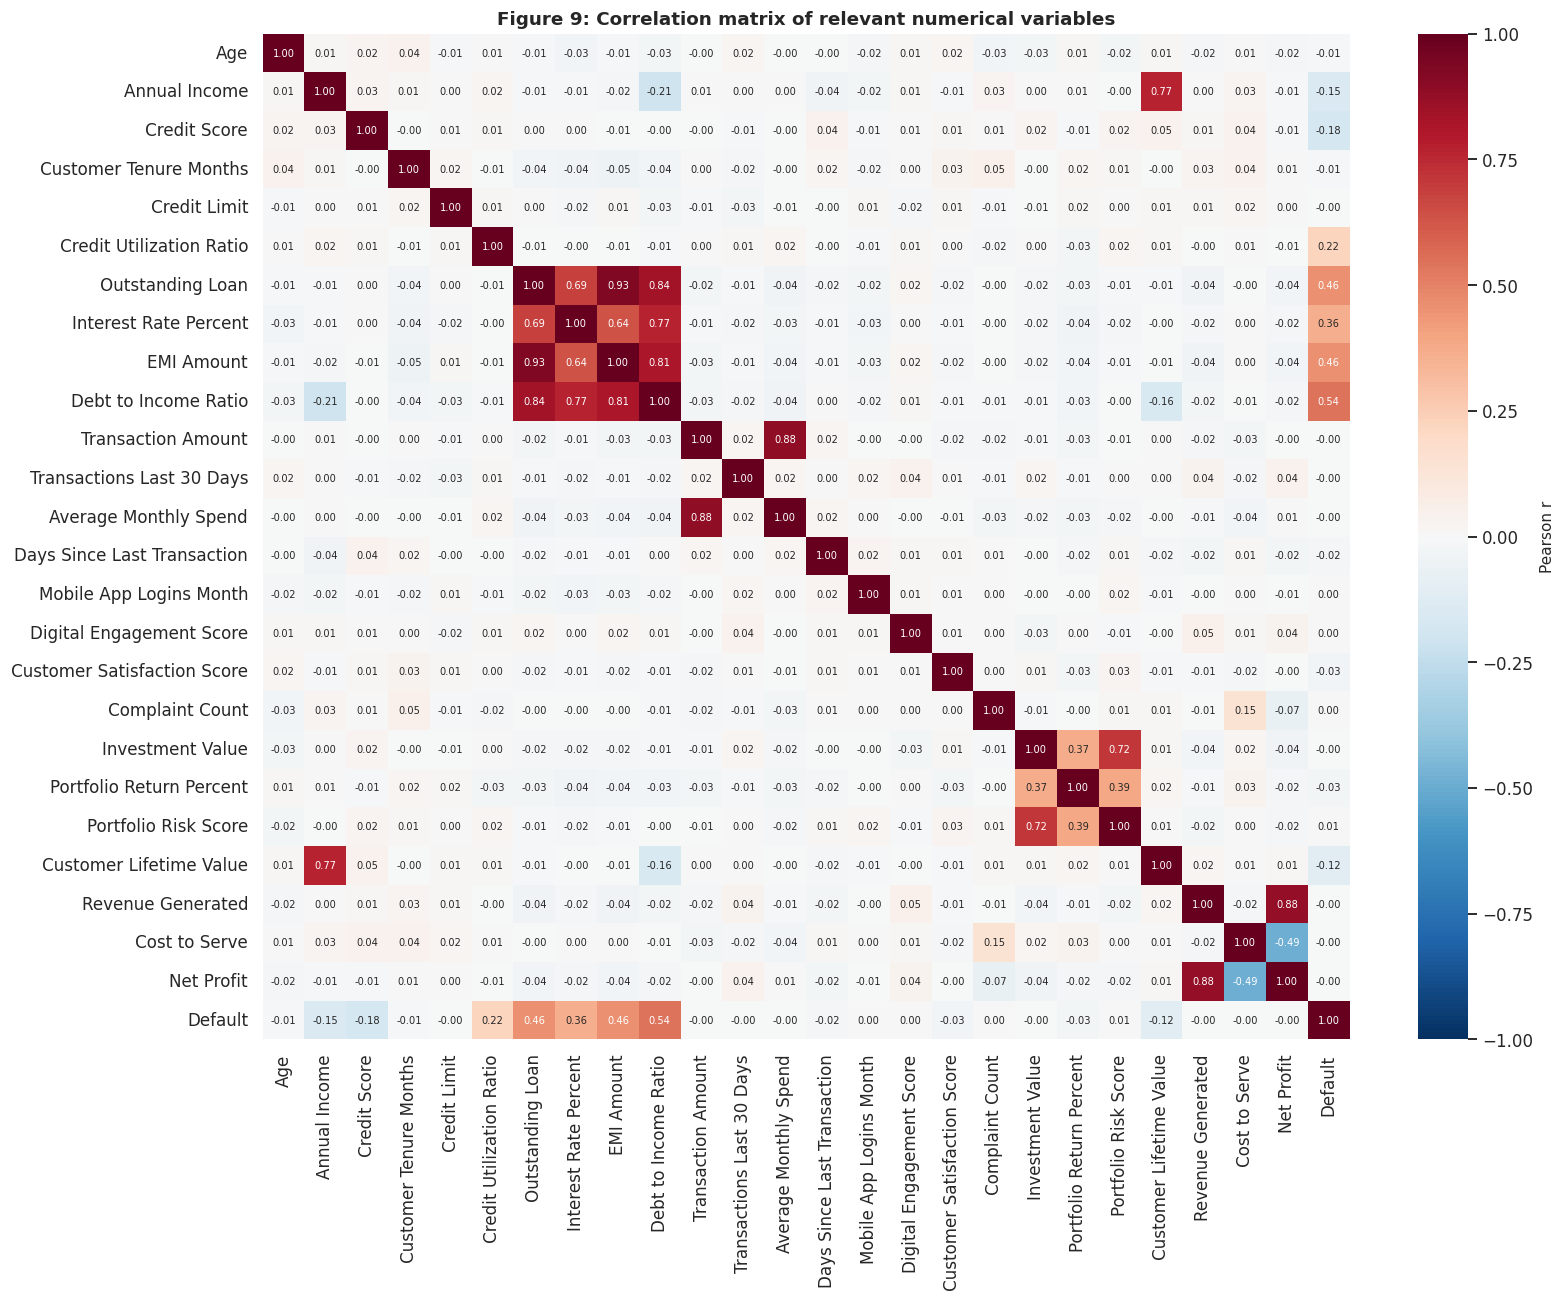

Pairs with |r| >= 0.3: 17 of 325


,Var1,Var2,r
136,Outstanding_Loan_INR,EMI_Amount_INR,0.9290
206,Transaction_Amount_INR,Average_Monthly_Spend_INR,0.8830
320,Revenue_Generated_INR,Net_Profit_INR,0.8820
137,Outstanding_Loan_INR,Debt_to_Income_Ratio,0.8430
172,EMI_Amount_INR,Debt_to_Income_Ratio,0.8150
44,Annual_Income_INR,Customer_Lifetime_Value_INR,0.7720
155,Interest_Rate_Percent,Debt_to_Income_Ratio,0.7700
298,Investment_Value_INR,Portfolio_Risk_Score,0.7150
135,Outstanding_Loan_INR,Interest_Rate_Percent,0.6860
154,Interest_Rate_Percent,EMI_Amount_INR,0.6380


In [20]:
corr_vars = ["Age", "Annual_Income_INR", "Credit_Score", "Customer_Tenure_Months", "Credit_Limit_INR", "Credit_Utilization_Ratio",
             "Outstanding_Loan_INR", "Interest_Rate_Percent", "EMI_Amount_INR", "Debt_to_Income_Ratio", "Transaction_Amount_INR",
             "Transactions_Last_30_Days", "Average_Monthly_Spend_INR", "Days_Since_Last_Transaction", "Mobile_App_Logins_Month",
             "Digital_Engagement_Score", "Customer_Satisfaction_Score", "Complaint_Count", "Investment_Value_INR",
             "Portfolio_Return_Percent", "Portfolio_Risk_Score", "Customer_Lifetime_Value_INR", "Revenue_Generated_INR",
             "Cost_to_Serve_INR", "Net_Profit_INR", "Default"]
C = df_clean[corr_vars].corr()
plt.figure(figsize=(15, 12))
sns.heatmap(C, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6.5},
            xticklabels=[c.replace("_INR", "").replace("_", " ") for c in corr_vars],
            yticklabels=[c.replace("_INR", "").replace("_", " ") for c in corr_vars], cbar_kws={"label": "Pearson r"})
plt.title("Figure 9: Correlation matrix of relevant numerical variables"); savefig("F09_correlation")
pairs = C.where(np.triu(np.ones(C.shape), 1).astype(bool)).stack().dropna().reset_index()
pairs.columns = ["Var1", "Var2", "r"]
top_pairs = pairs[pairs.r.abs() >= 0.3].sort_values("r", key=abs, ascending=False).round(3)
save_table(top_pairs, "T06_top_correlations", index=False)
print("Pairs with |r| >= 0.3:", len(top_pairs), "of", len(pairs))
top_pairs

**Strong positive relationships:** Outstanding loan–EMI (0.93), transaction amount–monthly spend (0.88), outstanding loan–DTI (0.84), EMI–DTI (0.82), income–CLV (0.77), interest rate–DTI (0.77), investment value–portfolio risk (0.72).

**Relationships with default:** DTI (0.54), EMI (0.46), outstanding loan (0.46), interest rate (0.36).

**Strong negative relationship:** cost-to-serve–net profit (−0.49, an identity).

**Multicollinearity:** the loan block (outstanding, EMI, rate, DTI) and the spend pair are near-duplicates. This is handled with VIF pruning in linear models and is the basis of the Credit Burden factor.

**Business implication:** only 17 of 325 pairs have |r| ≥ 0.3. Most behavioural variables are mutually independent, which limits how much latent structure FA can find.

## 4. Factor Analysis
### 4.1 Stage 1 — screening a broad pool of behavioural variables (KMO / MSA)

In [21]:
fa_pool = ["log_Transaction_Amount_INR", "log_Average_Monthly_Spend_INR", "Transactions_Last_30_Days",
           "Days_Since_Last_Transaction", "Mobile_App_Logins_Month", "Digital_Engagement_Score",
           "log_Investment_Value_INR", "Portfolio_Return_Percent", "Portfolio_Risk_Score", "Customer_Tenure_Months",
           "Customer_Satisfaction_Score", "log_Customer_Lifetime_Value_INR", "log_Annual_Income_INR",
           "Outstanding_Loan_INR", "EMI_Amount_INR", "Interest_Rate_Percent", "Debt_to_Income_Ratio",
           "Credit_Score", "Credit_Utilization_Ratio"]
kmo_all, kmo_tot = calculate_kmo(df_clean[fa_pool])
print(f"Stage-1 pool: {len(fa_pool)} variables, overall KMO = {kmo_tot:.3f}")
# Iteratively remove the variable with the lowest MSA until all MSA >= 0.50
v, log = fa_pool.copy(), []
while True:
    m, k = calculate_kmo(df_clean[v]); s = pd.Series(m, index=v)
    if s.min() >= 0.5: break
    log.append([s.idxmin(), round(s.min(), 3), round(k, 3)]); v.remove(s.idxmin())
msa_log = pd.DataFrame(log, columns=["Removed variable", "MSA at removal", "Overall KMO before removal"])
print(msa_log)
Z1 = StandardScaler().fit_transform(df_clean[v])
fa1 = FactorAnalyzer(n_factors=len(v), rotation=None, method="principal"); fa1.fit(Z1)
ev1, _ = fa1.get_eigenvalues()
# Parallel analysis: mean eigenvalues of random normal data of the same shape
rng = np.random.default_rng(RANDOM_STATE)
pa = np.mean([np.sort(np.linalg.eigvalsh(np.corrcoef(rng.normal(size=Z1.shape), rowvar=False)))[::-1] for _ in range(50)], axis=0)
fa1b = FactorAnalyzer(n_factors=2, rotation="varimax", method="principal"); fa1b.fit(Z1)
stage1 = pd.DataFrame(fa1b.loadings_, index=v, columns=["F1", "F2"]).round(3)
stage1["Communality"] = fa1b.get_communalities().round(3)
save_table(stage1, "T07a_fa_stage1_loadings")
print("Eigenvalues:", np.round(ev1, 3)); print("Parallel-analysis thresholds:", np.round(pa, 3))
stage1

Stage-1 pool: 19 variables, overall KMO = 0.653
                  Removed variable  MSA at removal  Overall KMO before removal
0         Credit_Utilization_Ratio          0.4270                      0.6530
1                     Credit_Score          0.4470                      0.6530
2            log_Annual_Income_INR          0.4750                      0.6530
3  log_Customer_Lifetime_Value_INR          0.1630                      0.6710
4      Days_Since_Last_Transaction          0.3990                      0.6810
5       log_Transaction_Amount_INR          0.5000                      0.6810
6    log_Average_Monthly_Spend_INR          0.4180                      0.7280
Eigenvalues: [3.356 2.18  1.062 1.034 0.996 0.969 0.942 0.693 0.424 0.159 0.116 0.068]
Parallel-analysis thresholds: [1.102 1.076 1.057 1.039 1.022 1.005 0.99  0.976 0.961 0.945 0.925 0.901]


,F1,F2,Communality
Transactions_Last_30_Days,-0.0220,-0.0010,0.0010
Mobile_App_Logins_Month,-0.0380,0.0270,0.0020
Digital_Engagement_Score,0.0200,-0.0260,0.0010
log_Investment_Value_INR,0.0260,0.9430,0.8910
Portfolio_Return_Percent,-0.0160,0.6660,0.4430
Portfolio_Risk_Score,0.0300,0.9200,0.8480
Customer_Tenure_Months,-0.0610,0.0300,0.0050
Customer_Satisfaction_Score,-0.0190,0.0200,0.0010
Outstanding_Loan_INR,0.9490,-0.0350,0.9010
EMI_Amount_INR,0.9290,-0.0380,0.8640


**Purpose.** Start FA from conceptually relevant behavioural, digital, investment, relationship and credit variables, and let the statistics decide what stays.

**Result.** The initial KMO was 0.653. Iteratively removing variables with MSA < 0.50 dropped utilisation, credit score, income, CLV, recency, transaction amount and monthly spend. On the remaining 12, two eigenvalues (3.36, 2.18) clearly exceed the parallel-analysis thresholds (1.10, 1.08); the third (1.06) does not beat the random-data benchmark. Transactions, logins, digital score, tenure and satisfaction have **communalities ≤ 0.005**: they share no variance with anything.

**Decision.** Keep only variables with meaningful communality for the final model. No latent "transaction", "digital" or "relationship" factor exists in this data, and forcing one would be fabrication.

### 4.2 Stage 2 — final factor model on variables with meaningful communality

KMO = 0.729; Bartlett chi2 = 17,691.5, p = 0.00e+00; factors with eigenvalue > 1: 2


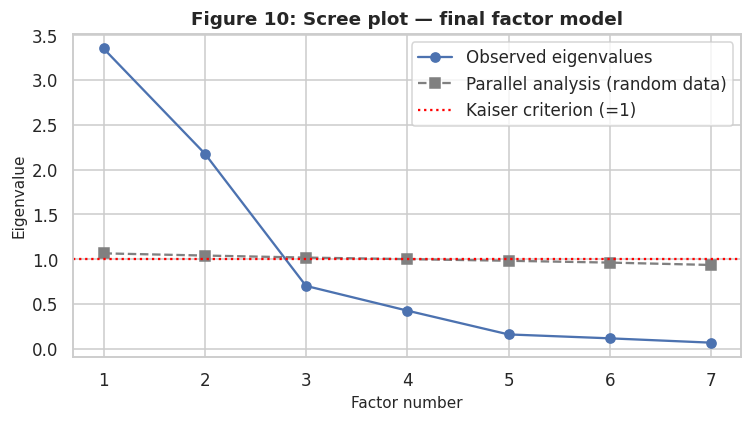

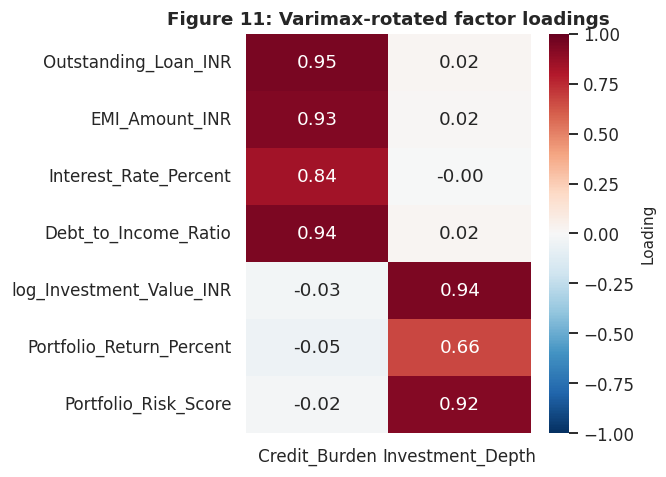

,Variable,MSA
0,Outstanding_Loan_INR,0.7440
1,EMI_Amount_INR,0.7490
2,Interest_Rate_Percent,0.8440
3,Debt_to_Income_Ratio,0.8470
4,log_Investment_Value_INR,0.5490
5,Portfolio_Return_Percent,0.8310
6,Portfolio_Risk_Score,0.5550
7,OVERALL KMO,0.7290


,Statistic,Value
0,Chi-square,"17,691.5400"
1,Degrees of freedom,21
2,p-value,0.000e+00


,Credit_Burden,Investment_Depth
SS loadings,3.3510,2.1800
Proportion of variance,0.4790,0.3110
Cumulative variance,0.4790,0.7900


,Credit_Burden,Investment_Depth,Communality
Outstanding_Loan_INR,0.9490,0.0200,0.9010
EMI_Amount_INR,0.9290,0.0150,0.8640
Interest_Rate_Percent,0.8380,-0.0010,0.7020
Debt_to_Income_Ratio,0.9380,0.0210,0.8800
log_Investment_Value_INR,-0.0290,0.9430,0.8910
Portfolio_Return_Percent,-0.0550,0.6640,0.4450
Portfolio_Risk_Score,-0.0230,0.9210,0.8480


In [22]:
fa_vars = ["Outstanding_Loan_INR", "EMI_Amount_INR", "Interest_Rate_Percent", "Debt_to_Income_Ratio",
           "log_Investment_Value_INR", "Portfolio_Return_Percent", "Portfolio_Risk_Score"]
Xfa = StandardScaler().fit_transform(df_clean[fa_vars])      # standardise: variables are on very different scales
msa, kmo_model = calculate_kmo(df_clean[fa_vars])
chi2_b, p_b = calculate_bartlett_sphericity(df_clean[fa_vars])
kmo_tbl = pd.DataFrame({"Variable": fa_vars + ["OVERALL KMO"], "MSA": list(np.round(msa, 3)) + [round(kmo_model, 3)]})
bart_tbl = pd.DataFrame({"Statistic": ["Chi-square", "Degrees of freedom", "p-value"],
                         "Value": [round(chi2_b, 2), len(fa_vars)*(len(fa_vars)-1)//2, f"{p_b:.3e}"]})
save_table(kmo_tbl, "T07b_kmo", index=False); save_table(bart_tbl, "T07c_bartlett", index=False)

fa0 = FactorAnalyzer(n_factors=len(fa_vars), rotation=None, method="principal"); fa0.fit(Xfa)
ev, _ = fa0.get_eigenvalues()
pa2 = np.mean([np.sort(np.linalg.eigvalsh(np.corrcoef(rng.normal(size=Xfa.shape), rowvar=False)))[::-1] for _ in range(50)], axis=0)
n_factors = int((ev > 1).sum())
print(f"KMO = {kmo_model:.3f}; Bartlett chi2 = {chi2_b:,.1f}, p = {p_b:.2e}; factors with eigenvalue > 1: {n_factors}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(ev)+1), ev, "o-", label="Observed eigenvalues")
ax.plot(range(1, len(ev)+1), pa2, "s--", color="grey", label="Parallel analysis (random data)")
ax.axhline(1, color="red", ls=":", label="Kaiser criterion (=1)")
ax.set(title="Figure 10: Scree plot — final factor model", xlabel="Factor number", ylabel="Eigenvalue"); ax.legend()
savefig("F10_scree")

fa = FactorAnalyzer(n_factors=n_factors, rotation="varimax", method="principal"); fa.fit(Xfa)
# Name factors from the loading pattern: the column on which EMI loads most heavily is the credit factor
emi_col = int(np.argmax(np.abs(fa.loadings_[fa_vars.index("EMI_Amount_INR")])))
order = [emi_col, 1-emi_col]
FACTOR_NAMES = ["Credit_Burden", "Investment_Depth"]
load = pd.DataFrame(fa.loadings_[:, order], index=fa_vars, columns=FACTOR_NAMES)
load["Communality"] = fa.get_communalities()
var_tbl = pd.DataFrame(np.array(fa.get_factor_variance())[:, order], index=["SS loadings", "Proportion of variance", "Cumulative variance"],
                       columns=FACTOR_NAMES)
var_tbl.loc["Cumulative variance"] = var_tbl.loc["Proportion of variance"].cumsum()
var_tbl = var_tbl.round(3)
save_table(load.round(3), "T07d_factor_loadings"); save_table(var_tbl, "T07e_factor_variance")

plt.figure(figsize=(6, 4.5))
sns.heatmap(load.iloc[:, :2], annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar_kws={"label": "Loading"})
plt.title("Figure 11: Varimax-rotated factor loadings"); plt.ylabel(""); savefig("F11_loadings")
scores = fa.transform(Xfa)
df_clean["F_Credit_Burden"] = scores[:, emi_col]
df_clean["F_Investment_Depth"] = scores[:, 1-emi_col]
display(kmo_tbl, bart_tbl, var_tbl); load.round(3)

**Method.** Standardised variables, principal-factor extraction, varimax rotation. Principal extraction was used because minres produced a Heywood case (communality = 1.0) for investment value.

**Result.** KMO = **0.729** ("middling–good", adequate). Bartlett χ²(21) = 17,691.5, p < 0.001, so the correlation matrix is not an identity. Two factors (eigenvalue > 1 and above parallel analysis) explain **79.0%** of variance.
* **Factor 1 — Credit Burden** (47.9%): outstanding loan 0.95, DTI 0.94, EMI 0.93, interest rate 0.84.
* **Factor 2 — Investment Depth** (31.1%): investment value 0.94, portfolio risk 0.92, portfolio return 0.66.

Cross-loadings are all < 0.06, giving a clean simple structure. Portfolio return has the weakest communality (0.45).

**Business interpretation.** Customers' balance-sheet relationship with the bank reduces to two independent dimensions: *how leveraged they are* and *how invested they are*. Part of each factor reflects holding vs. not holding the product (structural zeros), but within borrowers the loan variables remain strongly related (outstanding–EMI r = 0.86).

## 5. Cluster Analysis (K-Means on factor scores)

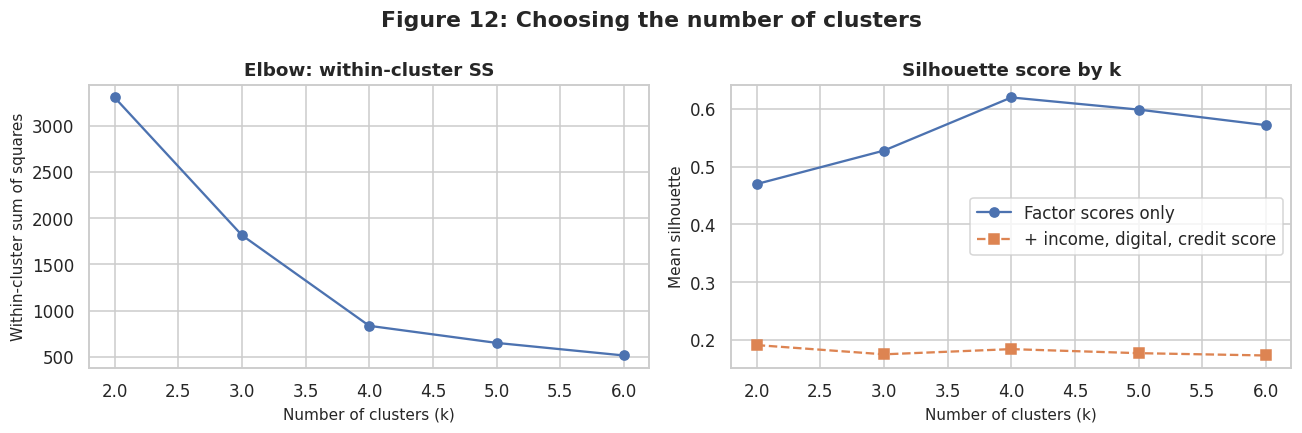

,k,Within-cluster SS (factor scores),Silhouette (factor scores),"Silhouette (factors + income, digital, credit score)",Cluster sizes
0,2,"3,306.3000",0.4700,0.1910,"[1726, 1274]"
1,3,"1,815.6000",0.5280,0.1750,"[1144, 958, 898]"
2,4,834.7000,0.6200,0.1840,"[890, 835, 670, 605]"
3,5,649.9000,0.5990,0.1770,"[751, 669, 602, 510, 468]"
4,6,513.7000,0.5720,0.1730,"[745, 570, 515, 466, 389, 315]"


In [23]:
Zc = StandardScaler().fit_transform(df_clean[["F_Credit_Burden", "F_Investment_Depth"]])
Zc_alt = np.column_stack([Zc, StandardScaler().fit_transform(df_clean[["log_Annual_Income_INR", "Digital_Engagement_Score", "Credit_Score"]])])
rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Zc)
    km_alt = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Zc_alt)
    rows.append([k, round(km.inertia_, 1), round(silhouette_score(Zc, km.labels_), 3),
                 round(silhouette_score(Zc_alt, km_alt.labels_), 3), sorted(np.bincount(km.labels_).tolist(), reverse=True)])
kval = pd.DataFrame(rows, columns=["k", "Within-cluster SS (factor scores)", "Silhouette (factor scores)",
                                   "Silhouette (factors + income, digital, credit score)", "Cluster sizes"])
save_table(kval, "T08a_k_selection", index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(kval.k, kval.iloc[:, 1], "o-"); ax[0].set(title="Elbow: within-cluster SS", xlabel="Number of clusters (k)", ylabel="Within-cluster sum of squares")
ax[1].plot(kval.k, kval.iloc[:, 2], "o-", label="Factor scores only")
ax[1].plot(kval.k, kval.iloc[:, 3], "s--", label="+ income, digital, credit score")
ax[1].set(title="Silhouette score by k", xlabel="Number of clusters (k)", ylabel="Mean silhouette"); ax[1].legend()
fig.suptitle("Figure 12: Choosing the number of clusters", fontweight="bold"); savefig("F12_k_selection")
kval

**Result.** On factor scores, silhouette peaks at **k = 4 (0.620)**, above k = 3 (0.528) and k = 5 (0.599), and the elbow in within-cluster SS also sits at k = 4. Adding income, digital score and credit score collapses silhouette to 0.17–0.19 for every k. These variables have no natural grouping and only add noise.

**Decision.** k = 4 on the two factor scores: best statistical separation and a directly interpretable 2×2 structure.

Chosen k = 4, silhouette = 0.620


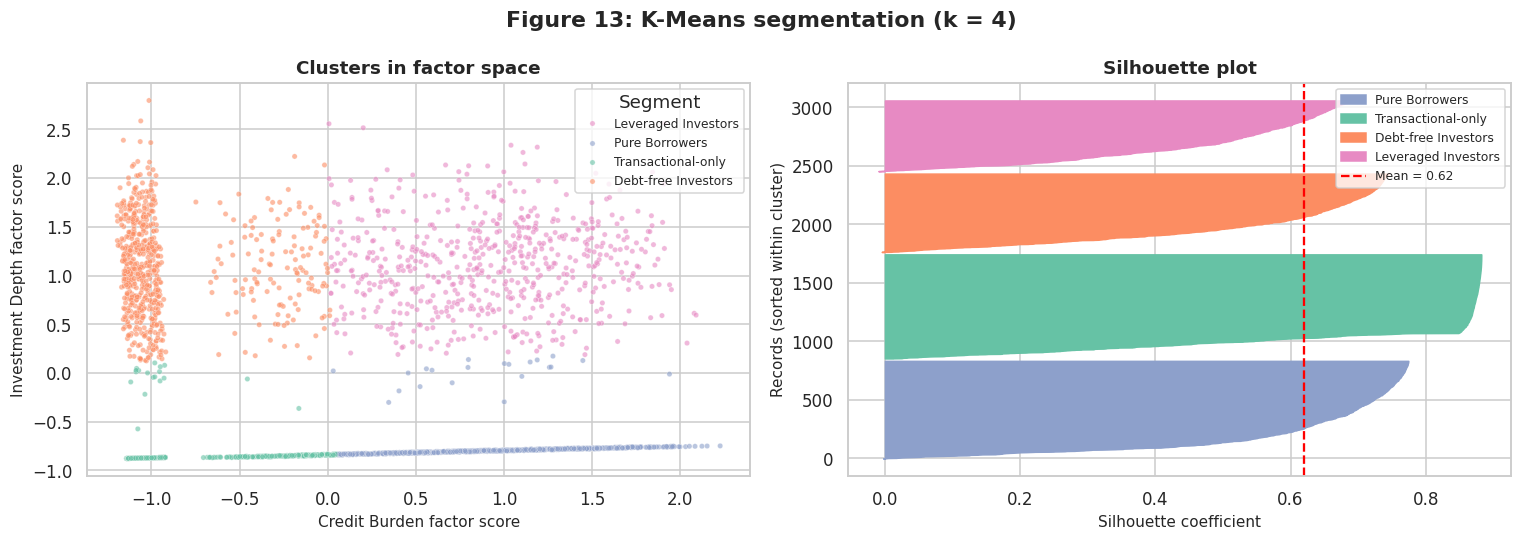

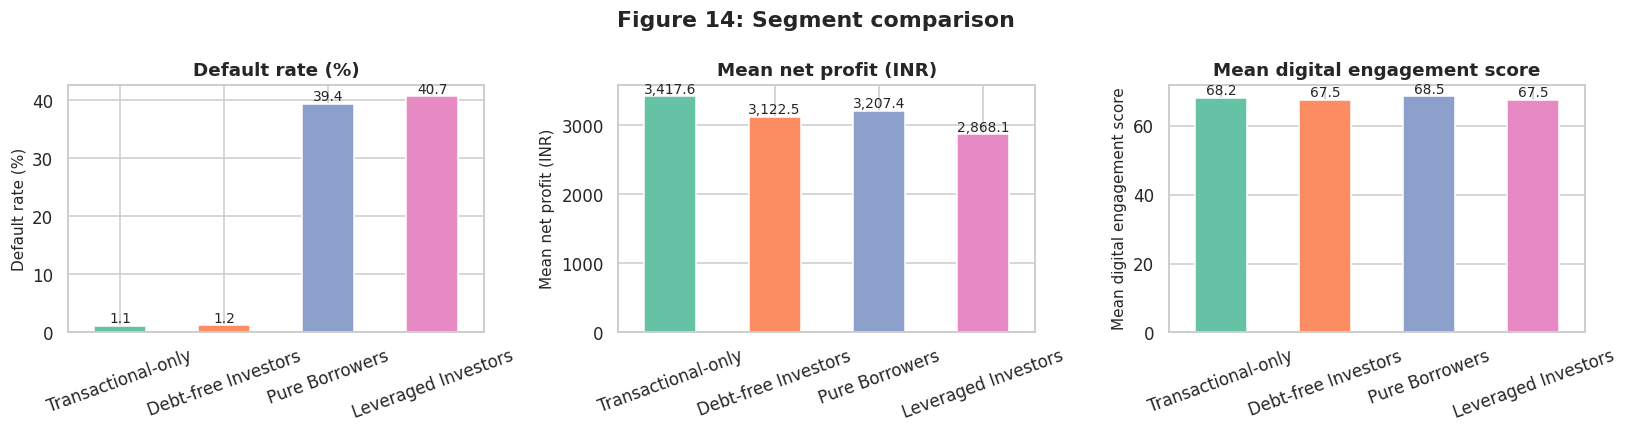

,Test,Statistic,p_value
0,Net profit (Kruskal-Wallis),5.7725,0.1232
1,Default rate (Chi-square),710.2888,0.0000
2,Digital score (Kruskal-Wallis),1.7288,0.6305
3,Income (Kruskal-Wallis),21.9027,0.0001
4,CLV (Kruskal-Wallis),10.3835,0.0156


Segment_Name,Transactional-only,Debt-free Investors,Pure Borrowers,Leveraged Investors
Size,890.0000,670.0000,835.0000,605.0000
Loan_Holders_pct,22.6000,20.4000,100.0000,100.0000
Investors_pct,2.0000,100.0000,2.5000,100.0000
F_Credit_Burden,-0.9000,-0.9000,1.0000,0.9000
F_Investment_Depth,-0.9000,1.1000,-0.8000,1.1000
Age,48.3000,48.2000,47.7000,46.7000
Median_Income_INR,"871,989.0000","919,137.5000","803,339.0000","787,365.0000"
Credit_Score,721.7000,721.2000,716.8000,726.8000
Debt_to_Income,0.2000,0.2000,0.9000,0.9000
Median_EMI_INR,0.0000,0.0000,"89,122.6000","87,783.9000"


In [24]:
K = int(kval.loc[kval["Silhouette (factor scores)"].idxmax(), "k"])
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Zc)
df_clean["Cluster"] = km.labels_
sil = silhouette_score(Zc, km.labels_); print(f"Chosen k = {K}, silhouette = {sil:.3f}")

prof = df_clean.groupby("Cluster").agg(
    Size=("Age", "size"), Loan_Holders_pct=("Has_Loan", lambda s: s.mean()*100),
    Investors_pct=("Has_Investment_Product_bin", lambda s: s.mean()*100),
    F_Credit_Burden=("F_Credit_Burden", "mean"), F_Investment_Depth=("F_Investment_Depth", "mean"),
    Age=("Age", "mean"), Median_Income_INR=("Annual_Income_INR", "median"), Credit_Score=("Credit_Score", "mean"),
    Debt_to_Income=("Debt_to_Income_Ratio", "mean"), Median_EMI_INR=("EMI_Amount_INR", "median"),
    Median_Investment_INR=("Investment_Value_INR", "median"), Txns_30d=("Transactions_Last_30_Days", "mean"),
    Digital_Score=("Digital_Engagement_Score", "mean"), Satisfaction=("Customer_Satisfaction_Score", "mean"),
    Tenure_Months=("Customer_Tenure_Months", "mean"), Mean_Net_Profit_INR=("Net_Profit_INR", "mean"),
    Loss_Making_pct=("Net_Profit_INR", lambda s: (s < 0).mean()*100), Median_CLV_INR=("Customer_Lifetime_Value_INR", "median"),
    Default_Rate_pct=("Default", lambda s: s.mean()*100))

def name_cluster(r):
    loan = "Borrowers" if r.Loan_Holders_pct > 50 else "Non-borrowers"
    inv_ = "Investors" if r.Investors_pct > 50 else "Non-investors"
    return {("Borrowers", "Investors"): "Leveraged Investors", ("Borrowers", "Non-investors"): "Pure Borrowers",
            ("Non-borrowers", "Investors"): "Debt-free Investors", ("Non-borrowers", "Non-investors"): "Transactional-only"}[(loan, inv_)]
prof["Segment_Name"] = prof.apply(name_cluster, axis=1)
df_clean["Segment_Name"] = df_clean.Cluster.map(prof.Segment_Name)
prof = prof.set_index("Segment_Name").sort_values("Default_Rate_pct")
save_table(prof.round(2), "T08b_cluster_profiles")

# statistical tests of differences across clusters
kw_np_c = stats.kruskal(*[g.Net_Profit_INR for _, g in df_clean.groupby("Segment_Name")])
chi_def_c = stats.chi2_contingency(pd.crosstab(df_clean.Segment_Name, df_clean.Default))
kw_dig_c = stats.kruskal(*[g.Digital_Engagement_Score for _, g in df_clean.groupby("Segment_Name")])
kw_inc_c = stats.kruskal(*[g.Annual_Income_INR for _, g in df_clean.groupby("Segment_Name")])
kw_clv_c = stats.kruskal(*[g.Customer_Lifetime_Value_INR for _, g in df_clean.groupby("Segment_Name")])
clus_tests = pd.DataFrame({"Test": ["Net profit (Kruskal-Wallis)", "Default rate (Chi-square)", "Digital score (Kruskal-Wallis)",
                                    "Income (Kruskal-Wallis)", "CLV (Kruskal-Wallis)"],
                           "Statistic": [kw_np_c.statistic, chi_def_c[0], kw_dig_c.statistic, kw_inc_c.statistic, kw_clv_c.statistic],
                           "p_value": [kw_np_c.pvalue, chi_def_c[1], kw_dig_c.pvalue, kw_inc_c.pvalue, kw_clv_c.pvalue]}).round(4)
save_table(clus_tests, "T08c_cluster_tests", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pal = dict(zip(prof.index, sns.color_palette("Set2", K)))
sns.scatterplot(x=df_clean.F_Credit_Burden, y=df_clean.F_Investment_Depth, hue=df_clean.Segment_Name, palette=pal, s=12, alpha=.6, ax=ax[0])
ax[0].set(title="Clusters in factor space", xlabel="Credit Burden factor score", ylabel="Investment Depth factor score"); ax[0].legend(title="Segment", fontsize=8)
sil_s = silhouette_samples(Zc, km.labels_); y0 = 0
for c in range(K):
    vals = np.sort(sil_s[km.labels_ == c]); nm = df_clean.loc[df_clean.Cluster == c, "Segment_Name"].iloc[0]
    ax[1].fill_betweenx(np.arange(y0, y0+len(vals)), 0, vals, color=pal[nm], label=nm); y0 += len(vals)+20
ax[1].axvline(sil, color="red", ls="--", label=f"Mean = {sil:.2f}")
ax[1].set(title="Silhouette plot", xlabel="Silhouette coefficient", ylabel="Records (sorted within cluster)"); ax[1].legend(fontsize=8, loc="upper right")
fig.suptitle(f"Figure 13: K-Means segmentation (k = {K})", fontweight="bold"); savefig("F13_clusters")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, lab in zip(ax, ["Default_Rate_pct", "Mean_Net_Profit_INR", "Digital_Score"], ["Default rate (%)", "Mean net profit (INR)", "Mean digital engagement score"]):
    prof[col].plot.bar(ax=a, color=[pal[i] for i in prof.index]); a.set(title=lab, xlabel="", ylabel=lab); a.tick_params(axis="x", rotation=20)
    for i, val in enumerate(prof[col]): a.text(i, val, f"{val:,.1f}", ha="center", va="bottom", fontsize=9)
fig.suptitle("Figure 14: Segment comparison", fontweight="bold"); savefig("F14_segment_bars")
display(clus_tests); prof.round(1).T

**Cluster profiles (names reflect the actual profile, not assumptions):**

| Segment | Size | Profile | Default | Mean profit |
|---|---|---|---|---|
| Transactional-only | 890 | 22.6% have a loan, 2% invest, DTI 0.20 | 1.1% | ₹3,418 |
| Debt-free Investors | 670 | 100% invest (median ₹26.1 lakh), 20% have a loan | 1.2% | ₹3,123 |
| Pure Borrowers | 835 | 100% have a loan, median EMI ₹89k, DTI 0.86 | 39.4% | ₹3,207 |
| Leveraged Investors | 605 | 100% loan + 100% invest, DTI 0.87 | 40.7% | ₹2,868 |

**Statistical tests.** Default rate differs sharply (χ² = 710.3, p < 0.001). Income (p = 0.0001) and CLV (p = 0.016) differ modestly: borrower segments have lower median income. Net profit (p = 0.12) and digital score (p = 0.63) do **not** differ.

**Business interpretation.** Segments are sharply different on risk but not on profit. Both borrower segments earn the same per-record profit as non-borrowers while carrying ~35× the default rate. Their risk is not being priced into observed profit.

## 6. Customer Profitability Model (target: Net_Profit_INR)
### 6.1 Customer-grouped train/test split, candidate predictors, VIF screening

In [25]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(df_clean, groups=df_clean.Customer_ID))
groups_train = df_clean.Customer_ID.iloc[train_idx].values
print(f"Train rows {len(train_idx)}, test rows {len(test_idx)}; Customer_IDs shared across sets: "
      f"{len(set(df_clean.Customer_ID.iloc[train_idx]) & set(df_clean.Customer_ID.iloc[test_idx]))}")

seg_d = pd.get_dummies(df_clean.Customer_Segment, prefix="Seg", drop_first=True, dtype=int)   # reference: Corporate
profit_pool = ["Age", "log_Annual_Income_INR", "Credit_Score", "Customer_Tenure_Months", "Credit_Limit_INR",
               "Credit_Utilization_Ratio", "Outstanding_Loan_INR", "Interest_Rate_Percent", "EMI_Amount_INR",
               "Debt_to_Income_Ratio", "Account_Balance_Before_INR", "Transactions_Last_30_Days",
               "log_Average_Monthly_Spend_INR", "Days_Since_Last_Transaction", "Mobile_App_Logins_Month",
               "IB_Usage_Ord", "Digital_Engagement_Score", "Customer_Satisfaction_Score", "Complaint_Count",
               "log_Investment_Value_INR", "Portfolio_Return_Percent", "Has_Credit_Card_bin", "Has_Insurance_bin", "Has_Loan"]
Xp_all = pd.concat([df_clean[profit_pool], seg_d], axis=1).astype(float)
yp = df_clean.Net_Profit_INR

def vif_table(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i+1) for i in range(X.shape[1])], index=X.columns)

vif_before = vif_table(Xp_all)
cols, dropped = list(Xp_all.columns), []
while True:
    vv = vif_table(Xp_all[cols])
    if vv.max() < 5: break
    dropped.append((vv.idxmax(), round(vv.max(), 2))); cols.remove(vv.idxmax())
vif_after = vif_table(Xp_all[cols])
print("Dropped for VIF >= 5:", dropped)
print("Screening correlations with Net_Profit (|r| top 6):")
print(Xp_all.corrwith(yp).abs().sort_values(ascending=False).head(6).round(3))
vif_tbl = pd.DataFrame({"VIF_before": vif_before.round(2), "VIF_after": vif_after.round(2)})
save_table(vif_tbl, "T09a_profit_vif"); vif_tbl.sort_values("VIF_before", ascending=False).head(10)

Train rows 2249, test rows 751; Customer_IDs shared across sets: 0


Dropped for VIF >= 5: [('Has_Loan', np.float64(10.99)), ('Outstanding_Loan_INR', np.float64(9.12)), ('Debt_to_Income_Ratio', np.float64(5.26))]
Screening correlations with Net_Profit (|r| top 6):
Complaint_Count             0.0740
Transactions_Last_30_Days   0.0410
Digital_Engagement_Score    0.0380
Outstanding_Loan_INR        0.0360
EMI_Amount_INR              0.0360
log_Investment_Value_INR    0.0290
dtype: float64


,VIF_before,VIF_after
Has_Loan,10.9900,NaN
Outstanding_Loan_INR,9.1400,NaN
Interest_Rate_Percent,8.3900,1.7000
EMI_Amount_INR,7.7100,1.7000
Debt_to_Income_Ratio,6.6200,NaN
Seg_Retail,4.9100,4.9000
Seg_Mass Affluent,3.6100,3.6100
Seg_SME,2.8500,2.8500
Seg_HNI,2.2400,2.2300
Portfolio_Return_Percent,1.2800,1.2800


**Customer-level split.** GroupShuffleSplit (25% test) by Customer_ID: 2,249 train / 751 test rows, with **0 IDs shared**. The same split is reused for every model.

**Predictor pool.** 24 non-leaky variables (demographics, credit, transaction, digital, investment, relationship) plus 4 segment dummies. Revenue, cost, Profitability_Score and CLV are excluded.

**Screening.** No predictor has |r| > 0.075 with net profit; the largest is complaint count (−0.074). VIF pruning removed Has_Loan (11.0), Outstanding_Loan (9.1) and DTI (5.3). All remaining VIFs are < 5.

### 6.2 Multiple linear regression (OLS)

                            OLS Regression Results                            
Dep. Variable:         Net_Profit_INR   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     1.300
Date:                Sat, 26 Sep 2026   Prob (F-statistic):              0.146
Time:                        09:45:41   Log-Likelihood:                -22341.
No. Observations:                2249   AIC:                         4.473e+04
Df Residuals:                    2223   BIC:                         4.488e+04
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

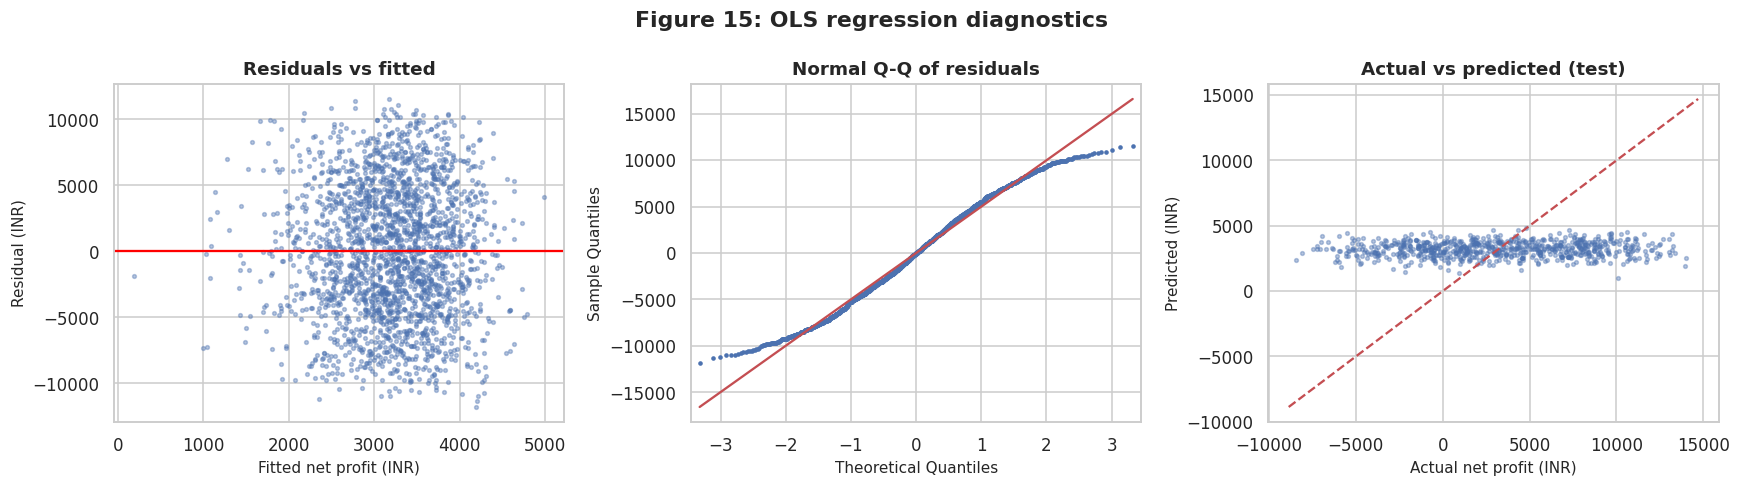

,Coefficient,Std_Error,t,p_value,CI_low,CI_high
Transactions_Last_30_Days,41.9672,22.4558,1.8689,0.0618,-2.0693,86.0038
Digital_Engagement_Score,9.7130,5.5972,1.7353,0.0828,-1.2633,20.6894
Complaint_Count,-442.8342,134.5744,-3.2906,0.0010,-706.7389,-178.9296
Seg_Retail,862.0967,458.4169,1.8806,0.0602,-36.8734,"1,761.0669"


In [26]:
Xp = Xp_all[cols]
Xtr_p, Xte_p, ytr_p, yte_p = Xp.iloc[train_idx], Xp.iloc[test_idx], yp.iloc[train_idx], yp.iloc[test_idx]
ols = sm.OLS(ytr_p, sm.add_constant(Xtr_p)).fit()
print(ols.summary())
coef_ols = pd.DataFrame({"Coefficient": ols.params, "Std_Error": ols.bse, "t": ols.tvalues, "p_value": ols.pvalues,
                         "CI_low": ols.conf_int()[0], "CI_high": ols.conf_int()[1]}).round(4)
save_table(coef_ols, "T09b_ols_coefficients")

def reg_metrics(y, yhat, p):
    n = len(y); r2 = r2_score(y, yhat)
    return {"R2": r2, "Adj_R2": 1-(1-r2)*(n-1)/(n-p-1), "RMSE": np.sqrt(mean_squared_error(y, yhat)), "MAE": mean_absolute_error(y, yhat)}
p_ols = Xp.shape[1]
m_ols_tr = reg_metrics(ytr_p, ols.predict(sm.add_constant(Xtr_p)), p_ols)
m_ols_te = reg_metrics(yte_p, ols.predict(sm.add_constant(Xte_p, has_constant="add")), p_ols)
m_base = reg_metrics(yte_p, np.full(len(yte_p), ytr_p.mean()), 0)
print("OLS train:", {k: round(v, 4) for k, v in m_ols_tr.items()})
print("OLS test :", {k: round(v, 4) for k, v in m_ols_te.items()})
print("Naive mean baseline test:", {k: round(v, 4) for k, v in m_base.items()})
print(f"F-test p-value (train): {ols.f_pvalue:.4f}")
bp = het_breuschpagan(ols.resid, sm.add_constant(Xtr_p)); jb = stats.jarque_bera(ols.resid)
print(f"Breusch-Pagan p = {bp[1]:.4f}; Jarque-Bera p = {jb.pvalue:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(ols.fittedvalues, ols.resid, s=6, alpha=.4); ax[0].axhline(0, color="red")
ax[0].set(title="Residuals vs fitted", xlabel="Fitted net profit (INR)", ylabel="Residual (INR)")
sm.qqplot(ols.resid, line="s", ax=ax[1], markersize=2); ax[1].set_title("Normal Q-Q of residuals")
ax[2].scatter(yte_p, ols.predict(sm.add_constant(Xte_p, has_constant="add")), s=6, alpha=.4)
ax[2].plot([yp.min(), yp.max()], [yp.min(), yp.max()], "r--"); ax[2].set(title="Actual vs predicted (test)", xlabel="Actual net profit (INR)", ylabel="Predicted (INR)")
fig.suptitle("Figure 15: OLS regression diagnostics", fontweight="bold"); savefig("F15_ols_diagnostics")
coef_ols[coef_ols.p_value < 0.10]

**Result.** Train R² = 0.014, adjusted R² = 0.003. The overall F-test is **not significant (p = 0.146)**. On test data, R² = −0.0001 (RMSE ₹4,872, MAE ₹4,083), which is no better than predicting the average (RMSE ₹4,872).

**Only significant coefficient:** `Complaint_Count` = **−₹443 per complaint** (p = 0.001, 95% CI −₹707 to −₹179), holding other variables constant. Transactions in the last 30 days (+₹42 each, p = 0.062) and digital score (+₹9.7 per point, p = 0.083) are marginal at 10% only.

**Diagnostics.** Breusch-Pagan p = 0.39 (no evidence of heteroscedasticity); Durbin-Watson = 2.03; Jarque-Bera p < 0.001 because residuals are light-tailed (kurtosis 2.2, flat-topped Q-Q — net profit is near-uniform). With n = 2,249 the coefficient tests remain valid by the CLT. The large condition number (5.1e7) reflects unscaled rupee variables, not collinearity (all VIF < 5).

**Business interpretation.** Observable customer characteristics explain **about 1% of profit variation**. Profit per record is driven by revenue and cost items not captured by any customer attribute in the file. The model cannot be used to target "profitable customers"; its single defensible insight is that complaints erode profit.

## 7. Ridge and Lasso (same predictor set, alpha chosen by customer-grouped 5-fold CV)

Ridge best alpha = 5541.020; Lasso best alpha = 100.000


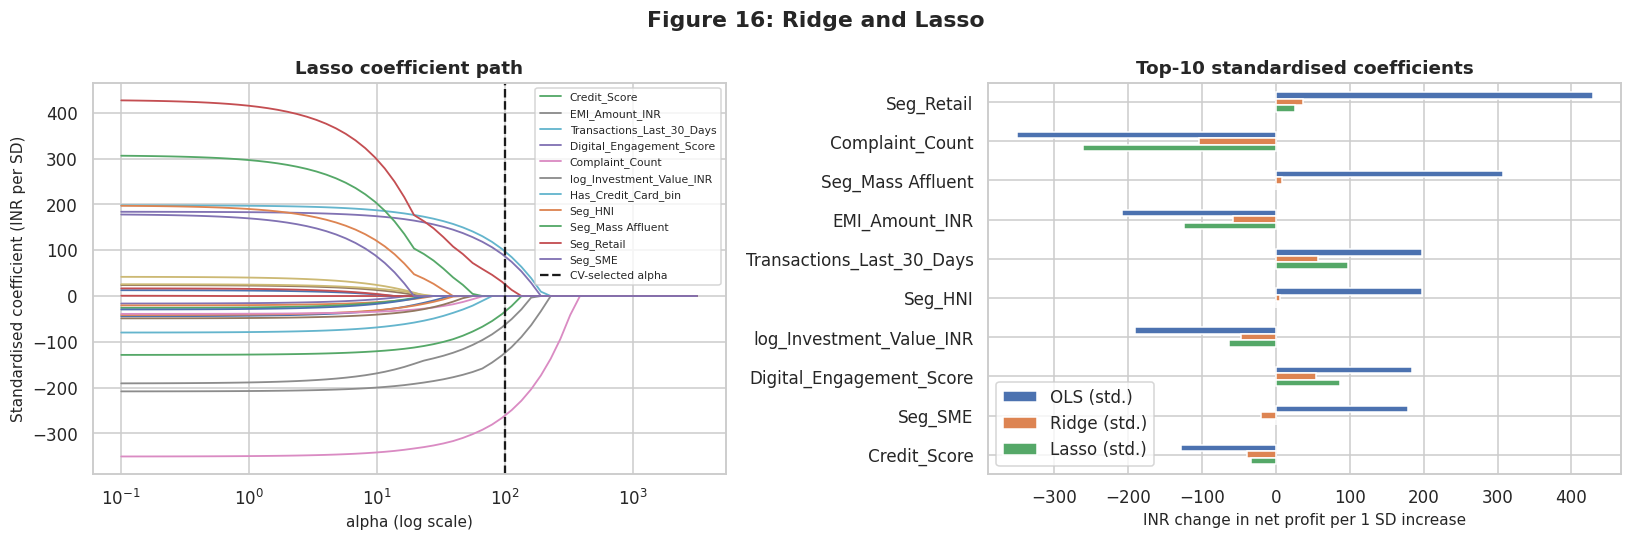

5-fold grouped CV R2 on full data: {'OLS': -0.0071, 'Lasso': 0.002}


,Model,Train R2,Test R2,Test Adj. R2,Test RMSE (INR),Test MAE (INR),Non-zero coefficients
0,Linear Regression (OLS),0.0144,-0.0001,-0.0346,"4,872.0826","4,083.1906",25
1,Ridge,0.0069,0.0026,-0.0318,"4,865.3270","4,086.4289",25
2,Lasso,0.0098,0.0067,-0.0276,"4,855.3933","4,077.3095",7
3,Naive baseline (predict train mean),0.0000,-0.0002,NaN,"4,872.1214","4,095.4071",0


,OLS (std.),Ridge (std.),Lasso (std.),Lasso retained
Seg_Retail,428.7300,36.7900,25.6200,Yes
Complaint_Count,-350.5800,-103.4100,-260.9800,Yes
Seg_Mass Affluent,307.5500,8.4500,0.0000,No
EMI_Amount_INR,-208.3700,-58.4000,-123.9800,Yes
Transactions_Last_30_Days,198.3000,57.1700,97.3600,Yes
Seg_HNI,197.9100,5.1000,0.0000,No
log_Investment_Value_INR,-190.9900,-46.8100,-62.7900,Yes
Digital_Engagement_Score,184.1500,54.3800,86.5100,Yes
Seg_SME,178.9800,-20.3500,-0.0000,No
Credit_Score,-128.6900,-38.4300,-33.9700,Yes


In [27]:
gkf = GroupKFold(n_splits=5)
ridge_gs = GridSearchCV(Pipeline([("sc", StandardScaler()), ("m", Ridge())]), {"m__alpha": np.logspace(-2, 5, 40)},
                        cv=gkf, scoring="neg_mean_squared_error").fit(Xtr_p, ytr_p, groups=groups_train)
lasso_gs = GridSearchCV(Pipeline([("sc", StandardScaler()), ("m", Lasso(max_iter=50000))]), {"m__alpha": np.logspace(-1, 3.5, 40)},
                        cv=gkf, scoring="neg_mean_squared_error").fit(Xtr_p, ytr_p, groups=groups_train)
lin_std = Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]).fit(Xtr_p, ytr_p)
print(f"Ridge best alpha = {ridge_gs.best_params_['m__alpha']:.3f}; Lasso best alpha = {lasso_gs.best_params_['m__alpha']:.3f}")

rows = []
for name, mdl in [("Linear Regression (OLS)", lin_std), ("Ridge", ridge_gs.best_estimator_), ("Lasso", lasso_gs.best_estimator_)]:
    nz = int(np.sum(np.abs(mdl.named_steps["m"].coef_) > 1e-8))
    mt = reg_metrics(yte_p, mdl.predict(Xte_p), p_ols); mtr = reg_metrics(ytr_p, mdl.predict(Xtr_p), p_ols)
    rows.append([name, mtr["R2"], mt["R2"], mt["Adj_R2"], mt["RMSE"], mt["MAE"], nz])
rows.append(["Naive baseline (predict train mean)", 0, m_base["R2"], np.nan, m_base["RMSE"], m_base["MAE"], 0])
reg_cmp = pd.DataFrame(rows, columns=["Model", "Train R2", "Test R2", "Test Adj. R2", "Test RMSE (INR)", "Test MAE (INR)", "Non-zero coefficients"]).round(4)
save_table(reg_cmp, "T10a_regression_comparison", index=False)

coefs = pd.DataFrame({"OLS (std.)": lin_std.named_steps["m"].coef_, "Ridge (std.)": ridge_gs.best_estimator_.named_steps["m"].coef_,
                      "Lasso (std.)": lasso_gs.best_estimator_.named_steps["m"].coef_}, index=cols).round(2)
coefs["Lasso retained"] = np.where(coefs["Lasso (std.)"].abs() > 1e-8, "Yes", "No")
coefs = coefs.reindex(coefs["OLS (std.)"].abs().sort_values(ascending=False).index)
save_table(coefs, "T10b_ridge_lasso_coefficients")

# Lasso path for visual variable selection
alphas = np.logspace(-1, 3.5, 60); sc_ = StandardScaler().fit(Xtr_p); Xs_ = sc_.transform(Xtr_p)
path = np.array([Lasso(alpha=a, max_iter=50000).fit(Xs_, ytr_p).coef_ for a in alphas])
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for j, c in enumerate(cols):
    ax[0].plot(alphas, path[:, j], lw=1.2, label=c if abs(coefs.loc[c, "OLS (std.)"]) >= 60 else None)
ax[0].axvline(lasso_gs.best_params_["m__alpha"], color="k", ls="--", label="CV-selected alpha")
ax[0].set(xscale="log", title="Lasso coefficient path", xlabel="alpha (log scale)", ylabel="Standardised coefficient (INR per SD)"); ax[0].legend(fontsize=7)
top = coefs.head(10)[["OLS (std.)", "Ridge (std.)", "Lasso (std.)"]]
top.plot.barh(ax=ax[1]); ax[1].invert_yaxis(); ax[1].set(title="Top-10 standardised coefficients", xlabel="INR change in net profit per 1 SD increase", ylabel="")
fig.suptitle("Figure 16: Ridge and Lasso", fontweight="bold"); savefig("F16_ridge_lasso")
cv_r2 = {n: cross_val_predict(m, Xp, yp, cv=gkf, groups=df_clean.Customer_ID) for n, m in
         [("OLS", Pipeline([("sc", StandardScaler()), ("m", LinearRegression())])),
          ("Lasso", Pipeline([("sc", StandardScaler()), ("m", Lasso(alpha=lasso_gs.best_params_["m__alpha"], max_iter=50000))]))]}
print("5-fold grouped CV R2 on full data:", {n: round(r2_score(yp, v_), 4) for n, v_ in cv_r2.items()})
display(reg_cmp); coefs

**Why Ridge:** it shrinks correlated coefficients (the loan and spend blocks) towards each other, reducing variance. **Why Lasso:** its L1 penalty can set weak coefficients exactly to zero, performing variable selection. Alpha is chosen by 5-fold CV grouped by Customer_ID. Predictors are standardised first, because the penalty is scale-dependent.

**Result.** Ridge α ≈ 5,541 (very heavy shrinkage) and Lasso α = 100. All three models have test R² between −0.0001 and 0.007 and RMSE of ₹4,855–4,872, i.e., the same as the naive mean. Lasso keeps 7 of 25 predictors: **complaint count (−₹261/SD), transactions last 30 days (+₹97/SD), digital score (+₹87/SD), EMI (−₹124/SD), investment value (−₹63/SD), credit score (−₹34/SD), Retail dummy (+₹26/SD)**. It removes the rest, including income, age, tenure and segment labels. Grouped 5-fold CV R² on all data is −0.007 (OLS) and 0.002 (Lasso).

**Which model is "best"?** None has usable predictive power, so model choice is not the issue. Lasso is preferred **for interpretation only**: it gives the most parsimonious list and the lowest error by a trivial margin. The heavy optimal penalties confirm that most signal is noise. Complaint count is the only driver that is consistent across OLS (p = 0.001), Ridge and Lasso.

### 7.1 Supplementary check — what does explain long-term value (CLV)?

In [28]:
ylc = df_clean.log_Customer_Lifetime_Value_INR
clv_ols = sm.OLS(ylc.iloc[train_idx], sm.add_constant(Xp.iloc[train_idx])).fit()
m_clv = reg_metrics(ylc.iloc[test_idx], clv_ols.predict(sm.add_constant(Xp.iloc[test_idx], has_constant="add")), p_ols)
clv_coef = pd.DataFrame({"Coefficient": clv_ols.params, "p_value": clv_ols.pvalues}).round(4)
clv_coef = clv_coef[clv_coef.p_value < 0.05].drop("const", errors="ignore")
clv_coef["Interpretation"] = ["Elasticity: +1% in variable -> ~{:.2f}% change in CLV".format(b) if i.startswith("log_")
                              else "+1 unit -> ~{:.2f}% change in CLV".format((np.exp(b)-1)*100) for i, b in clv_coef.Coefficient.items()]
print("CLV model (log CLV) test:", {k: round(v, 4) for k, v in m_clv.items()})
save_table(clv_coef, "T10c_clv_significant"); clv_coef

CLV model (log CLV) test: {'R2': 0.5558, 'Adj_R2': 0.5405, 'RMSE': np.float64(0.6398), 'MAE': 0.5131}


,Coefficient,p_value,Interpretation
log_Annual_Income_INR,0.9912,0.0000,Elasticity: +1% in variable -> ~0.99% change i...
log_Average_Monthly_Spend_INR,0.0255,0.0222,Elasticity: +1% in variable -> ~0.03% change i...


**Result.** Using the same predictors, log(CLV) is explained well (test R² = **0.556**, adj. R² 0.541). Income is the dominant driver, with an elasticity of 0.99: a 1% higher income ≈ 1% higher CLV. Monthly spend adds a small effect (elasticity 0.03, p = 0.022).

**Business interpretation.** The bank's CLV metric is essentially income-driven. It captures long-term *potential*, while current-period net profit shows no relationship to income (r = −0.012). Management should not assume that high-CLV customers are currently profitable.

## 8. Default-Risk Modelling (target: Target_Default, Yes = 1)
### 8.1 Class distribution, leakage exclusions and feature set

In [29]:
cls = df_clean.Target_Default.value_counts().to_frame("Records"); cls["Share_%"] = (cls.Records/len(df_clean)*100).round(2)
print(cls)
print("EXCLUDED as leakage: Default_Probability (Default = Yes exactly when > 0.45), Credit_Risk_Category (band of Default_Probability).")
print("EXCLUDED on policy grounds: Gender (protected attribute in credit decisions). Fraud features: different business question.")

def dummies(col, ref):
    d = pd.get_dummies(df_clean[col].astype(str), prefix=col.split("_")[0][:4], dtype=int)
    return d.drop(columns=[c for c in d.columns if c.endswith("_" + ref)])

def_num = ["Credit_Score", "Credit_Utilization_Ratio", "Credit_Limit_INR", "Outstanding_Loan_INR", "Interest_Rate_Percent",
           "EMI_Amount_INR", "Debt_to_Income_Ratio", "Annual_Income_INR", "Account_Balance_Before_INR", "Customer_Tenure_Months",
           "Transactions_Last_30_Days", "Average_Monthly_Spend_INR", "Days_Since_Last_Transaction", "Age"]
D_loan = dummies("Loan_Product", "No Loan"); D_acct = dummies("Primary_Account_Type", "Savings")
D_occ = dummies("Occupation", "Salaried"); D_seg = dummies("Customer_Segment", "Retail")
X_tree = pd.concat([df_clean[def_num], D_loan, D_acct, D_occ, D_seg], axis=1).astype(float)   # raw units -> readable thresholds
yd = df_clean.Default
Xtr_t, Xte_t, ytr_d, yte_d = X_tree.iloc[train_idx], X_tree.iloc[test_idx], yd.iloc[train_idx], yd.iloc[test_idx]
print(f"Default rate train {ytr_d.mean()*100:.2f}% | test {yte_d.mean()*100:.2f}%")
print("Imbalance treatment: class_weight='balanced' (errors on the 20% default class weighted ~4x); metrics reported beyond accuracy.")

def clf_metrics(name, y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"Model": name, "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred), "ROC_AUC": roc_auc_score(y, prob)}
save_table(cls, "T11a_default_class_distribution"); cls

                Records  Share_%
Target_Default                  
No                 2407  80.2300
Yes                 593  19.7700
EXCLUDED as leakage: Default_Probability (Default = Yes exactly when > 0.45), Credit_Risk_Category (band of Default_Probability).
EXCLUDED on policy grounds: Gender (protected attribute in credit decisions). Fraud features: different business question.
Default rate train 20.14% | test 18.64%
Imbalance treatment: class_weight='balanced' (errors on the 20% default class weighted ~4x); metrics reported beyond accuracy.


,Records,Share_%
Target_Default,,
No,2407,80.2300
Yes,593,19.7700


**Class balance.** 80.2% No / 19.8% Yes (train 20.1%, test 18.6%). This is moderate imbalance: a model predicting "No" for everyone would score 81% accuracy, so accuracy alone is misleading. All three classifiers use `class_weight="balanced"`, which re-weights the default class ~4× in the loss (no synthetic records are created). Recall, precision, F1 and ROC-AUC are reported alongside accuracy.

### 8.2 Logistic regression

In [30]:
X_lr_all = X_tree.copy()
X_lr_all["log_Annual_Income_INR"] = np.log1p(X_lr_all.pop("Annual_Income_INR"))
X_lr_all["log_Average_Monthly_Spend_INR"] = np.log1p(X_lr_all.pop("Average_Monthly_Spend_INR"))
# Business-logic protection: Debt_to_Income_Ratio is the standard, income-normalised burden measure used in
# credit policy, so it is kept and its collinear components (EMI, outstanding loan, rate) compete for removal instead.
PROTECT = ["Debt_to_Income_Ratio"]
lr_cols, lr_dropped = list(X_lr_all.columns), []
while True:
    vv = vif_table(X_lr_all[lr_cols]).drop(PROTECT)
    if vv.max() < 5: break
    lr_dropped.append((vv.idxmax(), round(vv.max(), 2))); lr_cols.remove(vv.idxmax())
print("Max VIF after pruning:", round(vif_table(X_lr_all[lr_cols]).max(), 2))
print("Dropped for VIF >= 5:", lr_dropped)
X_lr = X_lr_all[lr_cols]
sc_lr = StandardScaler().fit(X_lr.iloc[train_idx])
Xtr_l = pd.DataFrame(sc_lr.transform(X_lr.iloc[train_idx]), columns=lr_cols, index=X_lr.index[train_idx])
Xte_l = pd.DataFrame(sc_lr.transform(X_lr.iloc[test_idx]), columns=lr_cols, index=X_lr.index[test_idx])

logit = sm.Logit(ytr_d, sm.add_constant(Xtr_l)).fit(disp=0, maxiter=200)
print(f"McFadden pseudo-R2 = {logit.prsquared:.3f}; LLR p-value = {logit.llr_pvalue:.2e}")
lr_coef = pd.DataFrame({"Coef (per 1 SD)": logit.params, "Std_Error": logit.bse, "z": logit.tvalues, "p_value": logit.pvalues,
                        "Odds_Ratio (per 1 SD)": np.exp(logit.params),
                        "OR_CI_low": np.exp(logit.conf_int()[0]), "OR_CI_high": np.exp(logit.conf_int()[1])}).round(4)
lr_coef = lr_coef.reindex(lr_coef["p_value"].sort_values().index)
save_table(lr_coef, "T11b_logit_coefficients")

lr_gs = GridSearchCV(LogisticRegression(class_weight="balanced", max_iter=5000), {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                     cv=gkf, scoring="roc_auc").fit(Xtr_l, ytr_d, groups=groups_train)
lr_best = lr_gs.best_estimator_; p_lr = lr_best.predict_proba(Xte_l)[:, 1]
print(f"Best C = {lr_gs.best_params_['C']}; CV ROC-AUC = {lr_gs.best_score_:.3f}")
m_lr = clf_metrics("Logistic Regression", yte_d, p_lr); print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in m_lr.items()})
lr_coef[lr_coef.p_value < 0.05]

Max VIF after pruning: 6.15
Dropped for VIF >= 5: [('Outstanding_Loan_INR', np.float64(9.19)), ('Interest_Rate_Percent', np.float64(8.39))]
McFadden pseudo-R2 = 0.531; LLR p-value = 2.60e-233


Best C = 0.3; CV ROC-AUC = 0.934
{'Model': 'Logistic Regression', 'Accuracy': 0.8242, 'Precision': 0.5163, 'Recall': 0.9071, 'F1': 0.658, 'ROC_AUC': 0.9301}


,Coef (per 1 SD),Std_Error,z,p_value,Odds_Ratio (per 1 SD),OR_CI_low,OR_CI_high
const,-3.9020,0.2721,-14.3396,0.0000,0.0202,0.0119,0.0344
Credit_Score,-0.9104,0.0876,-10.3902,0.0000,0.4024,0.3389,0.4778
Credit_Utilization_Ratio,1.2631,0.0974,12.9718,0.0000,3.5364,2.9220,4.2801
Debt_to_Income_Ratio,3.3763,0.2971,11.3641,0.0000,29.2618,16.3459,52.3832
Occu_Self-Employed,0.2729,0.1026,2.6607,0.0078,1.3138,1.0745,1.6063
Occu_Retired,0.2152,0.1028,2.0938,0.0363,1.2401,1.0138,1.5168


**Method.** Standardised predictors, so coefficients and odds ratios are **per 1 standard deviation**. Outstanding loan and interest rate were removed for VIF. DTI was retained by design as the income-normalised burden measure (its VIF of 6.15 is below the common threshold of 10). Statsmodels was used for inference; sklearn with balanced weights and a CV-tuned C was used for classification.

**Result.** McFadden pseudo-R² = 0.531 (LLR p ≈ 10⁻²³³). Holding other variables constant:
* **Debt-to-income ratio:** OR = **29.3 per SD** (95% CI 16.3–52.4). Higher burden is associated with much higher odds of default.
* **Credit utilisation:** OR = **3.54 per SD** (2.92–4.28).
* **Credit score:** OR = **0.40 per SD**. Each SD (~84 points) higher is associated with ~60% lower odds.
* **Self-employed** (OR 1.31) and **retired** (OR 1.24) have modestly higher odds than salaried (p < 0.05).
* Income, EMI, loan type, segment, tenure, behaviour: not significant once DTI is included.

**Test performance (threshold 0.5):** accuracy 0.824, precision 0.516, recall 0.907, ROC-AUC 0.930.

**Business interpretation.** Three variables already in any loan file (DTI, utilisation, bureau score) carry almost all of the default signal. These are associations, not causal effects.

### 8.3 Decision tree (complexity tuned with customer-grouped 5-fold CV)

Best params: {'max_depth': 6, 'min_samples_leaf': 50}; CV ROC-AUC = 0.924; leaves = 19
{'Model': 'Decision Tree', 'Accuracy': 0.8043, 'Precision': 0.4867, 'Recall': 0.9143, 'F1': 0.6352, 'ROC_AUC': 0.9226}
Train ROC-AUC = 0.948 (overfitting check)


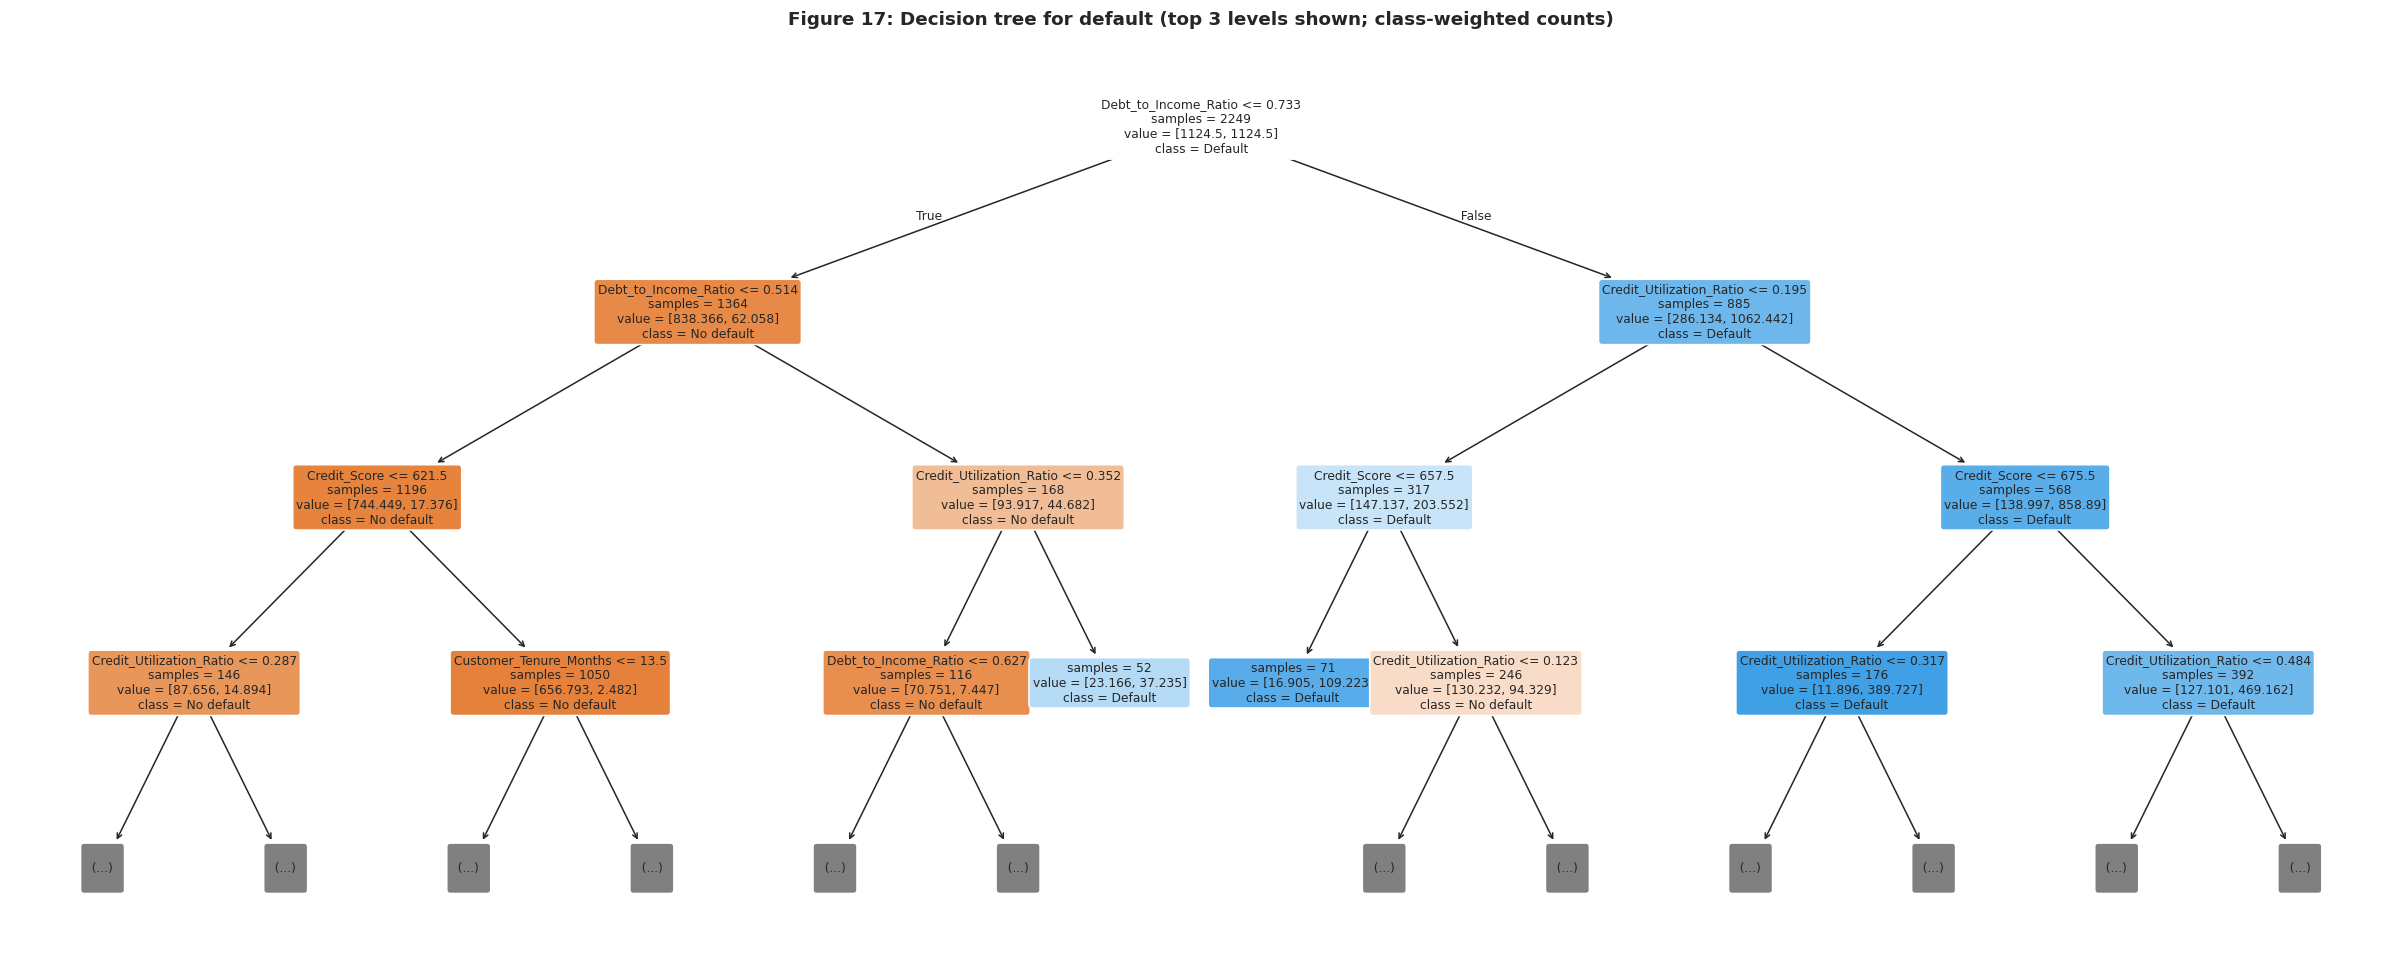

|--- Debt_to_Income_Ratio <= 0.733
|   |--- Debt_to_Income_Ratio <= 0.514
|   |   |--- Credit_Score <= 621.500
|   |   |   |--- Credit_Utilization_Ratio <= 0.287
|   |   |   |   |--- class: 0
|   |   |   |--- Credit_Utilization_Ratio >  0.287
|   |   |   |   |--- class: 0
|   |   |--- Credit_Score >  621.500
|   |   |   |--- Customer_Tenure_Months <= 13.500
|   |   |   |   |--- class: 0
|   |   |   |--- Customer_Tenure_Months >  13.500
|   |   |   |   |--- class: 0
|   |--- Debt_to_Income_Ratio >  0.514
|   |   |--- Credit_Utilization_Ratio <= 0.352
|   |   |   |--- Debt_to_Income_Ratio <= 0.627
|   |   |   |   |--- class: 0
|   |   |   |--- Debt_to_Income_Ratio >  0.627
|   |   |   |   |--- class: 0
|   |   |--- Credit_Utilization_Ratio >  0.352
|   |   |   |--- class: 1
|--- Debt_to_Income_Ratio >  0.733
|   |--- Credit_Utilization_Ratio <= 0.195
|   |   |--- Credit_Score <= 657.500
|   |   |   |--- class: 1
|   |   |--- Credit_Score >  657.500
|   |   |   |--- Credit_Utilization_Rat

,Importance
Debt_to_Income_Ratio,0.7998
Credit_Utilization_Ratio,0.1174
Credit_Score,0.0706
EMI_Amount_INR,0.0086
Customer_Tenure_Months,0.0035
Average_Monthly_Spend_INR,0.0001


,Rule,Train records,Train default rate %
14,Debt_to_Income_Ratio > 0.733 AND Credit_Utiliz...,57,100.0000
13,Debt_to_Income_Ratio > 0.733 AND Credit_Utiliz...,50,92.0000
18,Debt_to_Income_Ratio > 0.733 AND Credit_Utiliz...,66,81.8000
12,Debt_to_Income_Ratio > 0.733 AND Credit_Utiliz...,69,78.3000
7,Debt_to_Income_Ratio > 0.733 AND Credit_Utiliz...,71,62.0000
17,Debt_to_Income_Ratio > 0.733 AND Credit_Utiliz...,170,52.9000
16,Debt_to_Income_Ratio > 0.733 AND Credit_Utiliz...,102,33.3000
11,Debt_to_Income_Ratio > 0.733 AND Credit_Utiliz...,69,31.9000
6,Debt_to_Income_Ratio <= 0.733 AND Debt_to_Inco...,52,28.8000
15,Debt_to_Income_Ratio > 0.733 AND Credit_Utiliz...,54,20.4000


In [31]:
dt_gs = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                     {"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [10, 25, 50, 100]},
                     cv=gkf, scoring="roc_auc").fit(Xtr_t, ytr_d, groups=groups_train)
dt = dt_gs.best_estimator_; p_dt = dt.predict_proba(Xte_t)[:, 1]
print(f"Best params: {dt_gs.best_params_}; CV ROC-AUC = {dt_gs.best_score_:.3f}; leaves = {dt.get_n_leaves()}")
m_dt = clf_metrics("Decision Tree", yte_d, p_dt); print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in m_dt.items()})
print(f"Train ROC-AUC = {roc_auc_score(ytr_d, dt.predict_proba(Xtr_t)[:, 1]):.3f} (overfitting check)")

plt.figure(figsize=(22, 9))
plot_tree(dt, feature_names=X_tree.columns, class_names=["No default", "Default"], filled=True, rounded=True,
          impurity=False, proportion=False, max_depth=3, fontsize=8)
plt.title("Figure 17: Decision tree for default (top 3 levels shown; class-weighted counts)"); savefig("F17_decision_tree")

# Extract every leaf as a readable rule with its actual (unweighted) training default rate
tr_ = dt.tree_; leaf_id = dt.apply(Xtr_t)
def paths(node=0, cond=()):
    if tr_.children_left[node] == -1:
        yield node, cond; return
    f, t = X_tree.columns[tr_.feature[node]], tr_.threshold[node]
    yield from paths(tr_.children_left[node], cond + (f"{f} <= {t:,.3f}",))
    yield from paths(tr_.children_right[node], cond + (f"{f} > {t:,.3f}",))
rules = []
for leaf, cond in paths():
    mask = leaf_id == leaf
    rules.append({"Rule": " AND ".join(cond), "Train records": int(mask.sum()), "Train default rate %": round(ytr_d[mask].mean()*100, 1)})
rules = pd.DataFrame(rules).sort_values("Train default rate %", ascending=False)
save_table(rules, "T12a_tree_rules", index=False)
dt_imp = pd.Series(dt.feature_importances_, index=X_tree.columns).sort_values(ascending=False)
dt_imp = dt_imp[dt_imp > 0].round(4).to_frame("Importance")
save_table(dt_imp, "T12b_tree_importance")
print(export_text(dt, feature_names=list(X_tree.columns), decimals=3))
display(dt_imp); rules

**Method.** Depth and leaf size tuned by grouped CV on ROC-AUC. Selected: max_depth = 6, min_samples_leaf = 50 (19 leaves). Train AUC is 0.948 vs test 0.923, a small gap, so overfitting is controlled.

**Result.** Test accuracy 0.804, precision 0.487, **recall 0.914**, ROC-AUC 0.923. Importance: DTI 0.80, utilisation 0.12, credit score 0.07.

**Banking rules (thresholds exactly as learned; default rates are actual training rates):**
1. **DTI ≤ 0.514 and credit score > 621.5 and tenure > 13.5 months** → 1,000 records, **0.0% default**. This is the safe zone.
2. **DTI > 0.733 and utilisation > 0.195 and score ≤ 675.5 and utilisation > 0.317** → 107 records, **92–100% default**.
3. **DTI > 0.733 and utilisation > 0.484** (score > 675.5) → 81.8% default. A good bureau score does not offset maxed-out credit lines.
4. **DTI 0.514–0.733 with utilisation > 0.352** → 28.8% default. This is a mid-burden early-warning pocket.
5. **DTI > 0.733 but utilisation ≤ 0.123, score > 657.5** → 3.5–12.1% default. High burden alone is survivable when revolving credit is barely used.

### 8.4 Random forest

Best params: {'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 5}; CV ROC-AUC = 0.935
Train ROC-AUC = 0.993
{'Model': 'Random Forest', 'Accuracy': 0.8628, 'Precision': 0.5989, 'Recall': 0.8, 'F1': 0.685, 'ROC_AUC': 0.9361}


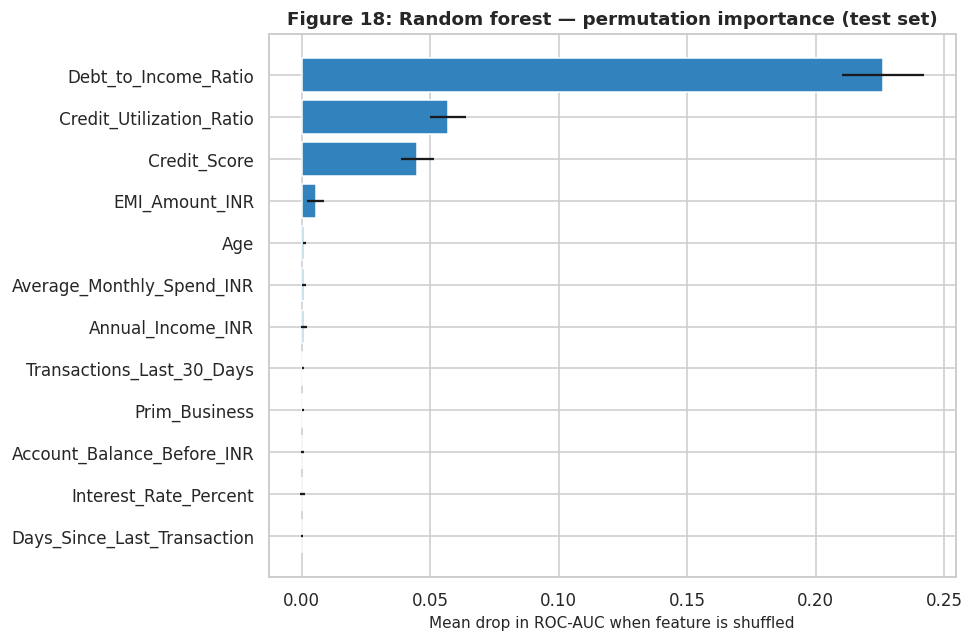

,Gini importance,Permutation importance (AUC drop),Permutation SD
Debt_to_Income_Ratio,0.3857,0.2262,0.0161
Credit_Utilization_Ratio,0.1028,0.0569,0.0071
Credit_Score,0.0793,0.0450,0.0064
EMI_Amount_INR,0.1585,0.0054,0.0033
Age,0.0141,0.0010,0.0006
Average_Monthly_Spend_INR,0.0176,0.0009,0.0006
Annual_Income_INR,0.0199,0.0009,0.0013
Transactions_Last_30_Days,0.0087,0.0006,0.0003
Prim_Business,0.0022,0.0006,0.0005
Account_Balance_Before_INR,0.0162,0.0003,0.0007


In [32]:
rf_gs = GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
                     {"max_depth": [4, 6, 8, 12], "min_samples_leaf": [5, 10, 20], "max_features": ["sqrt", 0.5]},
                     cv=gkf, scoring="roc_auc", n_jobs=1).fit(Xtr_t, ytr_d, groups=groups_train)
rf = rf_gs.best_estimator_; p_rf = rf.predict_proba(Xte_t)[:, 1]
print(f"Best params: {rf_gs.best_params_}; CV ROC-AUC = {rf_gs.best_score_:.3f}")
print(f"Train ROC-AUC = {roc_auc_score(ytr_d, rf.predict_proba(Xtr_t)[:, 1]):.3f}")
m_rf = clf_metrics("Random Forest", yte_d, p_rf); print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in m_rf.items()})
perm = permutation_importance(rf, Xte_t, yte_d, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE)
rf_imp = pd.DataFrame({"Gini importance": rf.feature_importances_, "Permutation importance (AUC drop)": perm.importances_mean,
                       "Permutation SD": perm.importances_std}, index=X_tree.columns).sort_values("Permutation importance (AUC drop)", ascending=False).round(4)
save_table(rf_imp, "T12c_rf_importance")
fig, ax = plt.subplots(figsize=(9, 6))
top_rf = rf_imp.head(12)[::-1]
ax.barh(top_rf.index, top_rf["Permutation importance (AUC drop)"], xerr=top_rf["Permutation SD"], color="#3182bd")
ax.set(title="Figure 18: Random forest — permutation importance (test set)", xlabel="Mean drop in ROC-AUC when feature is shuffled", ylabel="")
savefig("F18_rf_importance")
rf_imp.head(15)

**Method.** 300 trees with balanced class weights. max_depth, min_samples_leaf and max_features tuned by grouped 5-fold CV (best: depth 12, leaf 5, max_features 0.5). Importance is measured by permutation on the **test set**, which is less biased than Gini importance toward continuous variables.

**Result.** Test accuracy **0.863**, precision **0.599**, recall 0.800, F1 0.685, ROC-AUC **0.936**. The train AUC of 0.993 is higher, but the CV AUC (0.935) matches test, so generalisation holds.

**Permutation importance (AUC drop):** DTI 0.226, utilisation 0.057, credit score 0.045, EMI 0.005. Everything else is < 0.001. Gini ranks EMI second (0.159) because it is collinear with DTI, but permutation shows it adds little once DTI is known.

### 8.5 Classification model comparison

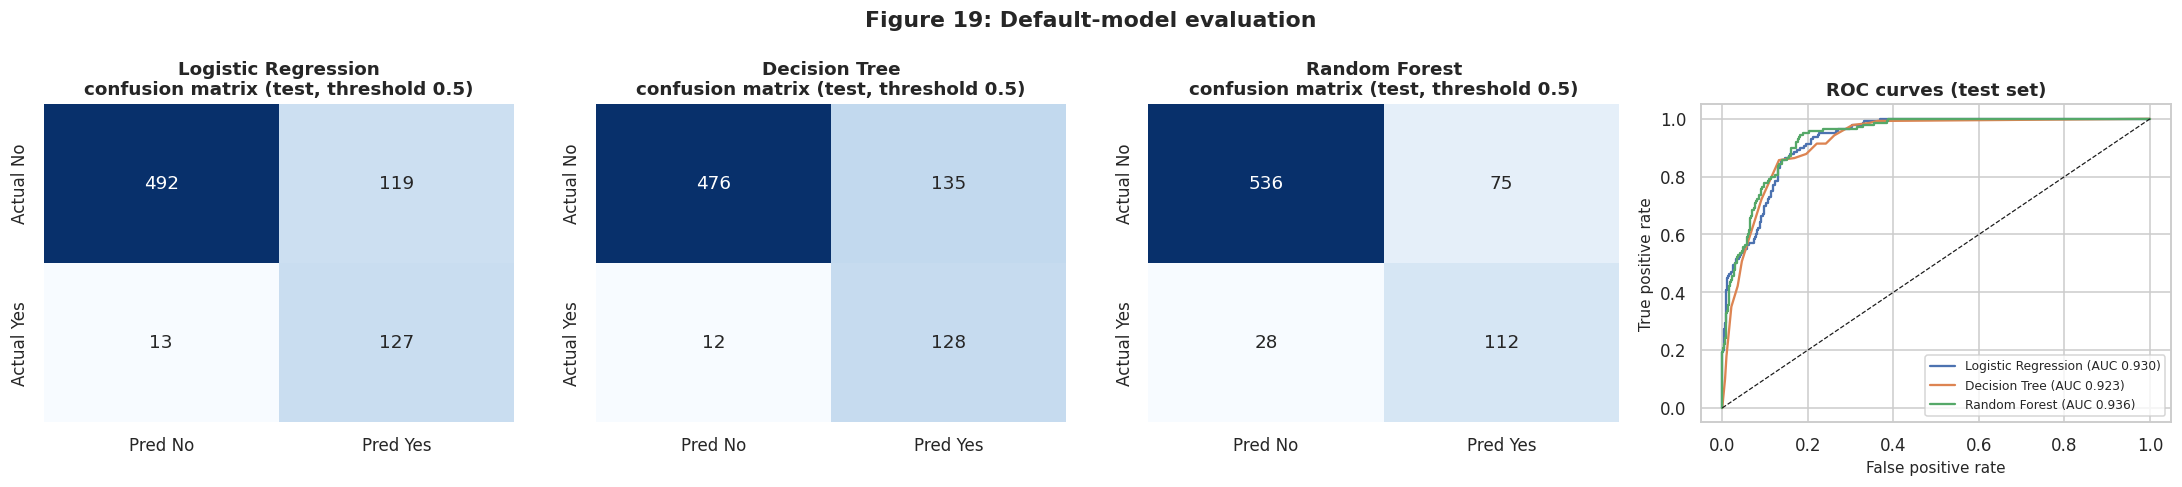

Confusion matrix cells (TN, FP, FN, TP): {'LR': [492, 119, 13, 127], 'DT': [476, 135, 12, 128], 'RF': [536, 75, 28, 112]}


,Accuracy,Precision,Recall,F1,ROC_AUC,CV ROC-AUC (train folds)
Model,,,,,,
Logistic Regression,0.8242,0.5163,0.9071,0.6580,0.9301,0.9336
Decision Tree,0.8043,0.4867,0.9143,0.6352,0.9226,0.9240
Random Forest,0.8628,0.5989,0.8000,0.6850,0.9361,0.9347


In [33]:
clf_cmp = pd.DataFrame([m_lr, m_dt, m_rf]).set_index("Model").round(4)
clf_cmp["CV ROC-AUC (train folds)"] = [round(lr_gs.best_score_, 4), round(dt_gs.best_score_, 4), round(rf_gs.best_score_, 4)]
save_table(clf_cmp, "T13_classification_comparison")
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for (nm, pr), a in zip([("Logistic Regression", p_lr), ("Decision Tree", p_dt), ("Random Forest", p_rf)], ax[:3]):
    cm = confusion_matrix(yte_d, (pr >= .5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=["Pred No", "Pred Yes"], yticklabels=["Actual No", "Actual Yes"])
    a.set_title(f"{nm}\nconfusion matrix (test, threshold 0.5)")
for nm, pr in [("Logistic Regression", p_lr), ("Decision Tree", p_dt), ("Random Forest", p_rf)]:
    fpr, tpr, _ = roc_curve(yte_d, pr); ax[3].plot(fpr, tpr, label=f"{nm} (AUC {roc_auc_score(yte_d, pr):.3f})")
ax[3].plot([0, 1], [0, 1], "k--", lw=.8); ax[3].set(title="ROC curves (test set)", xlabel="False positive rate", ylabel="True positive rate"); ax[3].legend(fontsize=8)
fig.suptitle("Figure 19: Default-model evaluation", fontweight="bold"); savefig("F19_classification_eval")
cms = {nm: confusion_matrix(yte_d, (pr >= .5).astype(int)).ravel() for nm, pr in [("LR", p_lr), ("DT", p_dt), ("RF", p_rf)]}
print("Confusion matrix cells (TN, FP, FN, TP):", {k: v.tolist() for k, v in cms.items()})
clf_cmp

**Comparison (test set, threshold 0.5):**
* **Random forest:** highest AUC (0.936), accuracy (0.863), precision (0.599) and F1 (0.685). Confusion matrix: 112 of 140 defaulters caught, 75 false alarms.
* **Decision tree:** highest recall (0.914, 128 caught, only 12 missed) but 135 false alarms. Fully transparent rules.
* **Logistic regression:** AUC 0.930 and recall 0.907, and gives odds ratios for policy communication.

**Choice.** Use the **random forest for ranking and monitoring** (fewest false alarms, so relationship-manager effort is not wasted). Use the **decision-tree rules as the underwriting policy** (explainable to credit committees and regulators). Use **logistic regression to quantify and communicate driver effects**. The three models agree on the same three drivers, which strengthens confidence in them.

### 8.6 Robustness: default model within loan holders only

In [34]:
lh_tr = (df_clean.Has_Loan.iloc[train_idx] == 1).values; lh_te = (df_clean.Has_Loan.iloc[test_idx] == 1).values
rf_lh = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, **rf_gs.best_params_)
rf_lh.fit(Xtr_t[lh_tr], ytr_d[lh_tr])
auc_lh = roc_auc_score(yte_d[lh_te], rf_lh.predict_proba(Xte_t[lh_te])[:, 1])
auc_lh_full = roc_auc_score(yte_d[lh_te], p_rf[lh_te])
print(f"Loan holders in test: {lh_te.sum()}, default rate {yte_d[lh_te].mean()*100:.1f}%")
print(f"ROC-AUC among loan holders: RF trained on loan holders = {auc_lh:.3f}; main RF = {auc_lh_full:.3f}")

Loan holders in test: 437, default rate 31.1%
ROC-AUC among loan holders: RF trained on loan holders = 0.890; main RF = 0.886


**Result.** Since non-borrowers almost never default (0.57%), part of the headline AUC comes from simply separating borrowers from non-borrowers. **Among loan holders only** (437 test records, 31.1% default), the AUC is still **0.886–0.890**. The model therefore genuinely ranks risk *within* the lending book, not just loan vs no loan.

## 9. Integrated Analysis — Segment × Profitability × Default Risk

Out-of-fold RF ROC-AUC on all 3,000 records: 0.939


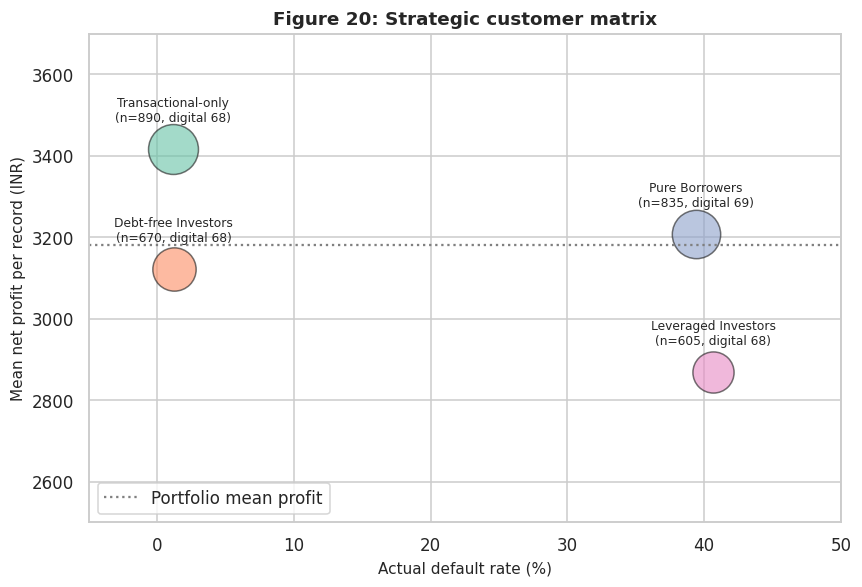

Records  Default_Rate_pct  Mean_Net_Profit_INR  Median_Outstanding_INR
Segment_Name        Risk_Tier                                                                                            
Debt-free Investors Debt_to_Income_Ratio <= 0.733      136            5.1000           2,675.8000            987,152.6000
Leveraged Investors Debt_to_Income_Ratio <= 0.733      115            5.2000           2,615.0000          3,520,475.2000
                    Debt_to_Income_Ratio > 0.733       490           49.0000           2,927.5000          6,455,073.7000
Pure Borrowers      Debt_to_Income_Ratio <= 0.733      160            7.5000           2,983.6000          4,320,692.3000
                    Debt_to_Income_Ratio > 0.733       675           47.0000           3,260.5000          6,279,578.2000
Transactional-only  Debt_to_Income_Ratio <= 0.733      196            1.0000           3,707.6000            996,985.9000

Segment_Name,Transactional-only,Debt-free Investors,Pure Borrowers,Leveraged Investors
Records,890.0000,670.0000,835.0000,605.0000
Mean_Net_Profit_INR,"3,417.6300","3,122.5200","3,207.4400","2,868.1300"
Total_Net_Profit_INR,"3,041,694.8200","2,092,085.7600","2,678,214.6200","1,735,217.1900"
Loss_Making_pct,27.3000,29.1000,28.2600,32.8900
Default_Rate_pct,1.1200,1.1900,39.4000,40.6600
Mean_RF_Risk_Score,0.0200,0.0200,0.5000,0.5000
Digital_Score,68.1600,67.5400,68.5300,67.5200
Median_Income_INR,"871,989.0000","919,137.5000","803,339.0000","787,365.0000"
Credit_Score,721.7000,721.2200,716.7500,726.7700
DTI,0.2100,0.2000,0.8600,0.8700


In [35]:
# Out-of-fold random-forest default probabilities for every record (customer-grouped 5-fold CV, tuned parameters)
rf_oof = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, **rf_gs.best_params_)
df_clean["PD_RF_oof"] = cross_val_predict(rf_oof, X_tree, yd, cv=gkf, groups=df_clean.Customer_ID, method="predict_proba")[:, 1]
print(f"Out-of-fold RF ROC-AUC on all 3,000 records: {roc_auc_score(yd, df_clean.PD_RF_oof):.3f}")

seg = df_clean.groupby("Segment_Name").agg(
    Records=("Age", "size"), Mean_Net_Profit_INR=("Net_Profit_INR", "mean"), Total_Net_Profit_INR=("Net_Profit_INR", "sum"),
    Loss_Making_pct=("Net_Profit_INR", lambda s: (s < 0).mean()*100), Default_Rate_pct=("Default", lambda s: s.mean()*100),
    Mean_RF_Risk_Score=("PD_RF_oof", "mean"), Digital_Score=("Digital_Engagement_Score", "mean"),
    Median_Income_INR=("Annual_Income_INR", "median"), Credit_Score=("Credit_Score", "mean"), DTI=("Debt_to_Income_Ratio", "mean"),
    Median_Investment_INR=("Investment_Value_INR", "median"), Median_CLV_INR=("Customer_Lifetime_Value_INR", "median"),
    Total_Outstanding_Loan_Cr=("Outstanding_Loan_INR", lambda s: s.sum()/1e7))
seg["Share_of_Records_pct"] = seg.Records/seg.Records.sum()*100
seg["Share_of_Profit_pct"] = seg.Total_Net_Profit_INR/seg.Total_Net_Profit_INR.sum()*100
seg["Share_of_Defaults_pct"] = df_clean.groupby("Segment_Name").Default.sum()/df_clean.Default.sum()*100
seg = seg.sort_values("Default_Rate_pct").round(2)
save_table(seg, "T14_integrated_segment_matrix")

# Risk tiers inside the two borrower segments, using the first split learned by the decision tree
first_thr = dt.tree_.threshold[0]; first_feat = X_tree.columns[dt.tree_.feature[0]]
bor = df_clean[df_clean.Has_Loan == 1].copy()
bor["Risk_Tier"] = np.where(bor[first_feat] > first_thr, f"{first_feat} > {first_thr:.3f}", f"{first_feat} <= {first_thr:.3f}")
tier = bor.groupby(["Segment_Name", "Risk_Tier"]).agg(Records=("Age", "size"), Default_Rate_pct=("Default", lambda s: s.mean()*100),
        Mean_Net_Profit_INR=("Net_Profit_INR", "mean"), Median_Outstanding_INR=("Outstanding_Loan_INR", "median")).round(1)
tier = tier[tier.Records >= 30]
save_table(tier, "T14b_borrower_risk_tiers")

fig, ax = plt.subplots(figsize=(8, 5.5))
for nm, r in seg.iterrows():
    ax.scatter(r.Default_Rate_pct, r.Mean_Net_Profit_INR, s=r.Records*1.2, alpha=.6, color=pal[nm], edgecolor="k")
    ax.annotate(f"{nm}\n(n={int(r.Records)}, digital {r.Digital_Score:.0f})", (r.Default_Rate_pct, r.Mean_Net_Profit_INR),
                textcoords="offset points", xytext=(0, 18), ha="center", fontsize=8)
ax.axhline(df_clean.Net_Profit_INR.mean(), color="grey", ls=":", label="Portfolio mean profit")
ax.set(title="Figure 20: Strategic customer matrix", xlabel="Actual default rate (%)", ylabel="Mean net profit per record (INR)",
       xlim=(-5, 50), ylim=(2500, 3700)); ax.legend(loc="lower left")
savefig("F20_strategic_matrix")
display(tier); seg.T

**Central managerial insight: the strategic customer matrix.**

| Segment | Share of records | Share of profit | Share of defaults | Default | Digital | Strategic implication |
|---|---|---|---|---|---|---|
| Transactional-only | 29.7% | 31.9% | 1.7% | 1.1% | 68 | Highest mean profit (₹3,418), lowest risk. Protect and service efficiently; pre-screened credit candidates. |
| Debt-free Investors | 22.3% | 21.9% | 1.4% | 1.2% | 68 | Wealth relationship (median ₹26.1 lakh invested). Low risk; 25% of investors have negative returns, so advisory review is needed. |
| Pure Borrowers | 27.8% | 28.1% | **55.5%** | 39.4% | 69 | Holds ₹486.5 Cr of outstanding loans. Risk concentrated where DTI > 0.733 (47.0% default vs 7.5% below it). Priority for monitoring. |
| Leveraged Investors | 20.2% | 18.2% | **41.5%** | 40.7% | 68 | Lowest mean profit (₹2,868), highest loss-making share (32.9%). Holds investments of similar size to their loans, which could support secured structures. |

**Risk tiers inside borrower segments (tree root split DTI > 0.733):** default is 47.0–49.0% above the threshold vs 5.2–7.5% below. Digital engagement is flat (~68) across all segments, so it is not a differentiator.

*Note:* the RF risk score comes from a class-weighted model. It is a **ranking score, not a calibrated probability**, which is why its segment means exceed actual default rates.

## 10. Quantifying decision impact (calculated on the held-out test set only)

In [36]:
te = df_clean.iloc[test_idx].copy(); te["p_rf"] = p_rf; te["p_dt"] = p_dt
n_def = te.Default.sum(); exp_def = te.loc[te.Default == 1, "Outstanding_Loan_INR"].sum()
def policy(mask, name):
    return {"Policy": name, "Records flagged": int(mask.sum()), "Share of test records %": mask.mean()*100,
            "Defaults captured": int(te.Default[mask].sum()), "Share of all defaults captured %": te.Default[mask].sum()/n_def*100,
            "Default rate among flagged %": te.Default[mask].mean()*100, "Non-defaulters flagged": int((te.Default[mask] == 0).sum()),
            "Outstanding of captured defaulters (INR Cr)": te.loc[mask & (te.Default == 1), "Outstanding_Loan_INR"].sum()/1e7,
            "Share of defaulter outstanding captured %": te.loc[mask & (te.Default == 1), "Outstanding_Loan_INR"].sum()/exp_def*100}
pol = pd.DataFrame([policy(te[first_feat] > first_thr, f"Tree root rule: {first_feat} > {first_thr:.3f}"),
                    policy(te.p_dt >= .5, "Decision tree (threshold 0.5)"),
                    policy(te.p_rf >= .5, "Random forest (threshold 0.5)"),
                    policy(te.p_rf >= .7, "Random forest (threshold 0.7, stricter)")]).round(2)
save_table(pol, "T15_policy_impact", index=False)

cmp_ = df_clean.assign(Complaints=np.where(df_clean.Complaint_Count >= 2, "2+", df_clean.Complaint_Count.astype(str))).groupby("Complaints").agg(
    Records=("Age", "size"), Mean_Cost_to_Serve_INR=("Cost_to_Serve_INR", "mean"), Mean_Net_Profit_INR=("Net_Profit_INR", "mean"),
    Loss_Making_pct=("Net_Profit_INR", lambda s: (s < 0).mean()*100)).round(1)
save_table(cmp_, "T16_complaints_profit")
print(f"Test set: {len(te)} records, {n_def} defaults, defaulter outstanding INR {exp_def/1e7:.2f} Cr")
display(pol); cmp_

Test set: 751 records, 140 defaults, defaulter outstanding INR 81.80 Cr


,Policy,Records flagged,Share of test records %,Defaults captured,Share of all defaults captured %,Default rate among flagged %,Non-defaulters flagged,Outstanding of captured defaulters (INR Cr),Share of defaulter outstanding captured %
0,Tree root rule: Debt_to_Income_Ratio > 0.733,286,38.0800,131,93.5700,45.8000,155,79.9600,97.7500
1,Decision tree (threshold 0.5),263,35.0200,128,91.4300,48.6700,135,78.3200,95.7500
2,Random forest (threshold 0.5),187,24.9000,112,80.0000,59.8900,75,70.0900,85.6800
3,"Random forest (threshold 0.7, stricter)",116,15.4500,81,57.8600,69.8300,35,51.9800,63.5400


,Records,Mean_Cost_to_Serve_INR,Mean_Net_Profit_INR,Loss_Making_pct
Complaints,,,,
0,1603,"4,091.3000","3,464.7000",27.8000
1,1021,"4,584.9000","3,031.4000",29.7000
2+,376,"4,990.7000","2,389.1000",33.2000


**Calculated impact (held-out test set of 751 records, 140 defaults, ₹81.8 Cr outstanding with defaulters):**
* **Tree root rule (DTI > 0.733):** flags 38.1% of records and captures 93.6% of defaults, covering 97.8% of defaulter outstanding (₹80.0 Cr). But 155 non-defaulters are also flagged.
* **Random forest at 0.5:** flags 24.9% and captures 80.0% of defaults (85.7% of defaulter outstanding, ₹70.1 Cr) with 75 false alarms. That is 60% precision, three times the base rate.
* **Random forest at 0.7:** flags 15.4% and captures 57.9% of defaults at 69.8% precision.

**Complaints:** mean net profit falls from ₹3,465 (0 complaints) to ₹3,031 (1) and ₹2,389 (2+). Loss-making share rises from 27.8% to 33.2%.

These are *identification* rates on historical data. The rupee value actually saved would depend on recovery rates and actions taken, which are not in the dataset, so no loss-avoidance figure is claimed.

## 11. Export key outputs

In [37]:
df_clean.to_csv("tables/df_clean_with_segments.csv", index=False)
print("Tables saved:", sorted(os.listdir("tables")))
print("Figures saved:", sorted(os.listdir("figs")))

Tables saved: ['T01_dataset_summary.csv', 'T02_variable_dictionary.csv', 'T02b_customer_id_consistency.csv', 'T02c_leakage_checks.csv', 'T02d_credit_risk_category_vs_default.csv', 'T03_missing_values.csv', 'T03b_loan_missing_check.csv', 'T04_descriptive_stats.csv', 'T04b_outliers.csv', 'T05a_segment_profile.csv', 'T05b_products_held.csv', 'T05c_transaction_type.csv', 'T05d_digital_corr.csv', 'T05e_default_mannwhitney.csv', 'T05f_default_chisq.csv', 'T05g_investment_corr.csv', 'T05h_profit_kruskal.csv', 'T06_top_correlations.csv', 'T07a_fa_stage1_loadings.csv', 'T07b_kmo.csv', 'T07c_bartlett.csv', 'T07d_factor_loadings.csv', 'T07e_factor_variance.csv', 'T08a_k_selection.csv', 'T08b_cluster_profiles.csv', 'T08c_cluster_tests.csv', 'T09a_profit_vif.csv', 'T09b_ols_coefficients.csv', 'T10a_regression_comparison.csv', 'T10b_ridge_lasso_coefficients.csv', 'T10c_clv_significant.csv', 'T11a_default_class_distribution.csv', 'T11b_logit_coefficients.csv', 'T12a_tree_rules.csv', 'T12b_tree_import

## 12. Notebook conclusion
* **Data:** 3,000 records, no duplicates; `Loan_Product` blanks = "No Loan"; Customer_ID is not a consistent customer key, so the analysis is record-level with customer-grouped validation.
* **Leakage removed:** Default_Probability, Credit_Risk_Category, Revenue, Cost_to_Serve, Profitability_Score; Target_Churn is single-class and not modelled.
* **Factor analysis:** two factors — Credit Burden and Investment Depth (KMO 0.729, 79% variance); behavioural/digital variables share no common variance.
* **Clustering:** four segments (silhouette 0.62) that differ sharply in default (1.1% to 40.7%) but not in profit.
* **Profitability:** not predictable from customer attributes (test R² ≈ 0); complaints are the only consistent negative driver (−₹443 per complaint).
* **Default:** DTI, credit utilisation and credit score drive default; random forest ROC-AUC 0.936, decision tree recall 0.914, logistic AUC 0.930.